In [1]:
# 1. Imports and configuration
import os
import gc
import time
import random
import zipfile
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_recall_fscore_support)

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 8
FEATURE_EPOCHS = 3
FINETUNE_EPOCHS = 2
OUTPUT_DIR = "/kaggle/working/lab8_attention_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Output directory:", OUTPUT_DIR)


TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Output directory: /kaggle/working/lab8_attention_outputs


In [2]:
print("GPU devices:", tf.config.list_physical_devices("GPU"))


GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [3]:
print("Output folder:", os.path.abspath(OUTPUT_DIR))

Output folder: /kaggle/working/lab8_attention_outputs


In [4]:
# Training settings

print(f"Image size: {IMG_SIZE} x {IMG_SIZE}")


Image size: 224 x 224


In [5]:
print(f"Batch size: {BATCH_SIZE}")


Batch size: 8


In [6]:
print(f"Feature-extraction epochs per model: {FEATURE_EPOCHS}")


Feature-extraction epochs per model: 3


In [7]:
print(f"Fine-tuning epochs per model: {FINETUNE_EPOCHS}")


Fine-tuning epochs per model: 2


In [8]:
print(f"Random seed: {SEED}")

Random seed: 42


In [9]:
# 2. Load the dataset and create pipelines

(train_raw, val_raw, test_raw), dataset_info = tfds.load(
    "tf_flowers",
    split=["train[:70%]", "train[70%:85%]", "train[85%:]"],
    as_supervised=True, with_info=True
)


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.HBRPOI_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.


I0000 00:00:1792267614.569145     132 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792267614.571985     132 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [10]:
CLASS_NAMES = dataset_info.features["label"].names


In [11]:
print("Classes:", CLASS_NAMES, "| Total images:", dataset_info.splits["train"].num_examples)


Classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses'] | Total images: 3670


In [12]:
def preprocess_image(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)
    image = keras.applications.resnet50.preprocess_input(image)
    return image, tf.one_hot(tf.cast(label, tf.int32), NUM_CLASSES)


In [13]:
def make_ds(raw, training=False):
    ds = raw.map(preprocess_image, num_parallel_calls=2)
    if training:
        ds = ds.shuffle(500, seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(1)


In [14]:
# Check dataset pipeline dependencies
print("preprocess_image:", "preprocess_image" in globals())
print("NUM_CLASSES:", globals().get("NUM_CLASSES", "MISSING"))
print("IMG_SIZE:", globals().get("IMG_SIZE", "MISSING"))
print("SEED:", globals().get("SEED", "MISSING"))
print("BATCH_SIZE:", globals().get("BATCH_SIZE", "MISSING"))
print("tf:", "tf" in globals())
print("keras:", "keras" in globals())

preprocess_image: True
NUM_CLASSES: MISSING
IMG_SIZE: 224
SEED: 42
BATCH_SIZE: 8
tf: True
keras: True


In [15]:
# Dataset configuration
NUM_CLASSES = 5

In [16]:
# Create datasets
train_ds = make_ds(train_raw, training=True)
val_ds = make_ds(val_raw)
test_ds = make_ds(test_raw)

In [17]:
val_ds = make_ds(val_raw)


In [18]:
test_ds = make_ds(test_raw)


In [19]:
plt.figure(figsize=(12, 7))


<Figure size 1200x700 with 0 Axes>

<Figure size 1200x700 with 0 Axes>

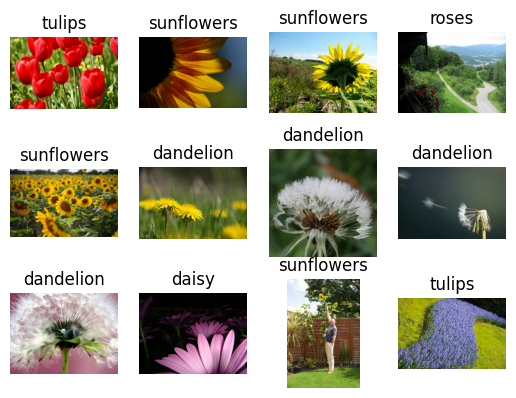

In [20]:
for i, (im, lab) in enumerate(train_raw.take(12)):
    plt.subplot(3, 4, i+1)
    plt.imshow(im.numpy()); plt.title(CLASS_NAMES[int(lab.numpy())]); plt.axis("off")


In [21]:
plt.tight_layout()


<Figure size 640x480 with 0 Axes>

In [22]:
plt.savefig(os.path.join(OUTPUT_DIR, "00_sample_images.png"), dpi=160, bbox_inches="tight")


<Figure size 640x480 with 0 Axes>

In [23]:
plt.show()

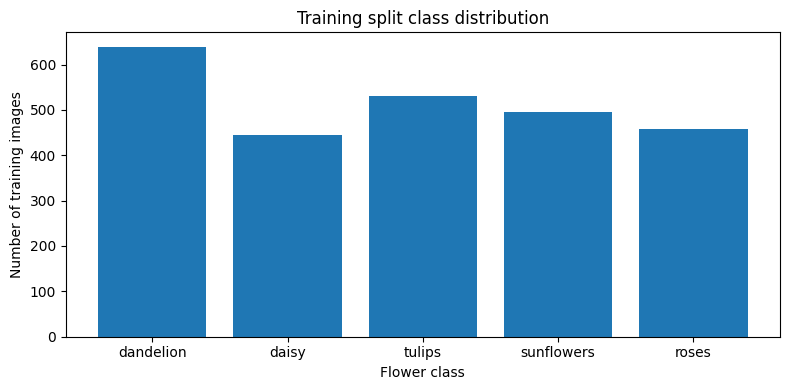

Training class counts: {'dandelion': 639, 'daisy': 445, 'tulips': 531, 'sunflowers': 496, 'roses': 458}


In [24]:
# 3. Dataset class distribution
_class_counts = np.zeros(len(CLASS_NAMES), dtype=int)
for _, _label in train_raw:
    _class_counts[int(_label.numpy())] += 1
plt.figure(figsize=(8, 4))
plt.bar(CLASS_NAMES, _class_counts)
plt.xlabel("Flower class"); plt.ylabel("Number of training images")
plt.title("Training split class distribution")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "required_class_distribution.png"), dpi=160, bbox_inches="tight")
plt.show(); plt.close()
print("Training class counts:", dict(zip(CLASS_NAMES, _class_counts.tolist())))


In [25]:
# Inspect the class names and split sizes

print("Class names:", CLASS_NAMES)


Class names: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']


In [26]:
print("Training examples:", dataset_info.splits["train"].num_examples)


Training examples: 3670


In [27]:
print("Train pipeline batches:", tf.data.experimental.cardinality(train_ds).numpy())


Train pipeline batches: 322


In [28]:
print("Validation pipeline batches:", tf.data.experimental.cardinality(val_ds).numpy())


Validation pipeline batches: 69


In [29]:
print("Test pipeline batches:", tf.data.experimental.cardinality(test_ds).numpy())

Test pipeline batches: 69


In [30]:
# Check one preprocessed batch

sample_images, sample_labels = next(iter(train_ds))


In [31]:
print("Image batch shape:", sample_images.shape)


Image batch shape: (8, 224, 224, 3)


In [32]:
print("Label batch shape:", sample_labels.shape)


Label batch shape: (8, 5)


In [33]:
print("Image dtype:", sample_images.dtype)


Image dtype: <dtype: 'float32'>


In [34]:
print("Label dtype:", sample_labels.dtype)

Label dtype: <dtype: 'float32'>


In [35]:
# View the preprocessed images

plt.figure(figsize=(10, 6))


<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

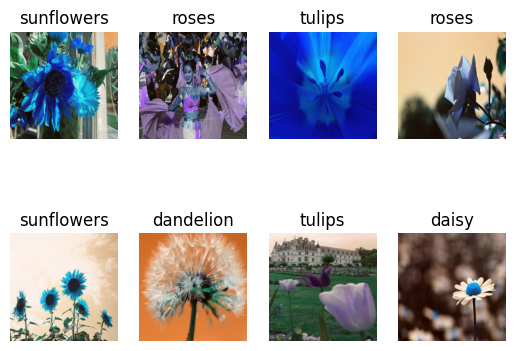

In [36]:
for i in range(min(8, sample_images.shape[0])):
    plt.subplot(2, 4, i + 1)
    image = sample_images[i].numpy()
    image = image - image.min()
    image = image / max(image.max(), 1e-8)
    plt.imshow(image)
    plt.title(CLASS_NAMES[int(tf.argmax(sample_labels[i]).numpy())])
    plt.axis("off")


In [37]:
plt.tight_layout()


<Figure size 640x480 with 0 Axes>

In [38]:
plt.show()

In [39]:
# 3. Attention modules

def channel_attention(x, reduction=16, name="channel_attention"):
    channels = int(x.shape[-1])
    hidden = max(channels // reduction, 8)
    avg = layers.GlobalAveragePooling2D(keepdims=True, name=f"{name}_gap")(x)
    z = layers.Conv2D(hidden, 1, activation="relu", name=f"{name}_reduce")(avg)
    z = layers.Conv2D(channels, 1, activation="sigmoid", name=f"{name}_expand")(z)
    return layers.Multiply(name=f"{name}_scale")([x, z])


In [40]:
def spatial_attention(x, kernel_size=7, name="spatial_attention"):
    avg = layers.Lambda(lambda t: tf.reduce_mean(t, axis=-1, keepdims=True), name=f"{name}_avg")(x)
    mx = layers.Lambda(lambda t: tf.reduce_max(t, axis=-1, keepdims=True), name=f"{name}_max")(x)
    z = layers.Concatenate(axis=-1, name=f"{name}_concat")([avg, mx])
    z = layers.Conv2D(1, kernel_size, padding="same", activation="sigmoid",
                      use_bias=False, name=f"{name}_map")(z)
    return layers.Multiply(name=f"{name}_scale")([x, z])


In [41]:
def self_attention(x, name="self_attention"):
    # Lightweight spatial self-attention with a reduced embedding dimension.
    shape = x.shape
    h, w, c = int(shape[1]), int(shape[2]), int(shape[3])
    n = h * w
    d = max(min(c // 8, 128), 16)
    flat = layers.Reshape((n, c), name=f"{name}_flatten")(x)
    q = layers.Dense(d, use_bias=False, name=f"{name}_query")(flat)
    k = layers.Dense(d, use_bias=False, name=f"{name}_key")(flat)
    v = layers.Dense(d, use_bias=False, name=f"{name}_value")(flat)
    scores = layers.Lambda(lambda z: tf.matmul(z[0], z[1], transpose_b=True) / tf.sqrt(tf.cast(d, tf.float32)),
                           name=f"{name}_scores")([q, k])
    weights = layers.Softmax(axis=-1, name=f"{name}_weights")(scores)
    attended = layers.Lambda(lambda z: tf.matmul(z[0], z[1]), name=f"{name}_attended")([weights, v])
    attended = layers.Dense(c, use_bias=False, name=f"{name}_project")(attended)
    attended = layers.Reshape((h, w, c), name=f"{name}_reshape")(attended)
    # Residual connection keeps the original features while adding attended features.
    return layers.Add(name=f"{name}_residual")([x, attended])


In [42]:
def eca_attention(x, name="eca"):
    channels = int(x.shape[-1])
    z = layers.GlobalAveragePooling2D(keepdims=True, name=f"{name}_gap")(x)
    z = layers.Reshape((channels, 1), name=f"{name}_reshape1d")(z)
    z = layers.Conv1D(1, kernel_size=3, padding="same", use_bias=False, name=f"{name}_conv1d")(z)
    z = layers.Activation("sigmoid", name=f"{name}_sigmoid")(z)
    z = layers.Reshape((1, 1, channels), name=f"{name}_reshape4d")(z)
    return layers.Multiply(name=f"{name}_scale")([x, z])


In [43]:
def apply_attention(x, kind, kernel_size=7, name="attn"):
    if kind == "none":
        return x
    if kind in ("channel", "se"):
        return channel_attention(x, name=name)
    if kind == "spatial":
        return spatial_attention(x, kernel_size=kernel_size, name=name)
    if kind == "channel_spatial":
        return spatial_attention(channel_attention(x, name=f"{name}_channel"),
                                 kernel_size=kernel_size, name=f"{name}_spatial")
    if kind == "spatial_channel":
        return channel_attention(spatial_attention(x, kernel_size=kernel_size, name=f"{name}_spatial"),
                                 name=f"{name}_channel")
    if kind == "self":
        return self_attention(x, name=name)
    if kind == "combined":
        x = channel_attention(x, name=f"{name}_channel")
        x = spatial_attention(x, kernel_size=kernel_size, name=f"{name}_spatial")
        return self_attention(x, name=f"{name}_self")
    if kind == "eca":
        return eca_attention(x, name=name)
    if kind == "cbam":
        x = channel_attention(x, name=f"{name}_channel")
        return spatial_attention(x, kernel_size=kernel_size, name=f"{name}_spatial")
    raise ValueError(f"Unknown attention type: {kind}")

In [44]:
# 4. Build ResNet50 with attention inserted at selected stages
# Attention module shape notes

for position, shape in {"P2": (28, 28, 512), "P3": (14, 14, 1024), "P4": (7, 7, 2048)}.items():
    print(f"{position}: {shape[0]} x {shape[1]} x {shape[2]}")

P2: 28 x 28 x 512
P3: 14 x 14 x 1024
P4: 7 x 7 x 2048


In [45]:
# 4. Build ResNet50 with attention inserted at selected stages

def build_resnet50_attention(attention_map=None, kernel_size=7, dropout_rate=0.3,
                             learning_rate=1e-3, return_gradcam=False):
    """Build ImageNet ResNet50 while inserting attention after P2/P3/P4 stages.

    P2 = output of conv3_x (28x28x512), P3 = conv4_x (14x14x1024),
    P4 = conv5_x (7x7x2048). Residual block layers are reused from pretrained ResNet50.
    """
    attention_map = attention_map or {}
    base = keras.applications.ResNet50(
        include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = False
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")

    # Reuse the pretrained stem layers.
    x = inputs
    for layer_name in ["conv1_pad", "conv1_conv", "conv1_bn", "conv1_relu",
                       "pool1_pad", "pool1_pool"]:
        x = base.get_layer(layer_name)(x)

    stage_blocks = {2: 3, 3: 4, 4: 6, 5: 3}
    stage_position = {3: "P2", 4: "P3", 5: "P4"}
    gradcam_features = None
    for stage, n_blocks in stage_blocks.items():
        for block in range(1, n_blocks + 1):
            prefix = f"conv{stage}_block{block}"
            shortcut = x
            # Main residual path.
            x = base.get_layer(f"{prefix}_1_conv")(x)
            x = base.get_layer(f"{prefix}_1_bn")(x)
            x = base.get_layer(f"{prefix}_1_relu")(x)
            x = base.get_layer(f"{prefix}_2_conv")(x)
            x = base.get_layer(f"{prefix}_2_bn")(x)
            x = base.get_layer(f"{prefix}_2_relu")(x)
            x = base.get_layer(f"{prefix}_3_conv")(x)
            x = base.get_layer(f"{prefix}_3_bn")(x)
            # Projection shortcut is used by the first block of each stage.
            if block == 1:
                shortcut = base.get_layer(f"{prefix}_0_conv")(shortcut)
                shortcut = base.get_layer(f"{prefix}_0_bn")(shortcut)
            x = base.get_layer(f"{prefix}_add")([x, shortcut])
            x = base.get_layer(f"{prefix}_out")(x)
            if stage == 5 and block == 3:
                gradcam_features = x

        # Insert requested attention after each selected stage.
        position = stage_position.get(stage)
        if position and position in attention_map:
            x = apply_attention(
                x, attention_map[position], kernel_size=kernel_size,
                name=f"{position.lower()}_{attention_map[position]}"
            )

    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.Dropout(dropout_rate, name="classifier_dropout")(x)
    outputs = layers.Dense(5, activation="softmax", name="predictions")(x)
    if return_gradcam:
        model = keras.Model(inputs, [gradcam_features, outputs], name="ResNet50_GradCAM")
    else:
        model = keras.Model(inputs, outputs, name="ResNet50_Attention")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


In [46]:
# Training functions and plot saving
# 5. Training helper: feature extraction followed by fine-tuning

def save_history_plots(history, exp_name, phase):
    hist = history.history
    ep = np.arange(1, len(hist["loss"]) + 1)
    safe = exp_name.replace("/", "_").replace(" ", "_").replace("+", "plus")
    plt.figure(figsize=(7, 4))
    plt.plot(ep, hist["accuracy"], marker="o", label="Train")
    plt.plot(ep, hist["val_accuracy"], marker="o", label="Validation")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title(f"{exp_name} — {phase} accuracy")
    plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"{safe}_{phase}_accuracy.png"), dpi=160)
    plt.show()
    plt.close()

    plt.figure(figsize=(7, 4))
    plt.plot(ep, hist["loss"], marker="o", label="Train")
    plt.plot(ep, hist["val_loss"], marker="o", label="Validation")
    plt.xlabel("Epoch"); plt.ylabel("Categorical cross-entropy")
    plt.title(f"{exp_name} — {phase} loss"); plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"{safe}_{phase}_loss.png"), dpi=160)
    plt.show()
    plt.close()


In [47]:
def unfreeze_conv5(model):
    # The reused ResNet50 conv5 layers are nested into the graph as layers.
    # Set trainable only for layers whose names begin with conv5_block.
    for layer in model.layers:
        if layer.name.startswith("conv5_block"):
            layer.trainable = True
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-5),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )


In [48]:
def train_one_experiment(name, attention_map=None, kernel_size=7, dropout_rate=0.3,
                         feature_epochs=FEATURE_EPOCHS, finetune_epochs=FINETUNE_EPOCHS):
    print("\n" + "="*85 + "\nEXPERIMENT:", name, "\n" + "="*85)
    tf.keras.backend.clear_session()
    gc.collect()
    model = build_resnet50_attention(
        attention_map=attention_map or {}, kernel_size=kernel_size,
        dropout_rate=dropout_rate, learning_rate=1e-3
    )

    t0 = time.time()
    hist_feature = model.fit(train_ds, validation_data=val_ds, epochs=feature_epochs, verbose=1)
    feature_time = time.time() - t0
    save_history_plots(hist_feature, name, "feature_extraction")

    unfreeze_conv5(model)
    t1 = time.time()
    hist_finetune = model.fit(train_ds, validation_data=val_ds, epochs=finetune_epochs, verbose=1)
    finetune_time = time.time() - t1
    save_history_plots(hist_finetune, name, "fine_tuning")

    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    trainable_params = int(np.sum([np.prod(v.shape) for v in model.trainable_weights]))
    total_params = int(model.count_params())

    safe = name.replace("/", "_").replace(" ", "_").replace("+", "plus")
    weight_path = os.path.join(OUTPUT_DIR, f"{safe}.weights.h5")
    model.save_weights(weight_path)

    # Average inference time per image over test batches (timing only, no labels used for selection).
    sample_batch, _ = next(iter(test_ds))
    _ = model(sample_batch[:1], training=False)
    t2 = time.time()
    n_images = 0
    for batch_x, _ in test_ds:
        _ = model(batch_x, training=False)
        n_images += int(batch_x.shape[0])
    inference_ms = (time.time() - t2) * 1000 / max(n_images, 1)

    record = {
        "Experiment": name,
        "Attention map": str(attention_map or {}),
        "Kernel": kernel_size,
        "Dropout": dropout_rate,
        "Feature extraction best val accuracy": float(max(hist_feature.history["val_accuracy"])),
        "Fine-tuning best val accuracy": float(max(hist_finetune.history["val_accuracy"])),
        "Final validation accuracy": float(val_acc),
        "Final validation loss": float(val_loss),
        "Trainable parameters after fine-tuning": trainable_params,
        "Total parameters": total_params,
        "Feature extraction seconds": float(feature_time),
        "Fine-tuning seconds": float(finetune_time),
        "Inference ms/image": float(inference_ms),
        "Weights": weight_path
    }
    print(pd.DataFrame([record]).to_string(index=False))
    del model, hist_feature, hist_finetune
    gc.collect()
    return record

In [49]:
# Start a fresh results list

records = []


In [50]:
results_path = os.path.join(OUTPUT_DIR, "running_experiment_results.csv")


In [51]:
print("Results will be written to:", results_path)

Results will be written to: /kaggle/working/lab8_attention_outputs/running_experiment_results.csv



EXPERIMENT: A0_Baseline 
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
  6/322 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.1483 - loss: 2.9422   

I0000 00:00:1792267637.798734     199 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


322/322 ━━━━━━━━━━━━━━━━━━━━ 33s 65ms/step - accuracy: 0.7773 - loss: 0.6449 - val_accuracy: 0.8857 - val_loss: 0.3225
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8902 - loss: 0.2975 - val_accuracy: 0.9020 - val_loss: 0.3055
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.9112 - loss: 0.2324 - val_accuracy: 0.9201 - val_loss: 0.2841


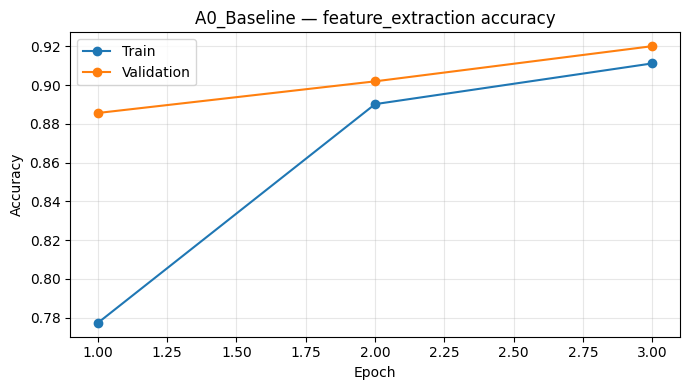

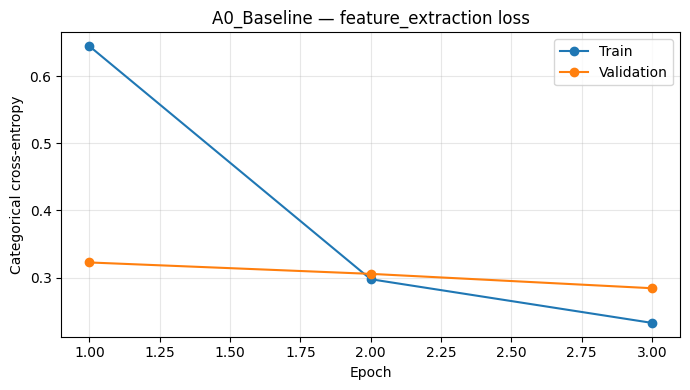

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 47s 91ms/step - accuracy: 0.8957 - loss: 0.2947 - val_accuracy: 0.9183 - val_loss: 0.2532
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 19s 56ms/step - accuracy: 0.9315 - loss: 0.1941 - val_accuracy: 0.9328 - val_loss: 0.2276


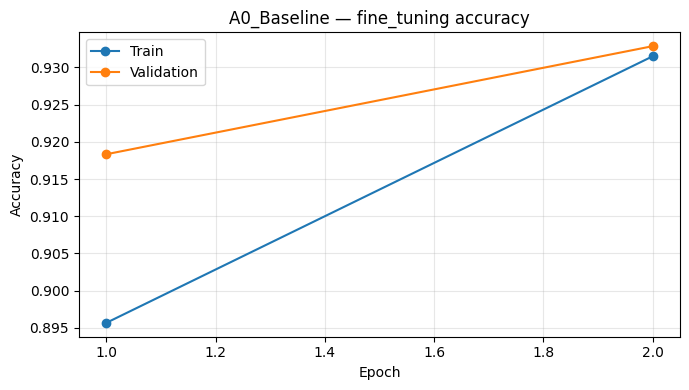

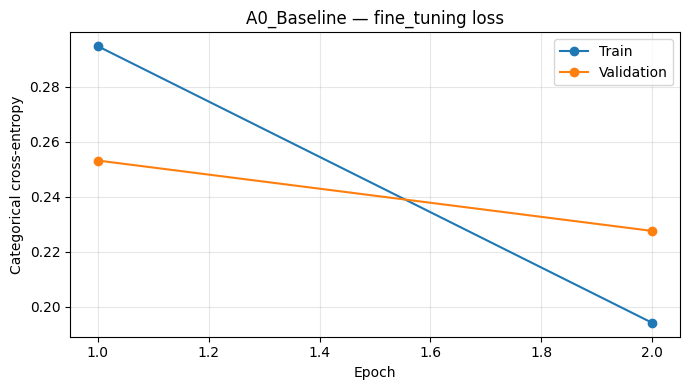

 Experiment Attention map  Kernel  Dropout  Feature extraction best val accuracy  Fine-tuning best val accuracy  Final validation accuracy  Final validation loss  Trainable parameters after fine-tuning  Total parameters  Feature extraction seconds  Fine-tuning seconds  Inference ms/image                                                       Weights
A0_Baseline            {}       7      0.3                              0.920145                       0.932849                   0.932849                0.22757                                14986245          23597957                   55.019885            66.232038           29.907274 /kaggle/working/lab8_attention_outputs/A0_Baseline.weights.h5


In [52]:
# A0 — Baseline ResNet50

record = train_one_experiment("A0_Baseline", attention_map={})


In [53]:
records.append(record)


In [54]:
pd.DataFrame(records).to_csv(results_path, index=False)


In [55]:
display(pd.DataFrame([record]))

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,A0_Baseline,{},7,0.3,0.920145,0.932849,0.932849,0.22757,14986245,23597957,55.019885,66.232038,29.907274,/kaggle/working/lab8_attention_outputs/A0_Base...



EXPERIMENT: A1_Channel_P3 
Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 34s 70ms/step - accuracy: 0.7929 - loss: 0.5764 - val_accuracy: 0.8784 - val_loss: 0.3253
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - accuracy: 0.9089 - loss: 0.2703 - val_accuracy: 0.9056 - val_loss: 0.2371
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - accuracy: 0.9303 - loss: 0.2005 - val_accuracy: 0.9201 - val_loss: 0.2325


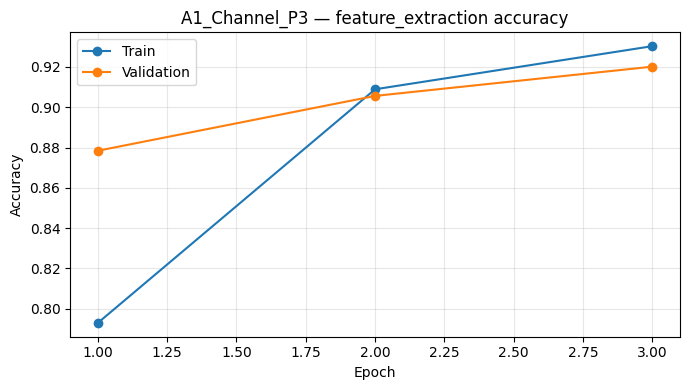

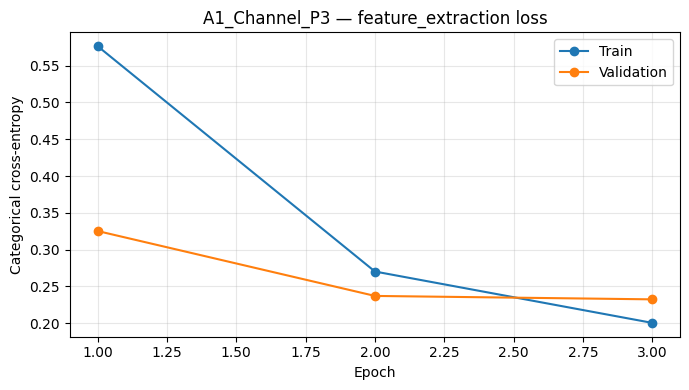

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 49s 96ms/step - accuracy: 0.8805 - loss: 0.3552 - val_accuracy: 0.9201 - val_loss: 0.2413
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 20s 60ms/step - accuracy: 0.9373 - loss: 0.1934 - val_accuracy: 0.9256 - val_loss: 0.2237


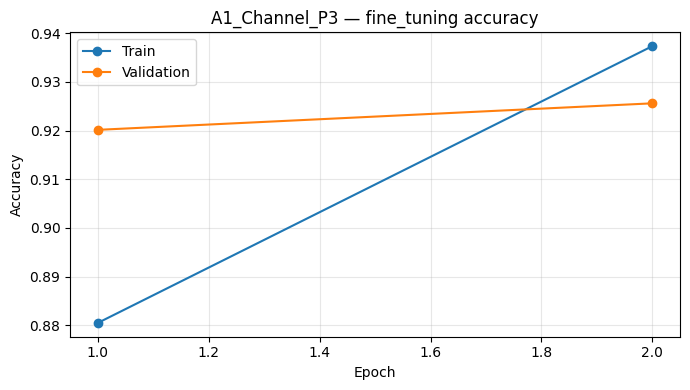

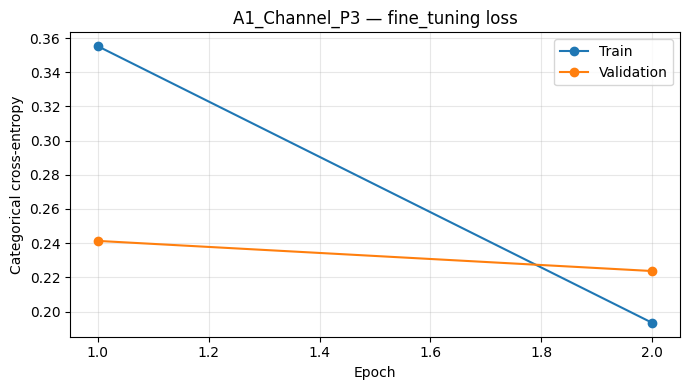

   Experiment     Attention map  Kernel  Dropout  Feature extraction best val accuracy  Fine-tuning best val accuracy  Final validation accuracy  Final validation loss  Trainable parameters after fine-tuning  Total parameters  Feature extraction seconds  Fine-tuning seconds  Inference ms/image                                                         Weights
A1_Channel_P3 {'P3': 'channel'}       7      0.3                              0.920145                        0.92559                    0.92559                0.22369                                15118405          23730117                     60.4489            69.294149           29.668882 /kaggle/working/lab8_attention_outputs/A1_Channel_P3.weights.h5


In [56]:
# A1 — Channel attention at P3

record = train_one_experiment("A1_Channel_P3", attention_map={'P3': 'channel'})


In [57]:
records.append(record)


In [58]:
pd.DataFrame(records).to_csv(results_path, index=False)


In [59]:
display(pd.DataFrame([record]))

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,A1_Channel_P3,{'P3': 'channel'},7,0.3,0.920145,0.92559,0.92559,0.22369,15118405,23730117,60.4489,69.294149,29.668882,/kaggle/working/lab8_attention_outputs/A1_Chan...



EXPERIMENT: A2_Spatial_P3 
Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 33s 69ms/step - accuracy: 0.7046 - loss: 0.7523 - val_accuracy: 0.8748 - val_loss: 0.4083
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.8957 - loss: 0.3013 - val_accuracy: 0.8947 - val_loss: 0.3270
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.9218 - loss: 0.2181 - val_accuracy: 0.9238 - val_loss: 0.2848


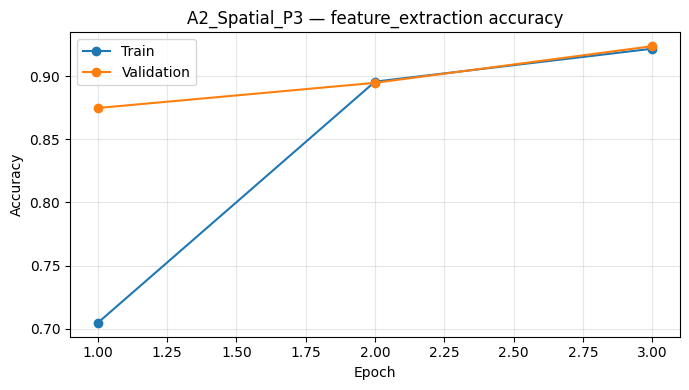

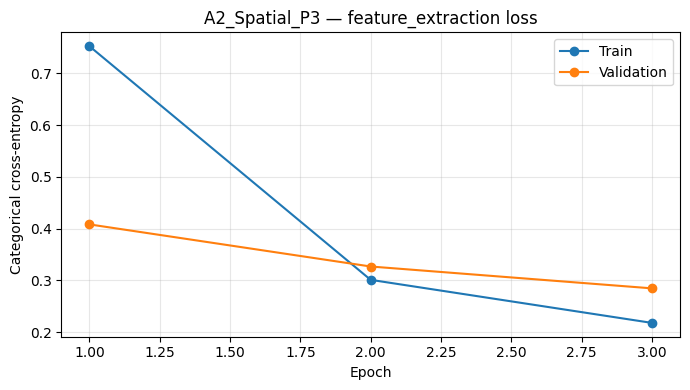

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 49s 97ms/step - accuracy: 0.8937 - loss: 0.2966 - val_accuracy: 0.9328 - val_loss: 0.2477
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 20s 60ms/step - accuracy: 0.9373 - loss: 0.1834 - val_accuracy: 0.9328 - val_loss: 0.2330


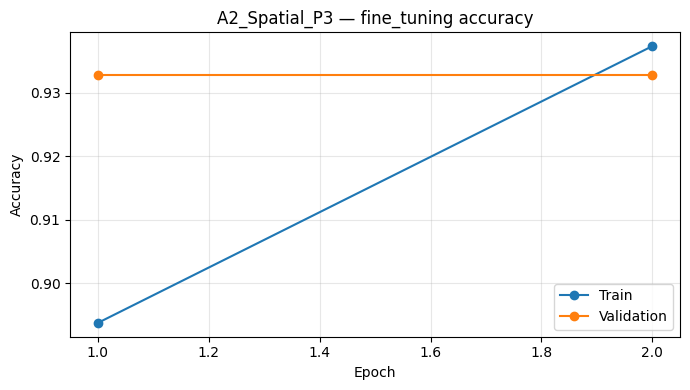

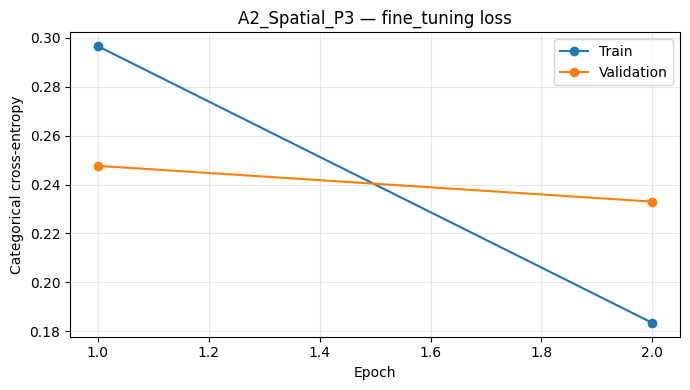

   Experiment     Attention map  Kernel  Dropout  Feature extraction best val accuracy  Fine-tuning best val accuracy  Final validation accuracy  Final validation loss  Trainable parameters after fine-tuning  Total parameters  Feature extraction seconds  Fine-tuning seconds  Inference ms/image                                                         Weights
A2_Spatial_P3 {'P3': 'spatial'}       7      0.3                              0.923775                       0.932849                   0.932849               0.233016                                14986343          23598055                   59.947142            68.980458           29.439627 /kaggle/working/lab8_attention_outputs/A2_Spatial_P3.weights.h5


In [60]:
# A2 — Spatial attention at P3

record = train_one_experiment("A2_Spatial_P3", attention_map={'P3': 'spatial'})


In [61]:
records.append(record)


In [62]:
pd.DataFrame(records).to_csv(results_path, index=False)


In [63]:
display(pd.DataFrame([record]))

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,A2_Spatial_P3,{'P3': 'spatial'},7,0.3,0.923775,0.932849,0.932849,0.233016,14986343,23598055,59.947142,68.980458,29.439627,/kaggle/working/lab8_attention_outputs/A2_Spat...



EXPERIMENT: A3_ChannelSpatial_P3 
Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 35s 72ms/step - accuracy: 0.7731 - loss: 0.5991 - val_accuracy: 0.8966 - val_loss: 0.3208
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.9050 - loss: 0.2635 - val_accuracy: 0.9183 - val_loss: 0.2661
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.9268 - loss: 0.1945 - val_accuracy: 0.9256 - val_loss: 0.2572


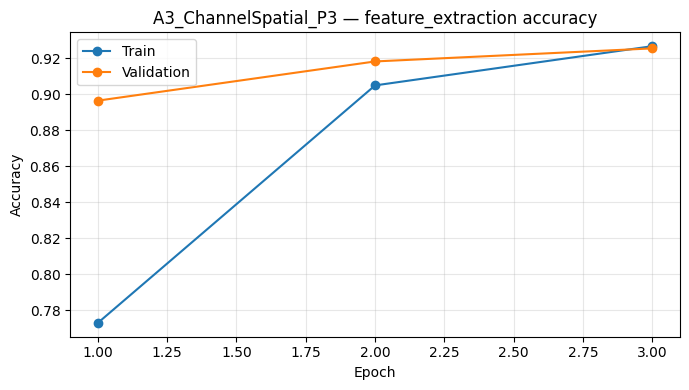

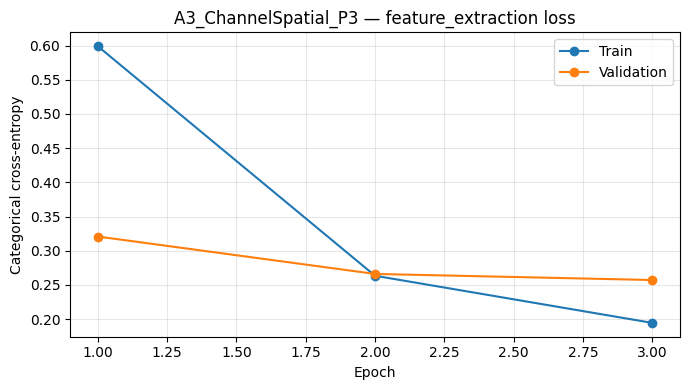

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 50s 98ms/step - accuracy: 0.8817 - loss: 0.3304 - val_accuracy: 0.9220 - val_loss: 0.2565
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 20s 60ms/step - accuracy: 0.9323 - loss: 0.1947 - val_accuracy: 0.9310 - val_loss: 0.2384


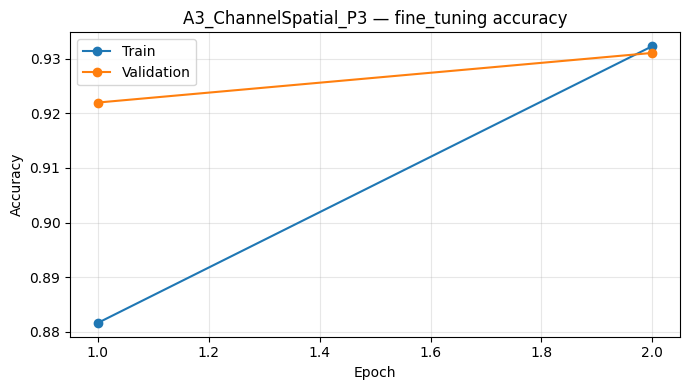

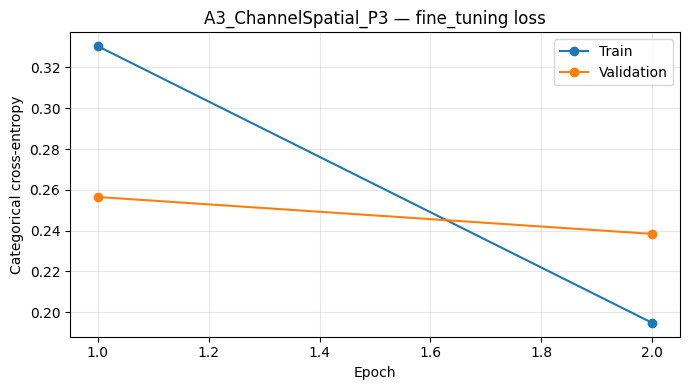

          Experiment             Attention map  Kernel  Dropout  Feature extraction best val accuracy  Fine-tuning best val accuracy  Final validation accuracy  Final validation loss  Trainable parameters after fine-tuning  Total parameters  Feature extraction seconds  Fine-tuning seconds  Inference ms/image                                                                Weights
A3_ChannelSpatial_P3 {'P3': 'channel_spatial'}       7      0.3                               0.92559                       0.931035                   0.931035               0.238371                                15118503          23730215                   62.023563            70.179173            30.20352 /kaggle/working/lab8_attention_outputs/A3_ChannelSpatial_P3.weights.h5


In [64]:
# A3 — Channel followed by spatial attention at P3

record = train_one_experiment("A3_ChannelSpatial_P3", attention_map={'P3': 'channel_spatial'})


In [65]:
records.append(record)


In [66]:
pd.DataFrame(records).to_csv(results_path, index=False)


In [67]:
display(pd.DataFrame([record]))

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,A3_ChannelSpatial_P3,{'P3': 'channel_spatial'},7,0.3,0.92559,0.931035,0.931035,0.238371,15118503,23730215,62.023563,70.179173,30.20352,/kaggle/working/lab8_attention_outputs/A3_Chan...



EXPERIMENT: A4_SelfAttention_P3 
Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 35s 73ms/step - accuracy: 0.7334 - loss: 0.7293 - val_accuracy: 0.8494 - val_loss: 0.3775
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - accuracy: 0.8334 - loss: 0.4627 - val_accuracy: 0.8639 - val_loss: 0.3644
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.8350 - loss: 0.5112 - val_accuracy: 0.8657 - val_loss: 0.4191


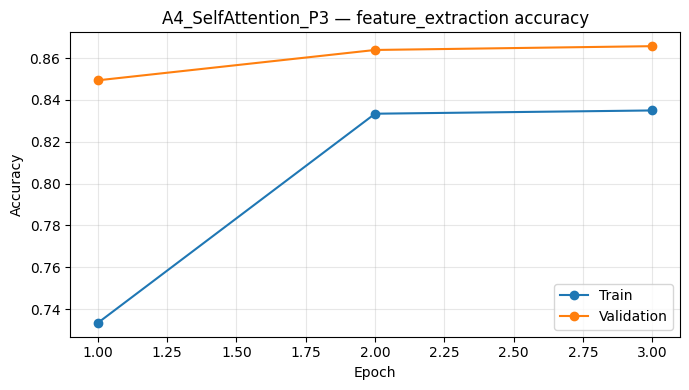

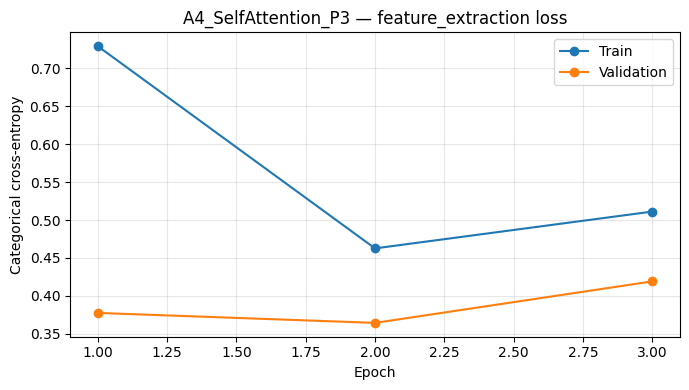

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 49s 98ms/step - accuracy: 0.8599 - loss: 0.4110 - val_accuracy: 0.9038 - val_loss: 0.2833
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 21s 62ms/step - accuracy: 0.9035 - loss: 0.2870 - val_accuracy: 0.9038 - val_loss: 0.2662


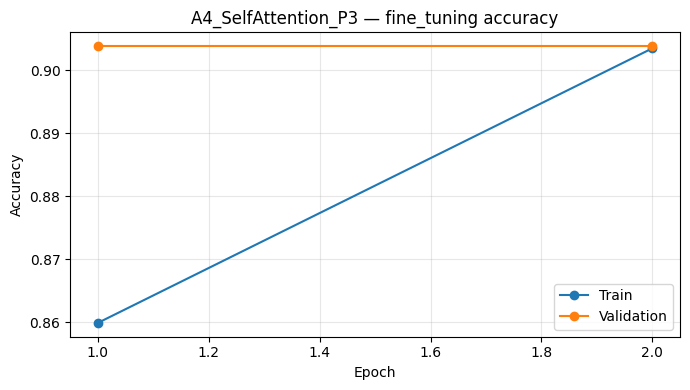

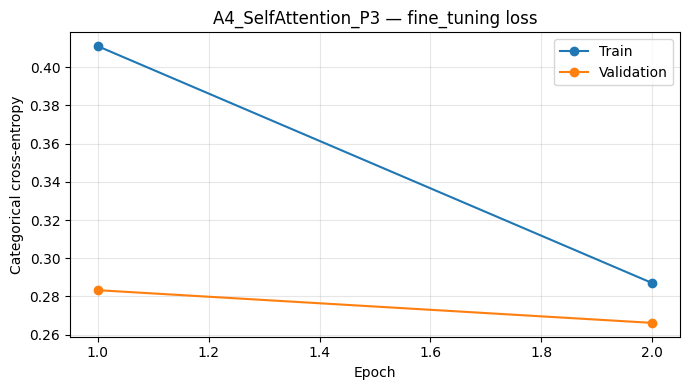

         Experiment  Attention map  Kernel  Dropout  Feature extraction best val accuracy  Fine-tuning best val accuracy  Final validation accuracy  Final validation loss  Trainable parameters after fine-tuning  Total parameters  Feature extraction seconds  Fine-tuning seconds  Inference ms/image                                                               Weights
A4_SelfAttention_P3 {'P3': 'self'}       7      0.3                              0.865699                       0.903811                   0.903811                0.26616                                15510533          24122245                   63.128737            70.117223           29.736444 /kaggle/working/lab8_attention_outputs/A4_SelfAttention_P3.weights.h5


In [68]:
# A4 — Self-attention at P3

record = train_one_experiment("A4_SelfAttention_P3", attention_map={'P3': 'self'})


In [69]:
records.append(record)


In [70]:
pd.DataFrame(records).to_csv(results_path, index=False)


In [71]:
display(pd.DataFrame([record]))

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,A4_SelfAttention_P3,{'P3': 'self'},7,0.3,0.865699,0.903811,0.903811,0.26616,15510533,24122245,63.128737,70.117223,29.736444,/kaggle/working/lab8_attention_outputs/A4_Self...



EXPERIMENT: A5_Combined_P3 
Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 37s 76ms/step - accuracy: 0.7256 - loss: 0.7148 - val_accuracy: 0.8603 - val_loss: 0.3992
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step - accuracy: 0.8723 - loss: 0.3594 - val_accuracy: 0.8820 - val_loss: 0.3465
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - accuracy: 0.8968 - loss: 0.2997 - val_accuracy: 0.8675 - val_loss: 0.3479


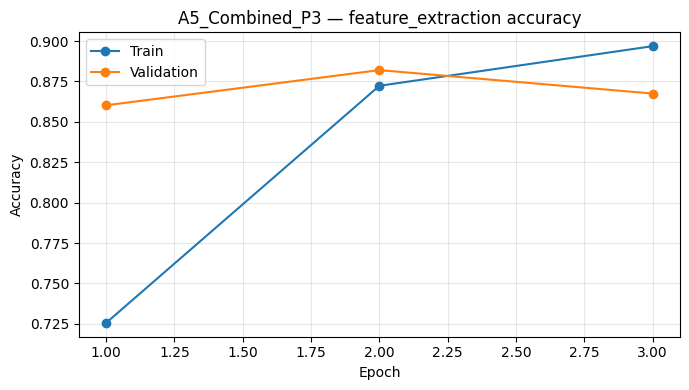

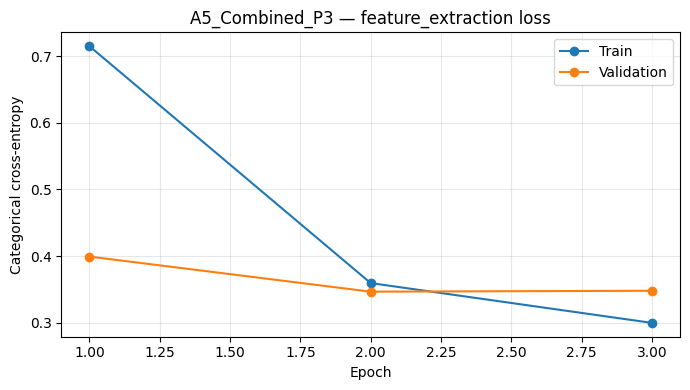

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 52s 103ms/step - accuracy: 0.8571 - loss: 0.4220 - val_accuracy: 0.9111 - val_loss: 0.2451
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 21s 63ms/step - accuracy: 0.9077 - loss: 0.2582 - val_accuracy: 0.9292 - val_loss: 0.2155


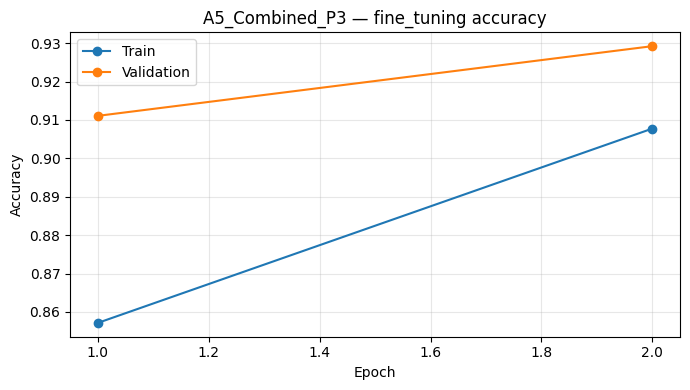

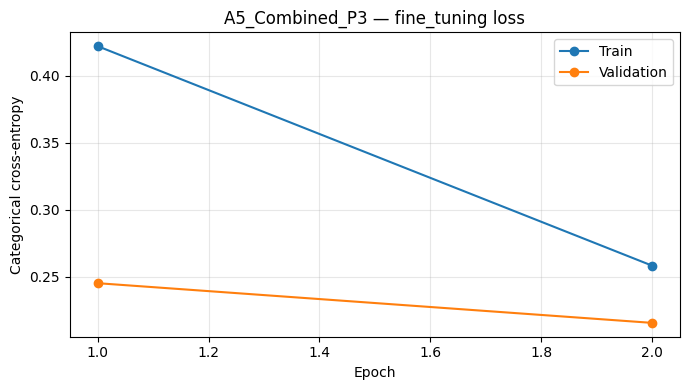

    Experiment      Attention map  Kernel  Dropout  Feature extraction best val accuracy  Fine-tuning best val accuracy  Final validation accuracy  Final validation loss  Trainable parameters after fine-tuning  Total parameters  Feature extraction seconds  Fine-tuning seconds  Inference ms/image                                                          Weights
A5_Combined_P3 {'P3': 'combined'}       7      0.3                              0.882033                        0.92922                    0.92922               0.215501                                15642791          24254503                   66.537703            73.520301           30.374126 /kaggle/working/lab8_attention_outputs/A5_Combined_P3.weights.h5


In [72]:
# A5 — Combined channel, spatial and self-attention at P3

record = train_one_experiment("A5_Combined_P3", attention_map={'P3': 'combined'})


In [73]:
records.append(record)


In [74]:
pd.DataFrame(records).to_csv(results_path, index=False)


In [75]:
display(pd.DataFrame([record]))

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,A5_Combined_P3,{'P3': 'combined'},7,0.3,0.882033,0.92922,0.92922,0.215501,15642791,24254503,66.537703,73.520301,30.374126,/kaggle/working/lab8_attention_outputs/A5_Comb...



EXPERIMENT: A6_SE_P3 
Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 33s 68ms/step - accuracy: 0.7836 - loss: 0.5629 - val_accuracy: 0.9056 - val_loss: 0.2830
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.9019 - loss: 0.2748 - val_accuracy: 0.9129 - val_loss: 0.2509
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 13s 40ms/step - accuracy: 0.9249 - loss: 0.1990 - val_accuracy: 0.9020 - val_loss: 0.2564


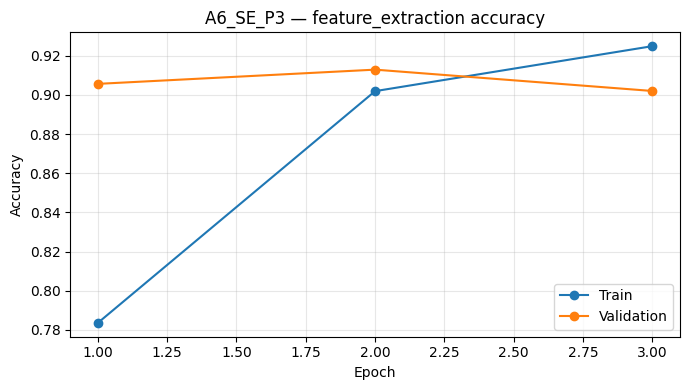

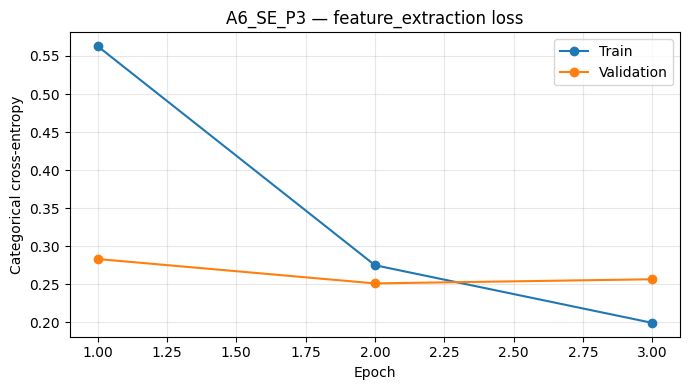

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 49s 96ms/step - accuracy: 0.8591 - loss: 0.4066 - val_accuracy: 0.9238 - val_loss: 0.2459
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 20s 60ms/step - accuracy: 0.9257 - loss: 0.2136 - val_accuracy: 0.9256 - val_loss: 0.2308


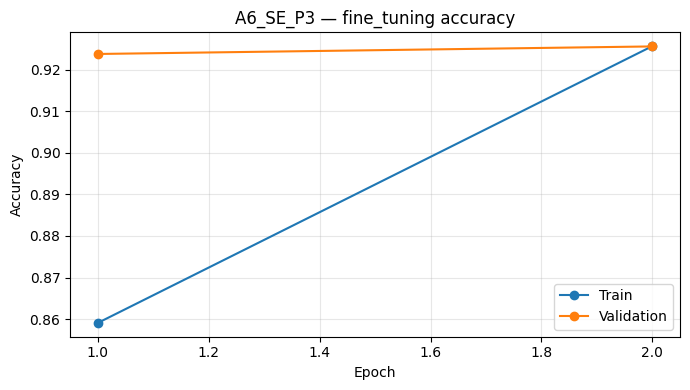

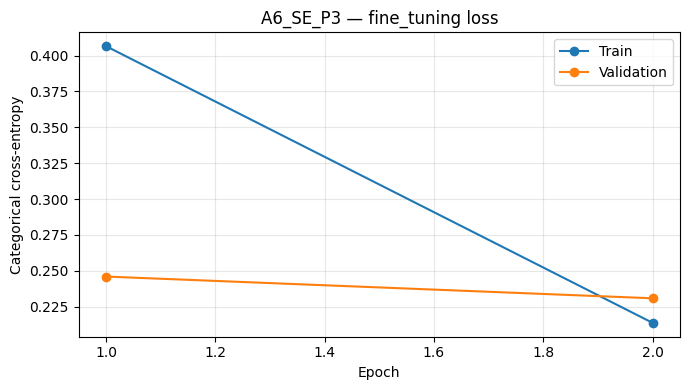

Experiment Attention map  Kernel  Dropout  Feature extraction best val accuracy  Fine-tuning best val accuracy  Final validation accuracy  Final validation loss  Trainable parameters after fine-tuning  Total parameters  Feature extraction seconds  Fine-tuning seconds  Inference ms/image                                                    Weights
  A6_SE_P3  {'P3': 'se'}       7      0.3                              0.912886                        0.92559                    0.92559               0.230752                                15118405          23730117                   59.800971            69.041819           29.770733 /kaggle/working/lab8_attention_outputs/A6_SE_P3.weights.h5


In [76]:
# A6 — Squeeze-and-Excitation (SE) at P3

record = train_one_experiment("A6_SE_P3", attention_map={'P3': 'se'})


In [77]:
records.append(record)


In [78]:
pd.DataFrame(records).to_csv(results_path, index=False)


In [79]:
display(pd.DataFrame([record]))

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,A6_SE_P3,{'P3': 'se'},7,0.3,0.912886,0.92559,0.92559,0.230752,15118405,23730117,59.800971,69.041819,29.770733,/kaggle/working/lab8_attention_outputs/A6_SE_P...



EXPERIMENT: A7_ECA_P3 
Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 34s 73ms/step - accuracy: 0.6968 - loss: 0.8871 - val_accuracy: 0.8348 - val_loss: 0.4933
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.8638 - loss: 0.3978 - val_accuracy: 0.8639 - val_loss: 0.3676
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.8941 - loss: 0.2906 - val_accuracy: 0.8820 - val_loss: 0.3321


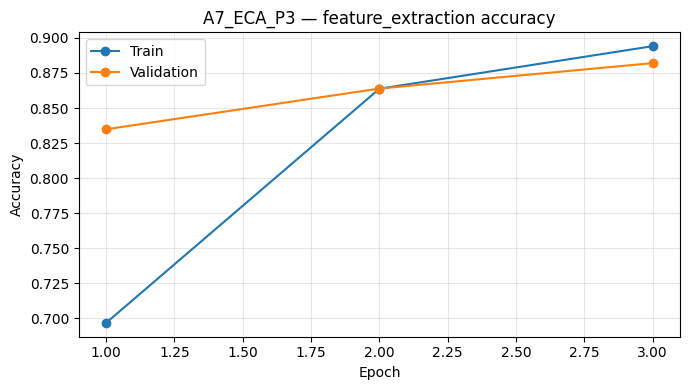

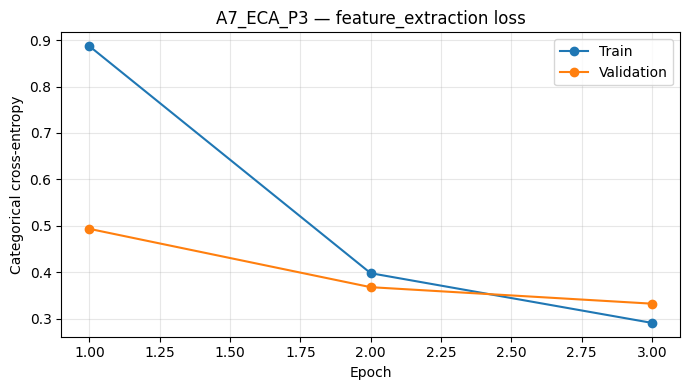

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 48s 96ms/step - accuracy: 0.8357 - loss: 0.6370 - val_accuracy: 0.9147 - val_loss: 0.3391
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 20s 60ms/step - accuracy: 0.9046 - loss: 0.2828 - val_accuracy: 0.9201 - val_loss: 0.3218


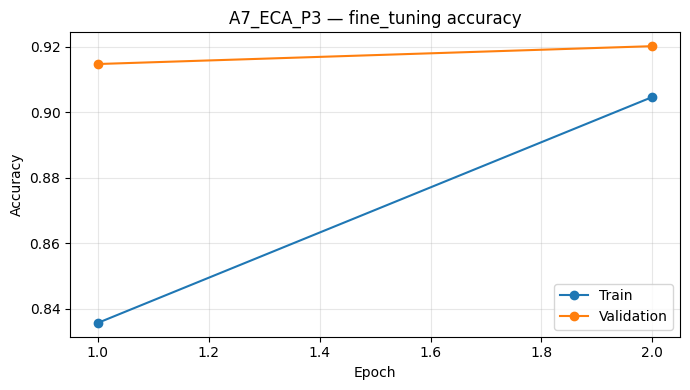

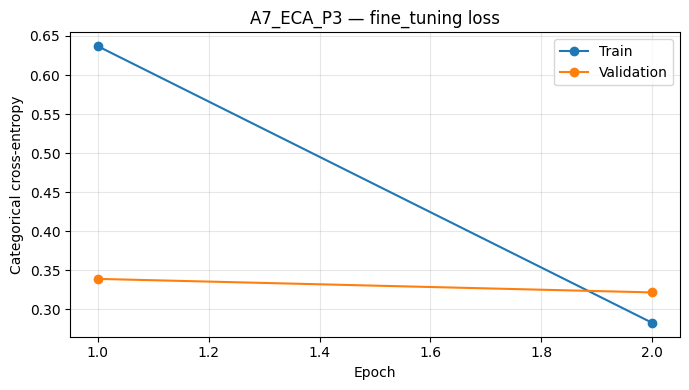

Experiment Attention map  Kernel  Dropout  Feature extraction best val accuracy  Fine-tuning best val accuracy  Final validation accuracy  Final validation loss  Trainable parameters after fine-tuning  Total parameters  Feature extraction seconds  Fine-tuning seconds  Inference ms/image                                                     Weights
 A7_ECA_P3 {'P3': 'eca'}       7      0.3                              0.882033                       0.920145                   0.920145               0.321802                                14986248          23597960                   61.367683            68.550888           29.915084 /kaggle/working/lab8_attention_outputs/A7_ECA_P3.weights.h5


In [80]:
# A7 — Efficient Channel Attention (ECA) at P3

record = train_one_experiment("A7_ECA_P3", attention_map={'P3': 'eca'})


In [81]:
records.append(record)


In [82]:
pd.DataFrame(records).to_csv(results_path, index=False)


In [83]:
display(pd.DataFrame([record]))

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,A7_ECA_P3,{'P3': 'eca'},7,0.3,0.882033,0.920145,0.920145,0.321802,14986248,23597960,61.367683,68.550888,29.915084,/kaggle/working/lab8_attention_outputs/A7_ECA_...



EXPERIMENT: A8_CBAM_P3 
Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 34s 71ms/step - accuracy: 0.7956 - loss: 0.5655 - val_accuracy: 0.8802 - val_loss: 0.3156
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.9019 - loss: 0.2711 - val_accuracy: 0.8838 - val_loss: 0.3275
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.9350 - loss: 0.1831 - val_accuracy: 0.9020 - val_loss: 0.3008


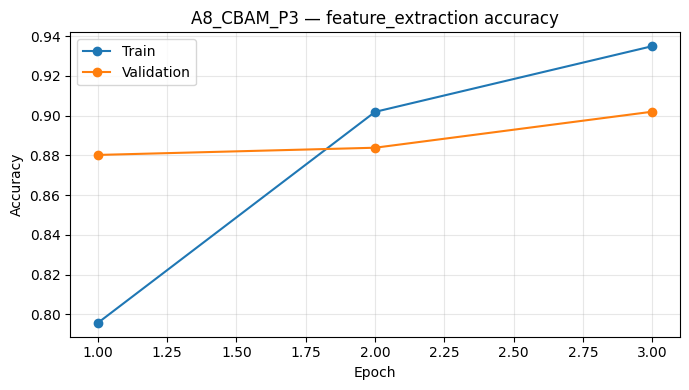

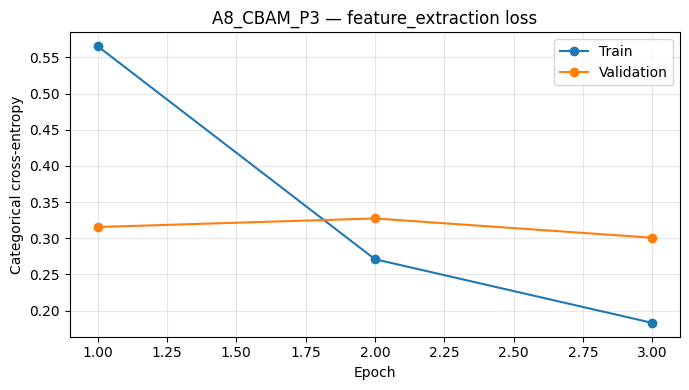

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 50s 98ms/step - accuracy: 0.8747 - loss: 0.3431 - val_accuracy: 0.9093 - val_loss: 0.2535
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 20s 61ms/step - accuracy: 0.9311 - loss: 0.1925 - val_accuracy: 0.9020 - val_loss: 0.2462


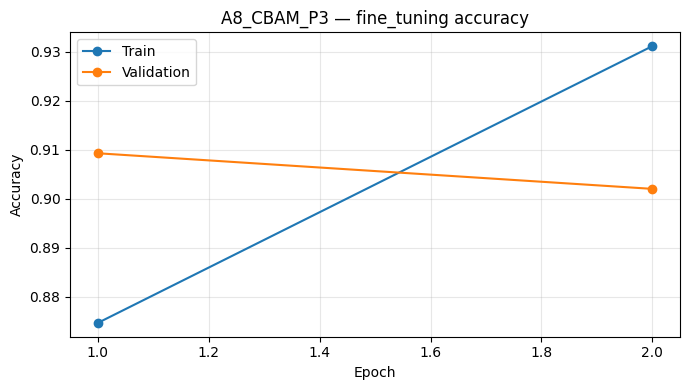

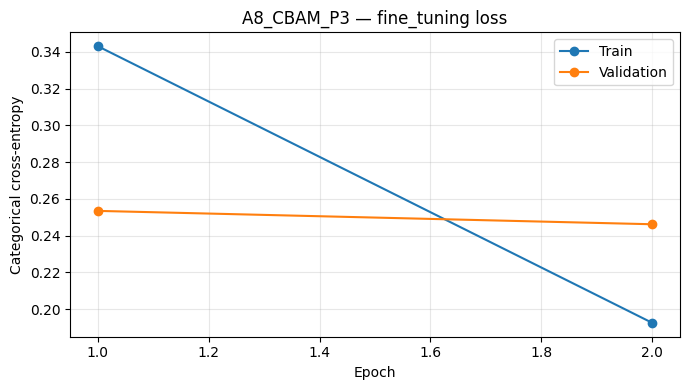

Experiment  Attention map  Kernel  Dropout  Feature extraction best val accuracy  Fine-tuning best val accuracy  Final validation accuracy  Final validation loss  Trainable parameters after fine-tuning  Total parameters  Feature extraction seconds  Fine-tuning seconds  Inference ms/image                                                      Weights
A8_CBAM_P3 {'P3': 'cbam'}       7      0.3                              0.901996                       0.909256                   0.901996               0.246192                                15118503          23730215                    61.61527            70.297892           29.864635 /kaggle/working/lab8_attention_outputs/A8_CBAM_P3.weights.h5


In [84]:
# A8 — CBAM at P3

record = train_one_experiment("A8_CBAM_P3", attention_map={'P3': 'cbam'})


In [85]:
records.append(record)


In [86]:
pd.DataFrame(records).to_csv(results_path, index=False)


In [87]:
display(pd.DataFrame([record]))

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,A8_CBAM_P3,{'P3': 'cbam'},7,0.3,0.901996,0.909256,0.901996,0.246192,15118503,23730215,61.61527,70.297892,29.864635,/kaggle/working/lab8_attention_outputs/A8_CBAM...



EXPERIMENT: B1_ChannelSpatial_P2 
Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 39s 82ms/step - accuracy: 0.6458 - loss: 0.8972 - val_accuracy: 0.8603 - val_loss: 0.3750
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 17s 49ms/step - accuracy: 0.8723 - loss: 0.3671 - val_accuracy: 0.9038 - val_loss: 0.2711
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 16s 48ms/step - accuracy: 0.9120 - loss: 0.2554 - val_accuracy: 0.9147 - val_loss: 0.2677


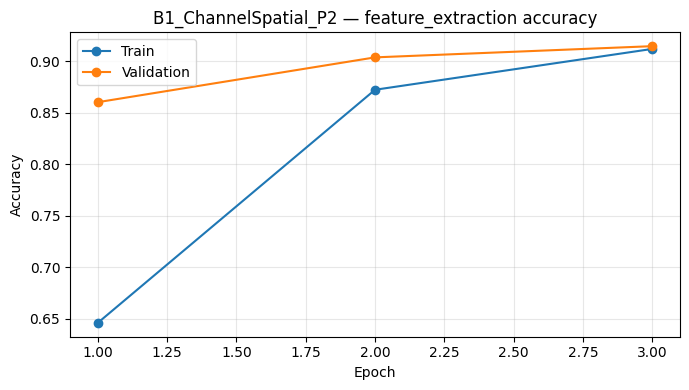

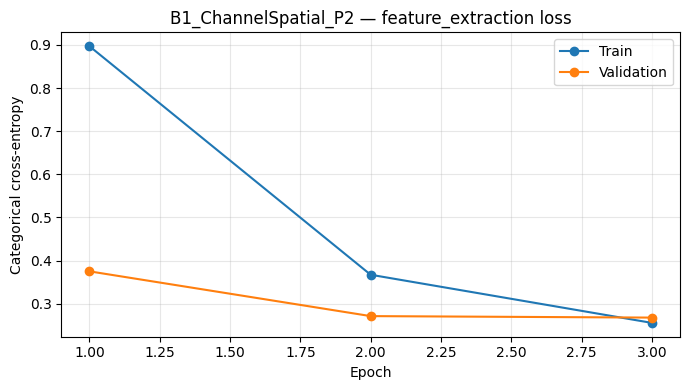

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - accuracy: 0.8747 - loss: 0.3510 - val_accuracy: 0.9111 - val_loss: 0.2251
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 23s 69ms/step - accuracy: 0.9292 - loss: 0.2037 - val_accuracy: 0.9220 - val_loss: 0.2094


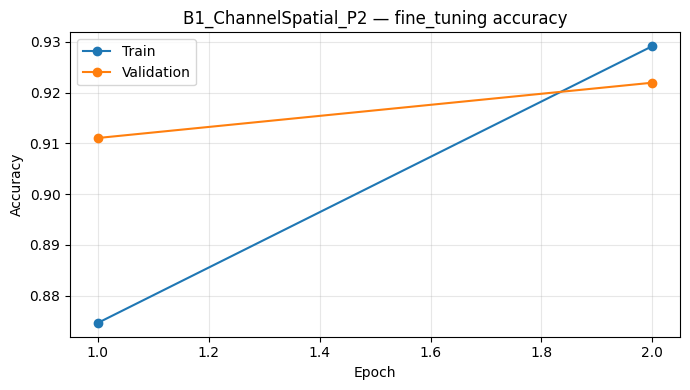

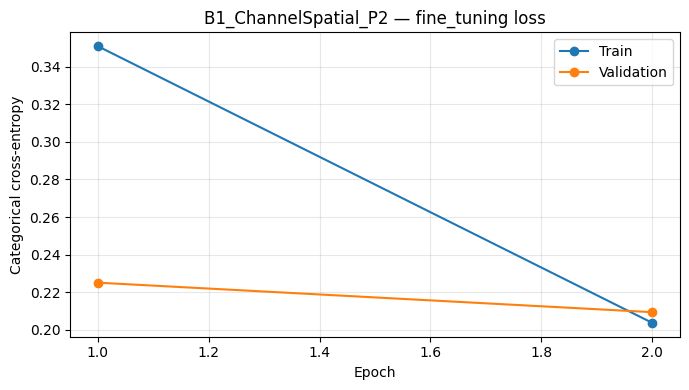

          Experiment             Attention map  Kernel  Dropout  Feature extraction best val accuracy  Fine-tuning best val accuracy  Final validation accuracy  Final validation loss  Trainable parameters after fine-tuning  Total parameters  Feature extraction seconds  Fine-tuning seconds  Inference ms/image                                                                Weights
B1_ChannelSpatial_P2 {'P2': 'channel_spatial'}       7      0.3                              0.914701                        0.92196                    0.92196               0.209355                                15019655          23631367                    72.13688            76.394503            29.76652 /kaggle/working/lab8_attention_outputs/B1_ChannelSpatial_P2.weights.h5


In [88]:
# B1 — Channel-spatial attention at P2

record = train_one_experiment("B1_ChannelSpatial_P2", attention_map={'P2': 'channel_spatial'})


In [89]:
records.append(record)


In [90]:
pd.DataFrame(records).to_csv(results_path, index=False)


In [91]:
display(pd.DataFrame([record]))

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,B1_ChannelSpatial_P2,{'P2': 'channel_spatial'},7,0.3,0.914701,0.92196,0.92196,0.209355,15019655,23631367,72.13688,76.394503,29.76652,/kaggle/working/lab8_attention_outputs/B1_Chan...



EXPERIMENT: B2_ChannelSpatial_P3 
Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 34s 71ms/step - accuracy: 0.7524 - loss: 0.6715 - val_accuracy: 0.8820 - val_loss: 0.3143
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.9035 - loss: 0.2710 - val_accuracy: 0.9020 - val_loss: 0.2825
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.9338 - loss: 0.1868 - val_accuracy: 0.9020 - val_loss: 0.2531


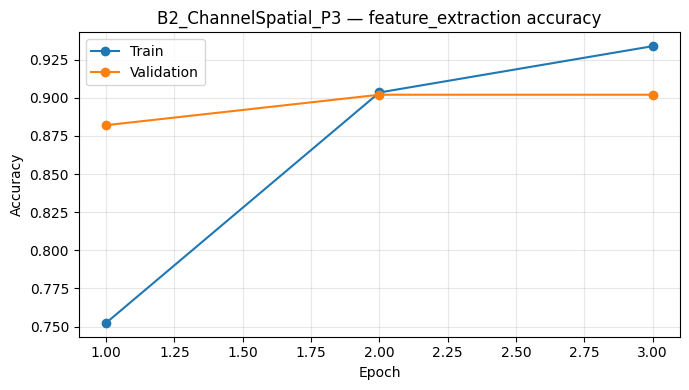

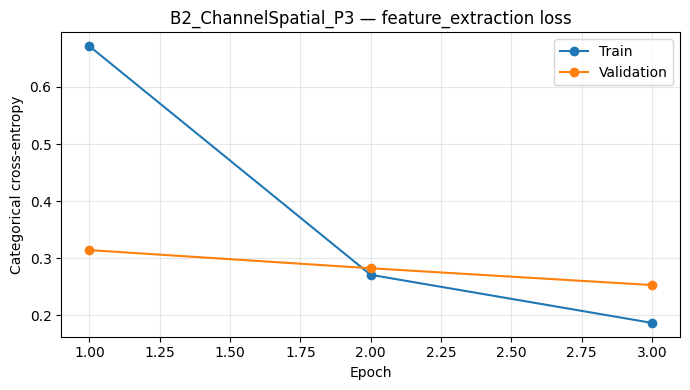

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 50s 99ms/step - accuracy: 0.8859 - loss: 0.3352 - val_accuracy: 0.9129 - val_loss: 0.2559
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 20s 60ms/step - accuracy: 0.9315 - loss: 0.1901 - val_accuracy: 0.9165 - val_loss: 0.2435


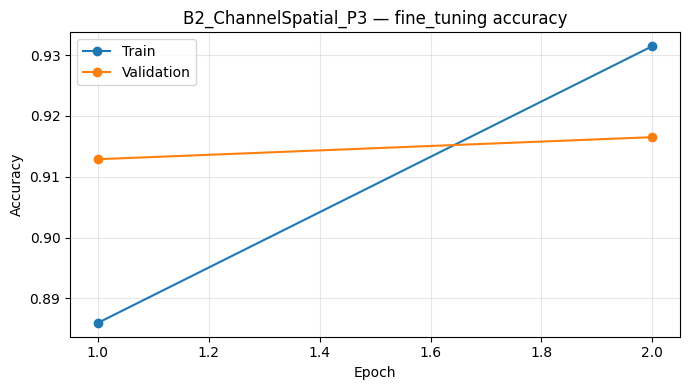

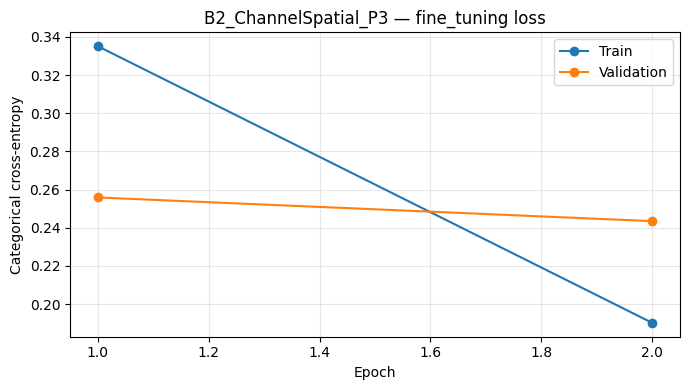

          Experiment             Attention map  Kernel  Dropout  Feature extraction best val accuracy  Fine-tuning best val accuracy  Final validation accuracy  Final validation loss  Trainable parameters after fine-tuning  Total parameters  Feature extraction seconds  Fine-tuning seconds  Inference ms/image                                                                Weights
B2_ChannelSpatial_P3 {'P3': 'channel_spatial'}       7      0.3                              0.901996                       0.916515                   0.916515               0.243467                                15118503          23730215                   61.457769            70.336435           30.042693 /kaggle/working/lab8_attention_outputs/B2_ChannelSpatial_P3.weights.h5


In [92]:
# B2 — Channel-spatial attention at P3

record = train_one_experiment("B2_ChannelSpatial_P3", attention_map={'P3': 'channel_spatial'})


In [93]:
records.append(record)


In [94]:
pd.DataFrame(records).to_csv(results_path, index=False)


In [95]:
display(pd.DataFrame([record]))

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,B2_ChannelSpatial_P3,{'P3': 'channel_spatial'},7,0.3,0.901996,0.916515,0.916515,0.243467,15118503,23730215,61.457769,70.336435,30.042693,/kaggle/working/lab8_attention_outputs/B2_Chan...



EXPERIMENT: B3_ChannelSpatial_P4 
Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 33s 66ms/step - accuracy: 0.8276 - loss: 0.4939 - val_accuracy: 0.8929 - val_loss: 0.2978
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.9233 - loss: 0.2146 - val_accuracy: 0.9020 - val_loss: 0.2695
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.9545 - loss: 0.1342 - val_accuracy: 0.9056 - val_loss: 0.2883


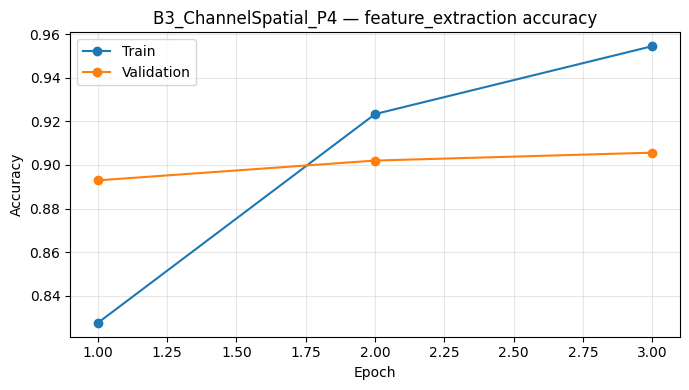

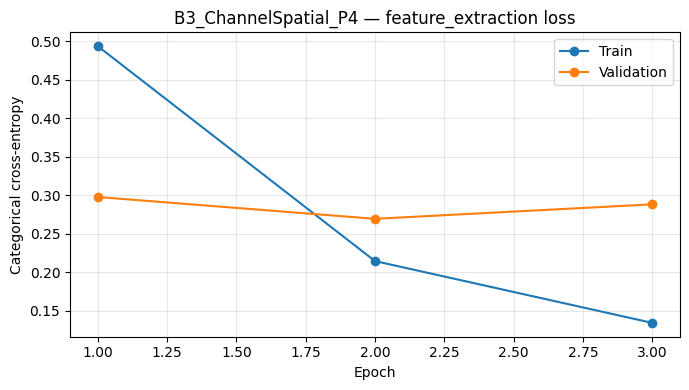

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 49s 97ms/step - accuracy: 0.9105 - loss: 0.2615 - val_accuracy: 0.9201 - val_loss: 0.2338
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 20s 59ms/step - accuracy: 0.9502 - loss: 0.1464 - val_accuracy: 0.9274 - val_loss: 0.2166


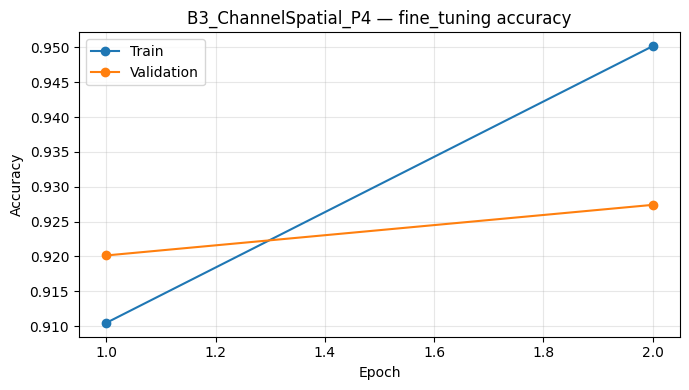

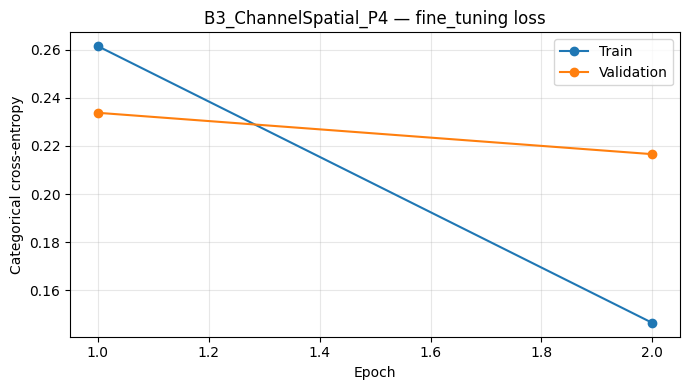

          Experiment             Attention map  Kernel  Dropout  Feature extraction best val accuracy  Fine-tuning best val accuracy  Final validation accuracy  Final validation loss  Trainable parameters after fine-tuning  Total parameters  Feature extraction seconds  Fine-tuning seconds  Inference ms/image                                                                Weights
B3_ChannelSpatial_P4 {'P4': 'channel_spatial'}       7      0.3                              0.905626                       0.927405                   0.927405               0.216585                                15512807          24124519                   56.848732            69.259554            29.84402 /kaggle/working/lab8_attention_outputs/B3_ChannelSpatial_P4.weights.h5


In [96]:
# B3 — Channel-spatial attention at P4

record = train_one_experiment("B3_ChannelSpatial_P4", attention_map={'P4': 'channel_spatial'})


## 15. Main Experiment 2 — Attention-Position Ablation (manual-aligned)
This block follows the manual's four positions: B1 after `conv2_x`, B2 after `conv3_x`, B3 after `conv4_x`, and B4 after `conv5_x`. The notebook's earlier P2/P3/P4 experiments use a separate naming convention and are retained unchanged. These manual-aligned runs are additional experiments; run them only when their corresponding saved weights/results are not already available.


In [97]:
# 15. MAIN EXPERIMENT 2 — ATTENTION-POSITION ABLATION (manual-aligned)
# Compare channel→spatial attention after conv2_x, conv3_x, conv4_x, and conv5_x.
# The manual-aligned stages are distinct from the notebook’s P2/P3/P4 labels used elsewhere.

def build_resnet50_attention_by_manual_stage(attention_stage, kernel_size=7, dropout_rate=0.3,
                                             learning_rate=1e-3):
    """ResNet50 with channel->spatial attention after the specified residual stage.
    attention_stage: 2, 3, 4, or 5, corresponding to conv2_x ... conv5_x.
    """
    base = keras.applications.ResNet50(
        include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = False
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="manual_position_image")
    x = inputs
    for layer_name in ["conv1_pad", "conv1_conv", "conv1_bn", "conv1_relu", "pool1_pad", "pool1_pool"]:
        x = base.get_layer(layer_name)(x)

    stage_blocks = {2: 3, 3: 4, 4: 6, 5: 3}
    attention_features = None
    for stage, n_blocks in stage_blocks.items():
        for block in range(1, n_blocks + 1):
            prefix = f"conv{stage}_block{block}"
            shortcut = x
            x = base.get_layer(f"{prefix}_1_conv")(x)
            x = base.get_layer(f"{prefix}_1_bn")(x)
            x = base.get_layer(f"{prefix}_1_relu")(x)
            x = base.get_layer(f"{prefix}_2_conv")(x)
            x = base.get_layer(f"{prefix}_2_bn")(x)
            x = base.get_layer(f"{prefix}_2_relu")(x)
            x = base.get_layer(f"{prefix}_3_conv")(x)
            x = base.get_layer(f"{prefix}_3_bn")(x)
            if block == 1:
                shortcut = base.get_layer(f"{prefix}_0_conv")(shortcut)
                shortcut = base.get_layer(f"{prefix}_0_bn")(shortcut)
            x = base.get_layer(f"{prefix}_add")([x, shortcut])
            x = base.get_layer(f"{prefix}_out")(x)
        if stage == attention_stage:
            attention_features = x
            x = apply_attention(x, "channel_spatial", kernel_size=kernel_size,
                                name=f"manual_b{attention_stage}_channel_spatial")

    pooled = layers.GlobalAveragePooling2D(name="manual_global_average_pooling")(x)
    dropped = layers.Dropout(dropout_rate, name="manual_classifier_dropout")(pooled)
    outputs = layers.Dense(5, activation="softmax", name="manual_predictions")(dropped)
    model = keras.Model(inputs, outputs, name=f"ResNet50_attention_after_conv{attention_stage}_x")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    return model


def train_manual_position_experiment(name, attention_stage, kernel_size=7, dropout_rate=0.3):
    """Same dataset, epochs, optimizer schedule and result schema as the existing experiments."""
    tf.keras.backend.clear_session()
    gc.collect()
    model = build_resnet50_attention_by_manual_stage(
        attention_stage, kernel_size=kernel_size, dropout_rate=dropout_rate, learning_rate=1e-3
    )
    t0 = time.time()
    hist_feature = model.fit(train_ds, validation_data=val_ds, epochs=FEATURE_EPOCHS, verbose=1)
    feature_time = time.time() - t0
    save_history_plots(hist_feature, name, "feature_extraction")

    # Fine-tune the final ResNet stage, matching the existing training protocol.
    for layer in model.layers:
        if layer.name.startswith("conv5_block"):
            layer.trainable = True
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    t1 = time.time()
    hist_finetune = model.fit(train_ds, validation_data=val_ds, epochs=FINETUNE_EPOCHS, verbose=1)
    finetune_time = time.time() - t1
    save_history_plots(hist_finetune, name, "fine_tuning")

    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    safe = name.replace("/", "_").replace(" ", "_").replace("+", "plus")
    weight_path = os.path.join(OUTPUT_DIR, f"{safe}.weights.h5")
    model.save_weights(weight_path)
    sample_batch, _ = next(iter(test_ds))
    _ = model(sample_batch[:1], training=False)
    t2 = time.time()
    n_images = 0
    for batch_x, _ in test_ds:
        _ = model(batch_x, training=False)
        n_images += int(batch_x.shape[0])
    inference_ms = (time.time() - t2) * 1000 / max(n_images, 1)
    record = {
        "Experiment": name,
        "Attention map": str({f"after_conv{attention_stage}_x": "channel_spatial"}),
        "Kernel": kernel_size,
        "Dropout": dropout_rate,
        "Feature extraction best val accuracy": float(max(hist_feature.history["val_accuracy"])),
        "Fine-tuning best val accuracy": float(max(hist_finetune.history["val_accuracy"])),
        "Final validation accuracy": float(val_acc),
        "Final validation loss": float(val_loss),
        "Trainable parameters after fine-tuning": int(np.sum([np.prod(v.shape) for v in model.trainable_weights])),
        "Total parameters": int(model.count_params()),
        "Feature extraction seconds": float(feature_time),
        "Fine-tuning seconds": float(finetune_time),
        "Inference ms/image": float(inference_ms),
        "Weights": weight_path,
    }
    records.append(record)
    pd.DataFrame(records).to_csv(os.path.join(OUTPUT_DIR, "all_experiment_results.csv"), index=False)
    display(pd.DataFrame([record]))
    return record


Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 42s 91ms/step - accuracy: 0.5928 - loss: 1.0688 - val_accuracy: 0.8058 - val_loss: 0.5292
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 19s 57ms/step - accuracy: 0.8050 - loss: 0.5547 - val_accuracy: 0.8457 - val_loss: 0.4086
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 19s 56ms/step - accuracy: 0.8466 - loss: 0.4249 - val_accuracy: 0.8475 - val_loss: 0.4382


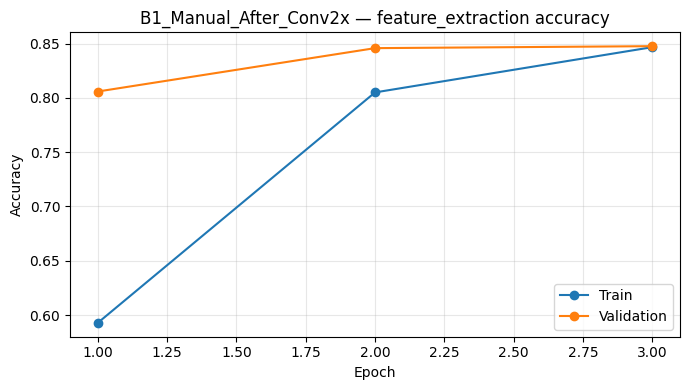

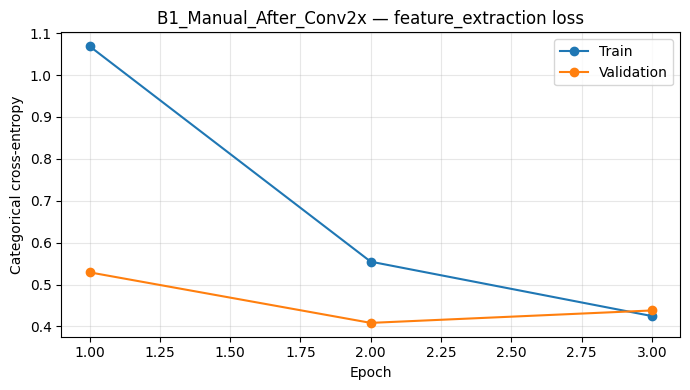

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 56s 117ms/step - accuracy: 0.7980 - loss: 0.6122 - val_accuracy: 0.8766 - val_loss: 0.3891
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 26s 77ms/step - accuracy: 0.8750 - loss: 0.3385 - val_accuracy: 0.8929 - val_loss: 0.3490


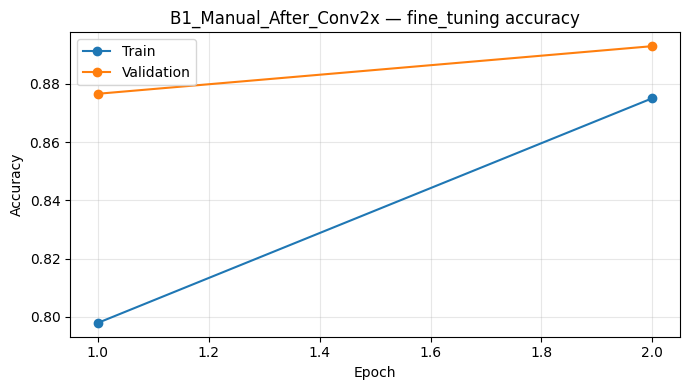

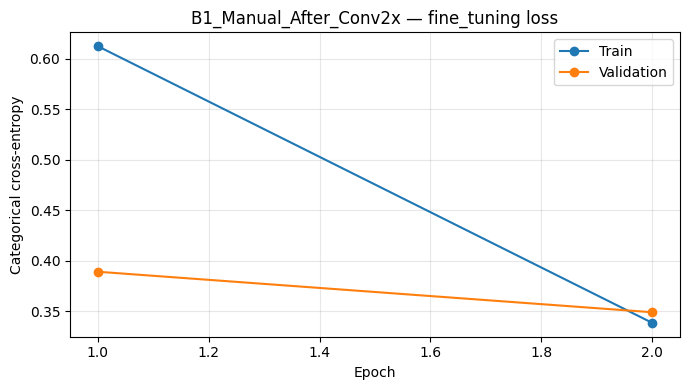

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,B1_Manual_After_Conv2x,{'after_conv2_x': 'channel_spatial'},7,0.3,0.84755,0.892922,0.892922,0.349025,14994807,23606519,79.737723,81.700562,29.816722,/kaggle/working/lab8_attention_outputs/B1_Manu...


In [98]:
# 15. Experiment 2 — B1: Channel→Spatial after conv2_x (56×56, 256 channels)
record_B1_manual = train_manual_position_experiment("B1_Manual_After_Conv2x", attention_stage=2)


Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 37s 81ms/step - accuracy: 0.7162 - loss: 0.7468 - val_accuracy: 0.8693 - val_loss: 0.3581
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 17s 50ms/step - accuracy: 0.8875 - loss: 0.3284 - val_accuracy: 0.9002 - val_loss: 0.2915
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 17s 49ms/step - accuracy: 0.9105 - loss: 0.2512 - val_accuracy: 0.9038 - val_loss: 0.2883


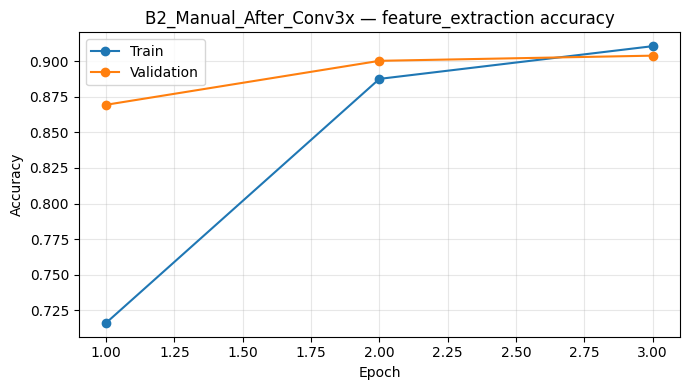

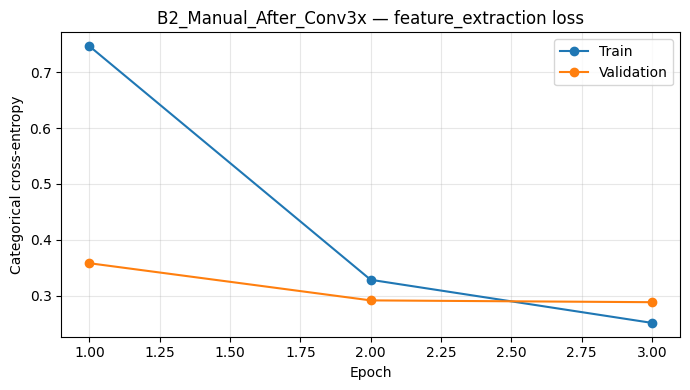

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - accuracy: 0.8750 - loss: 0.3478 - val_accuracy: 0.9038 - val_loss: 0.2673
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 23s 69ms/step - accuracy: 0.9214 - loss: 0.2177 - val_accuracy: 0.9093 - val_loss: 0.2546


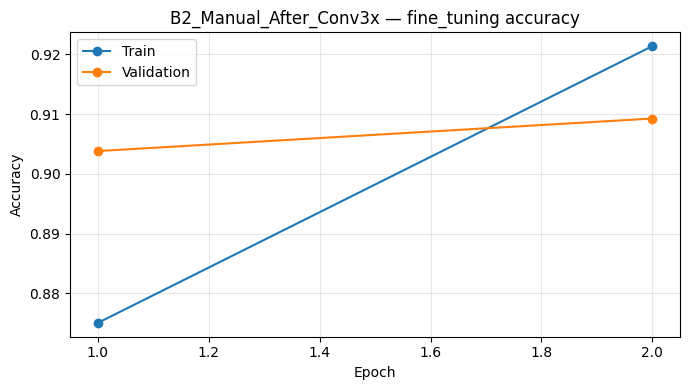

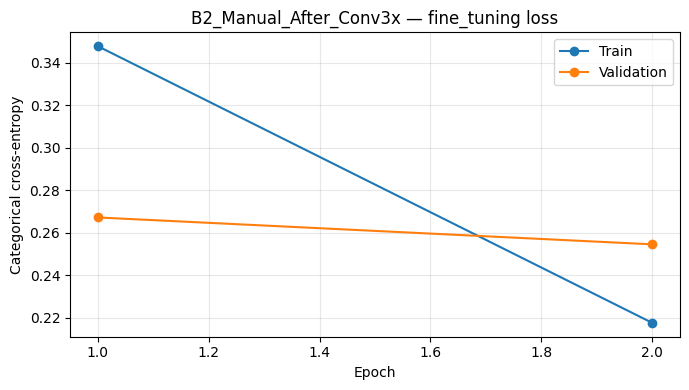

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,B2_Manual_After_Conv3x,{'after_conv3_x': 'channel_spatial'},7,0.3,0.903811,0.909256,0.909256,0.254604,15019655,23631367,70.86305,76.250506,29.541153,/kaggle/working/lab8_attention_outputs/B2_Manu...


In [99]:
# 15. Experiment 2 — B2: Channel→Spatial after conv3_x (28×28, 512 channels)
record_B2_manual = train_manual_position_experiment("B2_Manual_After_Conv3x", attention_stage=3)


Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 34s 71ms/step - accuracy: 0.7797 - loss: 0.5847 - val_accuracy: 0.8802 - val_loss: 0.3108
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.9112 - loss: 0.2547 - val_accuracy: 0.8966 - val_loss: 0.2619
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.9369 - loss: 0.1814 - val_accuracy: 0.8947 - val_loss: 0.2652


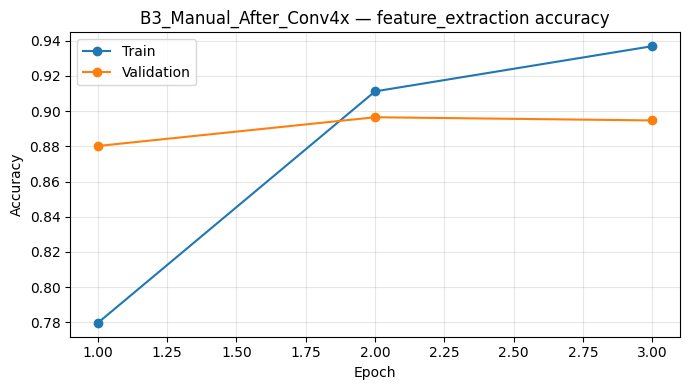

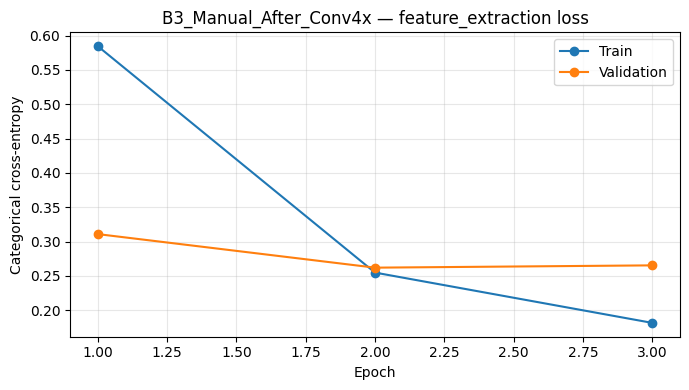

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 50s 98ms/step - accuracy: 0.8805 - loss: 0.3191 - val_accuracy: 0.9129 - val_loss: 0.2707
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 20s 60ms/step - accuracy: 0.9330 - loss: 0.1787 - val_accuracy: 0.9220 - val_loss: 0.2560


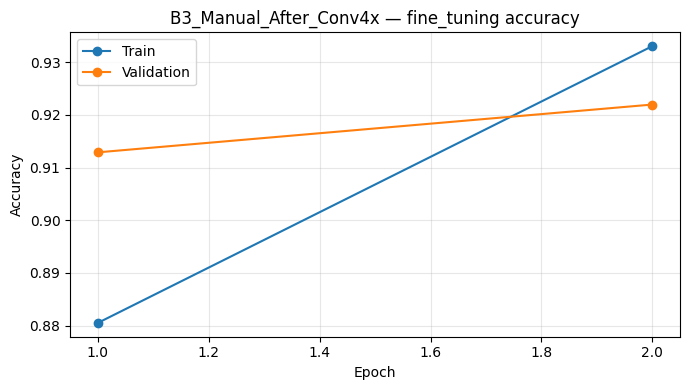

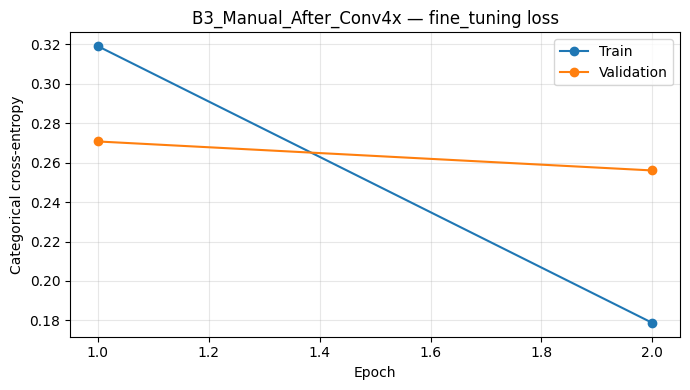

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,B3_Manual_After_Conv4x,{'after_conv4_x': 'channel_spatial'},7,0.3,0.896552,0.92196,0.92196,0.256033,15118503,23730215,61.445416,70.081013,29.41622,/kaggle/working/lab8_attention_outputs/B3_Manu...


In [100]:
# 15. Experiment 2 — B3: Channel→Spatial after conv4_x (14×14, 1024 channels)
record_B3_manual = train_manual_position_experiment("B3_Manual_After_Conv4x", attention_stage=4)


Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 32s 65ms/step - accuracy: 0.8116 - loss: 0.5257 - val_accuracy: 0.9020 - val_loss: 0.2895
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.9155 - loss: 0.2338 - val_accuracy: 0.9274 - val_loss: 0.2498
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.9463 - loss: 0.1481 - val_accuracy: 0.9147 - val_loss: 0.2898


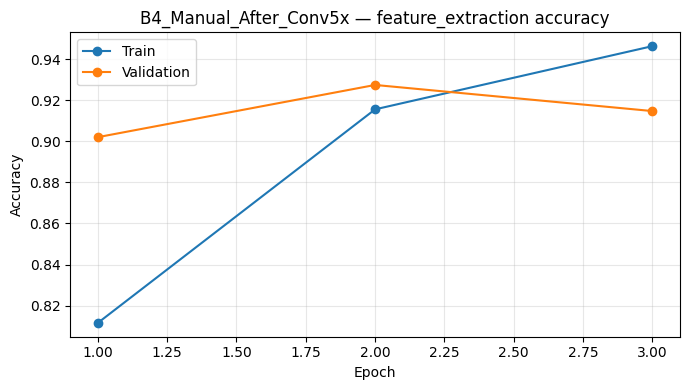

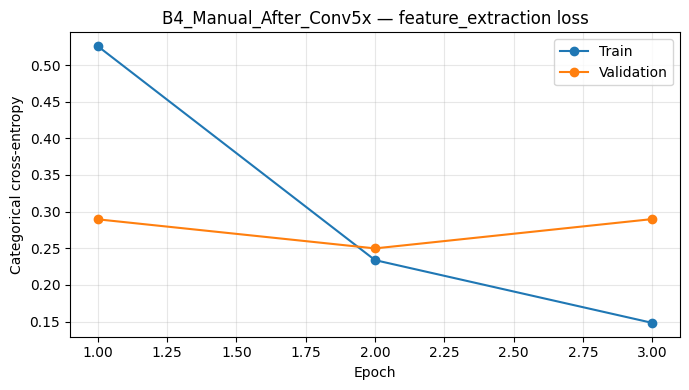

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 49s 97ms/step - accuracy: 0.9019 - loss: 0.2681 - val_accuracy: 0.9274 - val_loss: 0.2408
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 20s 59ms/step - accuracy: 0.9482 - loss: 0.1502 - val_accuracy: 0.9292 - val_loss: 0.2263


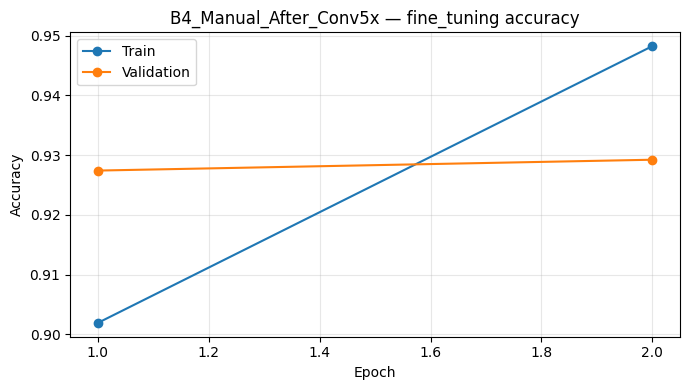

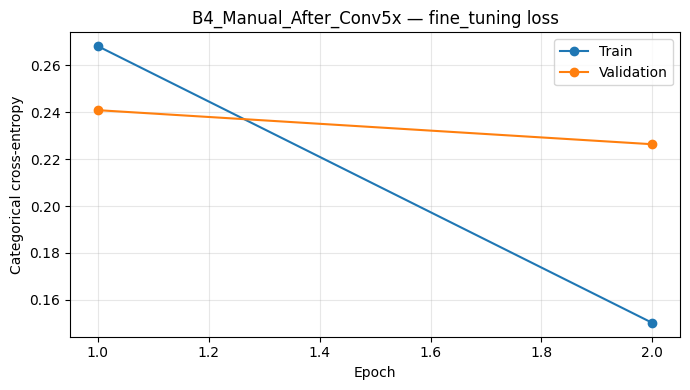

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,B4_Manual_After_Conv5x,{'after_conv5_x': 'channel_spatial'},7,0.3,0.927405,0.92922,0.92922,0.226317,15512807,24124519,56.10555,69.323807,29.578002,/kaggle/working/lab8_attention_outputs/B4_Manu...


In [101]:
# 15. Experiment 2 — B4: Channel→Spatial after conv5_x (7×7, 2048 channels)
record_B4_manual = train_manual_position_experiment("B4_Manual_After_Conv5x", attention_stage=5)


In [102]:
# Manual-aligned B1–B4 records are appended by train_manual_position_experiment().
pd.DataFrame(records).to_csv(results_path, index=False)
display(pd.DataFrame([r for r in records if str(r.get("Experiment", "")).startswith("B") and "Manual_After_Conv" in str(r.get("Experiment", ""))]))


,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,B1_Manual_After_Conv2x,{'after_conv2_x': 'channel_spatial'},7,0.3,0.847550,0.892922,0.892922,0.349025,14994807,23606519,79.737723,81.700562,29.816722,/kaggle/working/lab8_attention_outputs/B1_Manu...
1,B2_Manual_After_Conv3x,{'after_conv3_x': 'channel_spatial'},7,0.3,0.903811,0.909256,0.909256,0.254604,15019655,23631367,70.863050,76.250506,29.541153,/kaggle/working/lab8_attention_outputs/B2_Manu...
2,B3_Manual_After_Conv4x,{'after_conv4_x': 'channel_spatial'},7,0.3,0.896552,0.921960,0.921960,0.256033,15118503,23730215,61.445416,70.081013,29.416220,/kaggle/working/lab8_attention_outputs/B3_Manu...
3,B4_Manual_After_Conv5x,{'after_conv5_x': 'channel_spatial'},7,0.3,0.927405,0.929220,0.929220,0.226317,15512807,24124519,56.105550,69.323807,29.578002,/kaggle/working/lab8_attention_outputs/B4_Manu...


In [103]:
pd.DataFrame(records).to_csv(results_path, index=False)


In [104]:
# Manual-aligned Experiment 2 results are stored in all_experiment_results.csv.



EXPERIMENT: C1_Spatial_P3_only 
Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 34s 71ms/step - accuracy: 0.7610 - loss: 0.6316 - val_accuracy: 0.8838 - val_loss: 0.3039
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.9027 - loss: 0.2685 - val_accuracy: 0.9147 - val_loss: 0.2580
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.9334 - loss: 0.1958 - val_accuracy: 0.9147 - val_loss: 0.2529


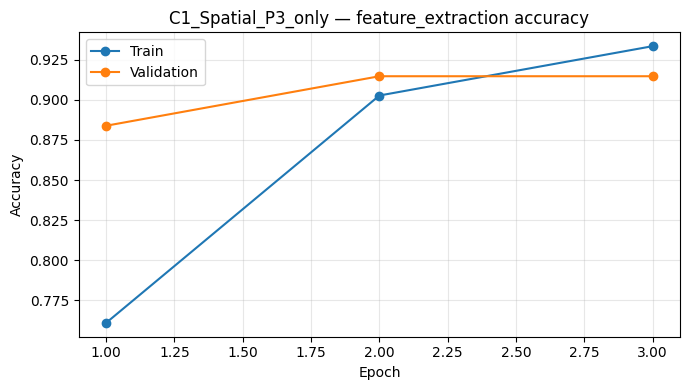

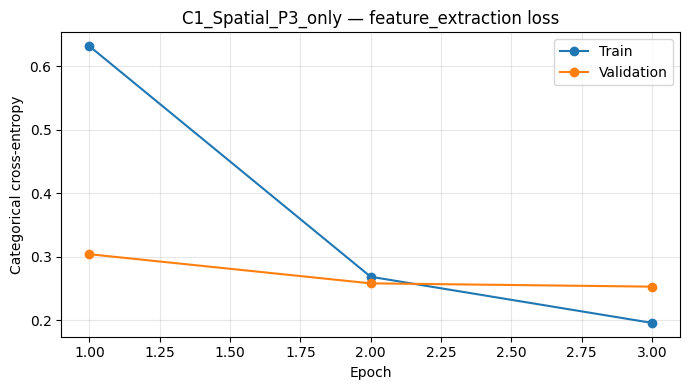

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 50s 97ms/step - accuracy: 0.8836 - loss: 0.3489 - val_accuracy: 0.9256 - val_loss: 0.2565
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 20s 61ms/step - accuracy: 0.9245 - loss: 0.2101 - val_accuracy: 0.9274 - val_loss: 0.2444


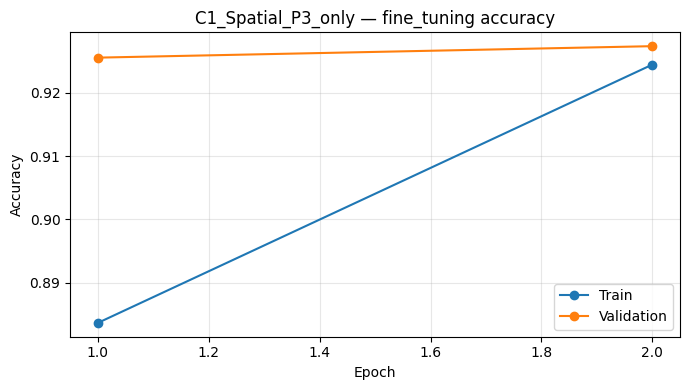

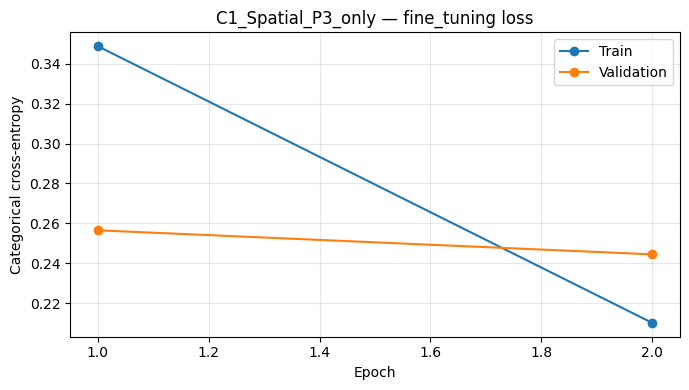

        Experiment             Attention map  Kernel  Dropout  Feature extraction best val accuracy  Fine-tuning best val accuracy  Final validation accuracy  Final validation loss  Trainable parameters after fine-tuning  Total parameters  Feature extraction seconds  Fine-tuning seconds  Inference ms/image                                                              Weights
C1_Spatial_P3_only {'P3': 'channel_spatial'}       7      0.3                              0.914701                       0.927405                   0.927405               0.244445                                15118503          23730215                    61.47367             70.16996            29.50922 /kaggle/working/lab8_attention_outputs/C1_Spatial_P3_only.weights.h5


In [105]:
# C1 — Attention at P3 only

record = train_one_experiment("C1_Spatial_P3_only", attention_map={'P3': 'channel_spatial'})


In [106]:
records.append(record)


In [107]:
pd.DataFrame(records).to_csv(results_path, index=False)


In [108]:
display(pd.DataFrame([record]))

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,C1_Spatial_P3_only,{'P3': 'channel_spatial'},7,0.3,0.914701,0.927405,0.927405,0.244445,15118503,23730215,61.47367,70.16996,29.50922,/kaggle/working/lab8_attention_outputs/C1_Spat...



EXPERIMENT: C2_Spatial_P4_only 
Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 32s 65ms/step - accuracy: 0.8132 - loss: 0.5198 - val_accuracy: 0.8966 - val_loss: 0.3311
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.9128 - loss: 0.2321 - val_accuracy: 0.9111 - val_loss: 0.2654
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.9548 - loss: 0.1301 - val_accuracy: 0.9274 - val_loss: 0.2637


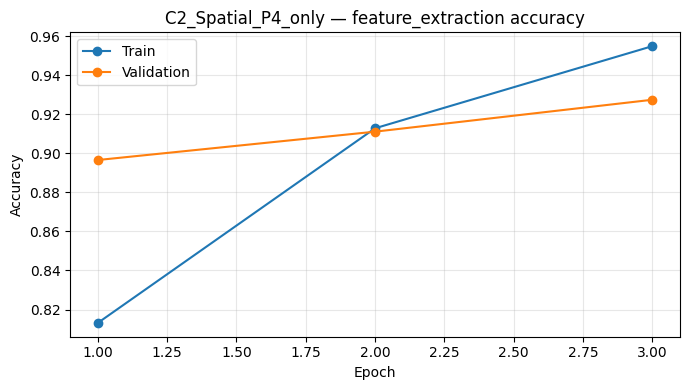

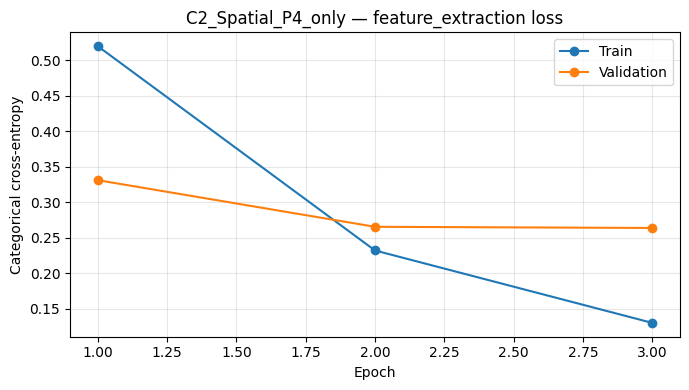

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 49s 95ms/step - accuracy: 0.9109 - loss: 0.2451 - val_accuracy: 0.9238 - val_loss: 0.2491
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 20s 59ms/step - accuracy: 0.9537 - loss: 0.1350 - val_accuracy: 0.9274 - val_loss: 0.2368


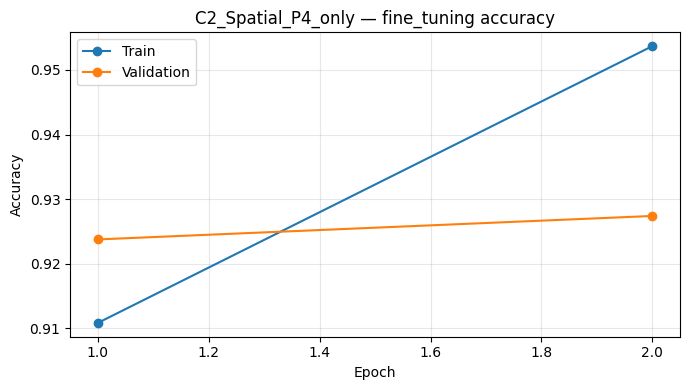

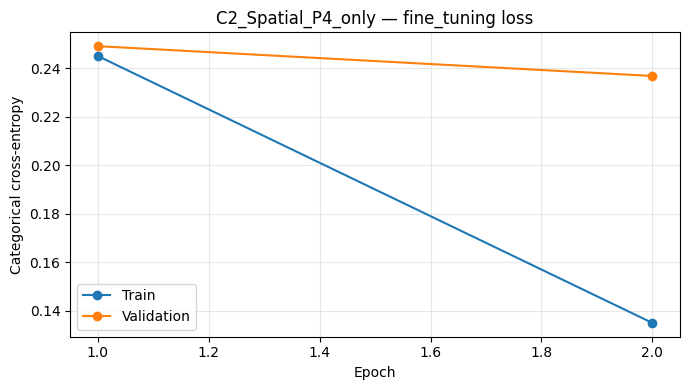

        Experiment             Attention map  Kernel  Dropout  Feature extraction best val accuracy  Fine-tuning best val accuracy  Final validation accuracy  Final validation loss  Trainable parameters after fine-tuning  Total parameters  Feature extraction seconds  Fine-tuning seconds  Inference ms/image                                                              Weights
C2_Spatial_P4_only {'P4': 'channel_spatial'}       7      0.3                              0.927405                       0.927405                   0.927405               0.236839                                15512807          24124519                   55.946852             68.53342           29.672722 /kaggle/working/lab8_attention_outputs/C2_Spatial_P4_only.weights.h5


In [109]:
# C2 — Attention at P4 only

record = train_one_experiment("C2_Spatial_P4_only", attention_map={'P4': 'channel_spatial'})


In [110]:
records.append(record)


In [111]:
pd.DataFrame(records).to_csv(results_path, index=False)


In [112]:
display(pd.DataFrame([record]))

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,C2_Spatial_P4_only,{'P4': 'channel_spatial'},7,0.3,0.927405,0.927405,0.927405,0.236839,15512807,24124519,55.946852,68.53342,29.672722,/kaggle/working/lab8_attention_outputs/C2_Spat...



EXPERIMENT: C3_ChannelSpatial_P3_P4 
Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 37s 75ms/step - accuracy: 0.8038 - loss: 0.5227 - val_accuracy: 0.8929 - val_loss: 0.3173
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.9194 - loss: 0.2398 - val_accuracy: 0.9093 - val_loss: 0.2725
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.9533 - loss: 0.1376 - val_accuracy: 0.8929 - val_loss: 0.2961


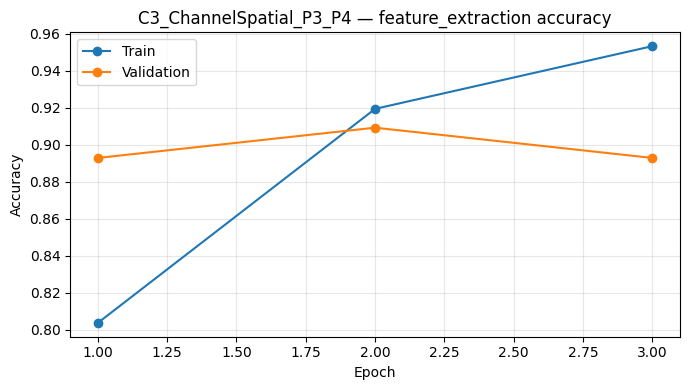

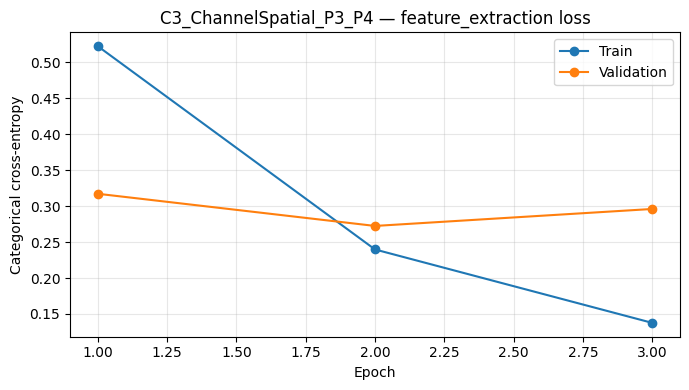

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 53s 103ms/step - accuracy: 0.8957 - loss: 0.2901 - val_accuracy: 0.9201 - val_loss: 0.2558
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 20s 61ms/step - accuracy: 0.9447 - loss: 0.1593 - val_accuracy: 0.9201 - val_loss: 0.2447


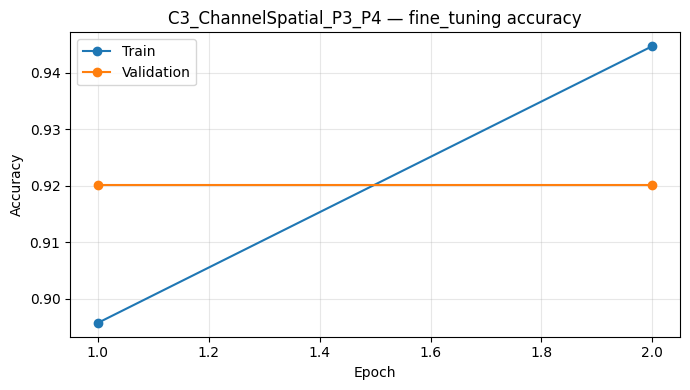

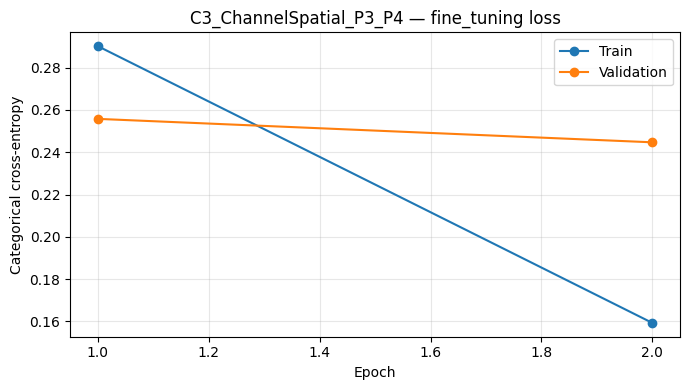

             Experiment                                      Attention map  Kernel  Dropout  Feature extraction best val accuracy  Fine-tuning best val accuracy  Final validation accuracy  Final validation loss  Trainable parameters after fine-tuning  Total parameters  Feature extraction seconds  Fine-tuning seconds  Inference ms/image                                                                   Weights
C3_ChannelSpatial_P3_P4 {'P3': 'channel_spatial', 'P4': 'channel_spatial'}       7      0.3                              0.909256                       0.920145                   0.920145               0.244683                                15645065          24256777                   64.507234            73.656507           30.546165 /kaggle/working/lab8_attention_outputs/C3_ChannelSpatial_P3_P4.weights.h5


In [113]:
# C3 — Attention at P3 and P4

record = train_one_experiment("C3_ChannelSpatial_P3_P4", attention_map={'P3': 'channel_spatial', 'P4': 'channel_spatial'})


In [114]:
records.append(record)


In [115]:
pd.DataFrame(records).to_csv(results_path, index=False)


In [116]:
display(pd.DataFrame([record]))

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,C3_ChannelSpatial_P3_P4,"{'P3': 'channel_spatial', 'P4': 'channel_spati...",7,0.3,0.909256,0.920145,0.920145,0.244683,15645065,24256777,64.507234,73.656507,30.546165,/kaggle/working/lab8_attention_outputs/C3_Chan...



EXPERIMENT: D1_Channel_then_Spatial_P3 
Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 35s 72ms/step - accuracy: 0.7587 - loss: 0.6140 - val_accuracy: 0.8566 - val_loss: 0.3507
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.8976 - loss: 0.2812 - val_accuracy: 0.9020 - val_loss: 0.2768
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.9253 - loss: 0.2041 - val_accuracy: 0.8911 - val_loss: 0.3069


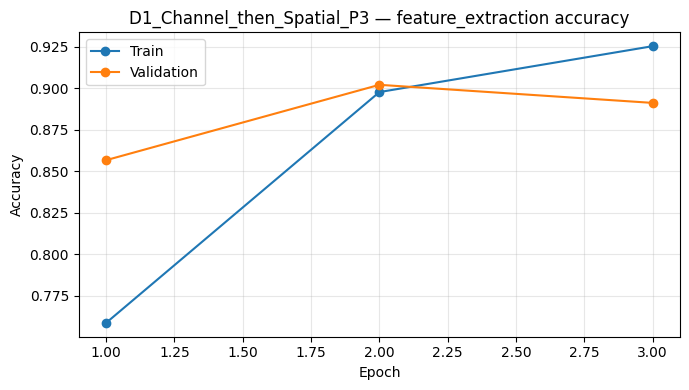

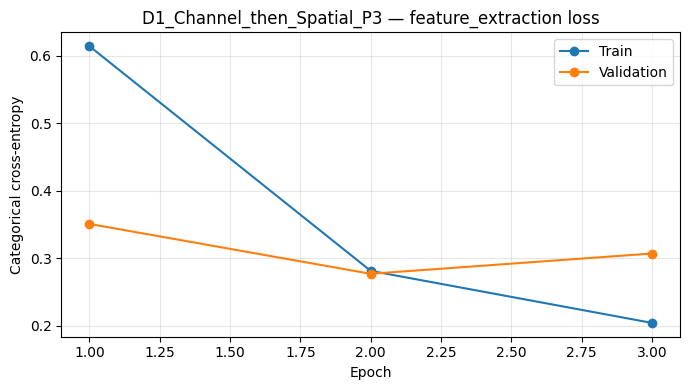

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 50s 98ms/step - accuracy: 0.8708 - loss: 0.3693 - val_accuracy: 0.9165 - val_loss: 0.2790
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 20s 60ms/step - accuracy: 0.9241 - loss: 0.2114 - val_accuracy: 0.9220 - val_loss: 0.2585


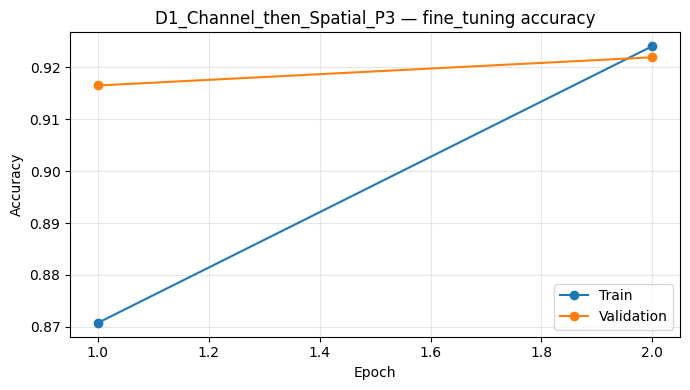

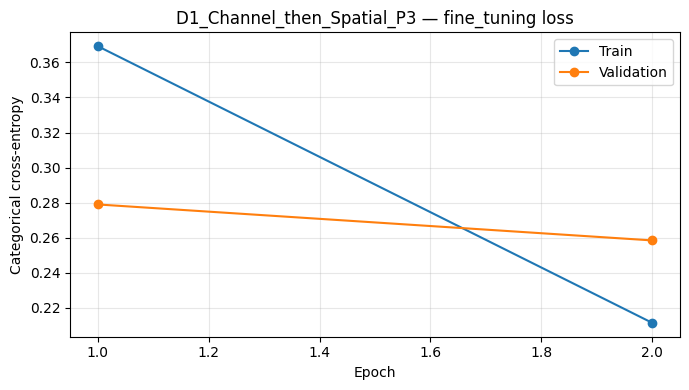

                Experiment             Attention map  Kernel  Dropout  Feature extraction best val accuracy  Fine-tuning best val accuracy  Final validation accuracy  Final validation loss  Trainable parameters after fine-tuning  Total parameters  Feature extraction seconds  Fine-tuning seconds  Inference ms/image                                                                      Weights
D1_Channel_then_Spatial_P3 {'P3': 'channel_spatial'}       7      0.3                              0.901996                        0.92196                    0.92196               0.258462                                15118503          23730215                   61.934253            70.264741           29.833178 /kaggle/working/lab8_attention_outputs/D1_Channel_then_Spatial_P3.weights.h5


In [117]:
# D1 — Channel then spatial order

record = train_one_experiment("D1_Channel_then_Spatial_P3", attention_map={'P3': 'channel_spatial'})


In [118]:
records.append(record)


In [119]:
pd.DataFrame(records).to_csv(results_path, index=False)


In [120]:
display(pd.DataFrame([record]))

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,D1_Channel_then_Spatial_P3,{'P3': 'channel_spatial'},7,0.3,0.901996,0.92196,0.92196,0.258462,15118503,23730215,61.934253,70.264741,29.833178,/kaggle/working/lab8_attention_outputs/D1_Chan...



EXPERIMENT: D2_Spatial_then_Channel_P3 
Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 34s 71ms/step - accuracy: 0.7602 - loss: 0.6342 - val_accuracy: 0.8621 - val_loss: 0.3332
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.9007 - loss: 0.2663 - val_accuracy: 0.8929 - val_loss: 0.2908
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.9342 - loss: 0.1952 - val_accuracy: 0.9074 - val_loss: 0.2546


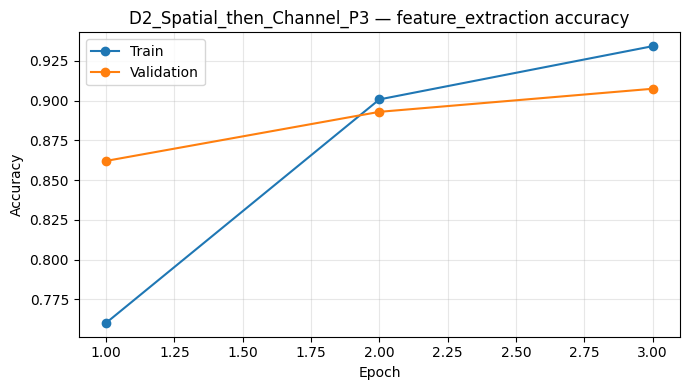

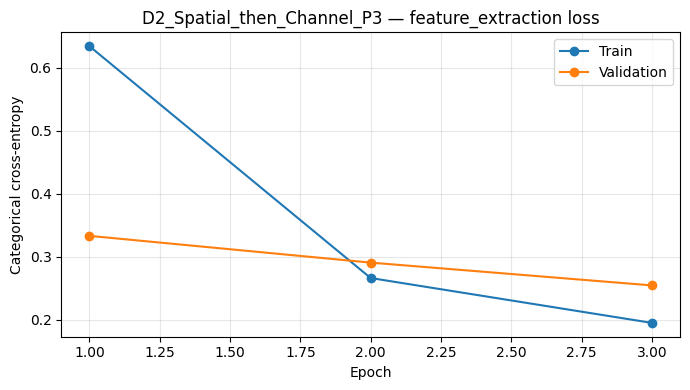

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 50s 98ms/step - accuracy: 0.8844 - loss: 0.3139 - val_accuracy: 0.9292 - val_loss: 0.2153
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 20s 60ms/step - accuracy: 0.9319 - loss: 0.1891 - val_accuracy: 0.9292 - val_loss: 0.2104


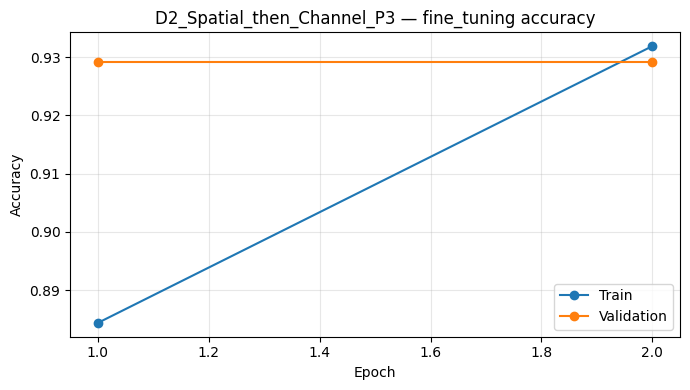

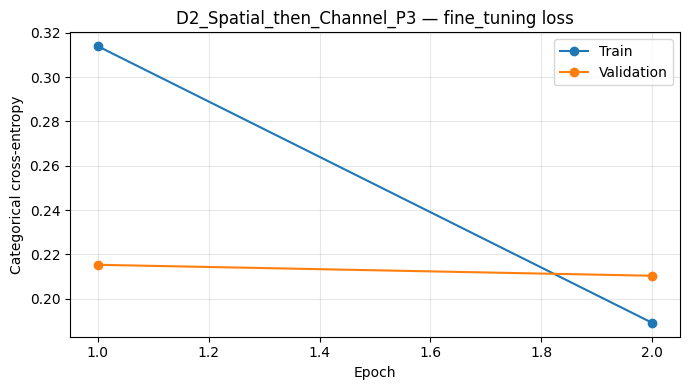

                Experiment             Attention map  Kernel  Dropout  Feature extraction best val accuracy  Fine-tuning best val accuracy  Final validation accuracy  Final validation loss  Trainable parameters after fine-tuning  Total parameters  Feature extraction seconds  Fine-tuning seconds  Inference ms/image                                                                      Weights
D2_Spatial_then_Channel_P3 {'P3': 'spatial_channel'}       7      0.3                              0.907441                        0.92922                    0.92922               0.210396                                15118503          23730215                   61.939805            70.252346           29.656873 /kaggle/working/lab8_attention_outputs/D2_Spatial_then_Channel_P3.weights.h5


In [121]:
# D2 — Spatial then channel order

record = train_one_experiment("D2_Spatial_then_Channel_P3", attention_map={'P3': 'spatial_channel'})


In [122]:
records.append(record)


In [123]:
pd.DataFrame(records).to_csv(results_path, index=False)


In [124]:
display(pd.DataFrame([record]))

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,D2_Spatial_then_Channel_P3,{'P3': 'spatial_channel'},7,0.3,0.907441,0.92922,0.92922,0.210396,15118503,23730215,61.939805,70.252346,29.656873,/kaggle/working/lab8_attention_outputs/D2_Spat...



EXPERIMENT: E_SpatialKernel_3x3_P3 
Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 33s 69ms/step - accuracy: 0.2083 - loss: 1.6536 - val_accuracy: 0.2668 - val_loss: 1.6137
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.3184 - loss: 1.4977 - val_accuracy: 0.7659 - val_loss: 0.6738
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.8373 - loss: 0.5017 - val_accuracy: 0.8784 - val_loss: 0.3448


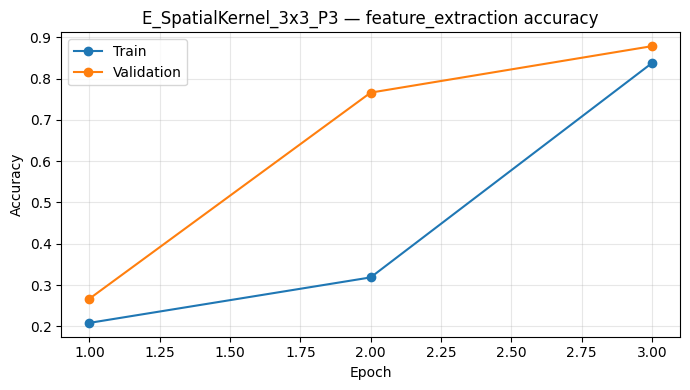

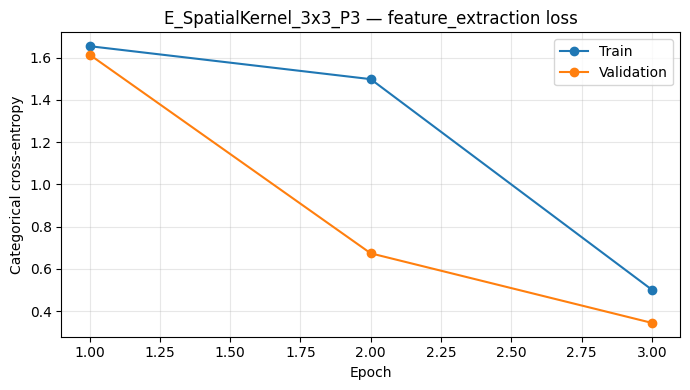

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 48s 96ms/step - accuracy: 0.8525 - loss: 0.4881 - val_accuracy: 0.9038 - val_loss: 0.3397
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 20s 60ms/step - accuracy: 0.8961 - loss: 0.2871 - val_accuracy: 0.9056 - val_loss: 0.3040


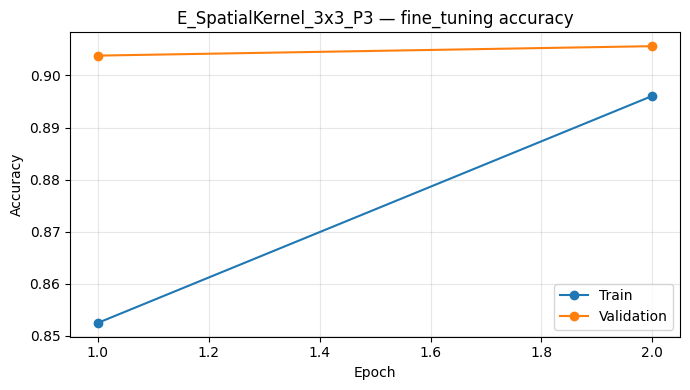

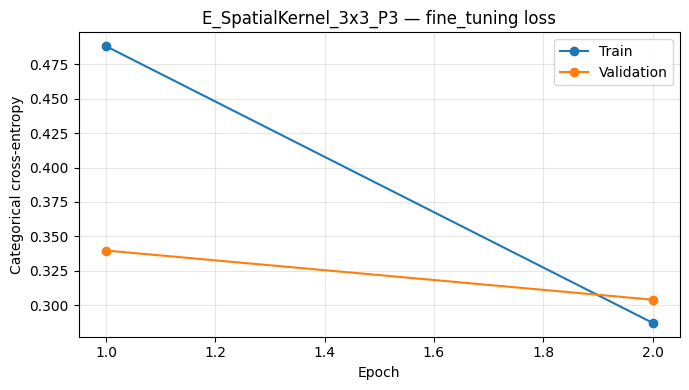

            Experiment     Attention map  Kernel  Dropout  Feature extraction best val accuracy  Fine-tuning best val accuracy  Final validation accuracy  Final validation loss  Trainable parameters after fine-tuning  Total parameters  Feature extraction seconds  Fine-tuning seconds  Inference ms/image                                                                  Weights
E_SpatialKernel_3x3_P3 {'P3': 'spatial'}       3      0.3                              0.878403                       0.905626                   0.905626               0.303972                                14986263          23597975                   59.875689            68.209188           29.371025 /kaggle/working/lab8_attention_outputs/E_SpatialKernel_3x3_P3.weights.h5


In [125]:
# E1 — Spatial attention with a 3 x 3 kernel

record = train_one_experiment("E_SpatialKernel_3x3_P3", attention_map={'P3': 'spatial'}, kernel_size=3)


In [126]:
records.append(record)


In [127]:
pd.DataFrame(records).to_csv(results_path, index=False)


In [128]:
display(pd.DataFrame([record]))

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,E_SpatialKernel_3x3_P3,{'P3': 'spatial'},3,0.3,0.878403,0.905626,0.905626,0.303972,14986263,23597975,59.875689,68.209188,29.371025,/kaggle/working/lab8_attention_outputs/E_Spati...



EXPERIMENT: E_SpatialKernel_5x5_P3 
Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 33s 69ms/step - accuracy: 0.6649 - loss: 0.8312 - val_accuracy: 0.8475 - val_loss: 0.4804
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.8957 - loss: 0.2971 - val_accuracy: 0.9038 - val_loss: 0.3300
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.9124 - loss: 0.2296 - val_accuracy: 0.9020 - val_loss: 0.3190


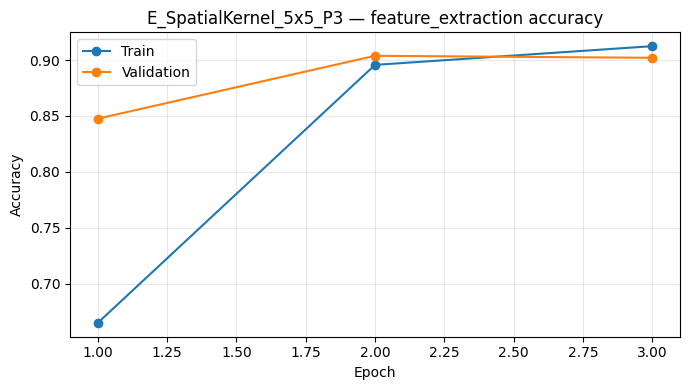

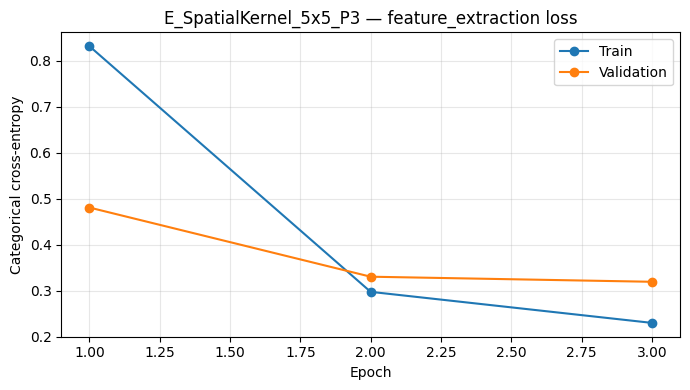

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 48s 96ms/step - accuracy: 0.8840 - loss: 0.3173 - val_accuracy: 0.9183 - val_loss: 0.2845
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 20s 60ms/step - accuracy: 0.9404 - loss: 0.1726 - val_accuracy: 0.9201 - val_loss: 0.2732


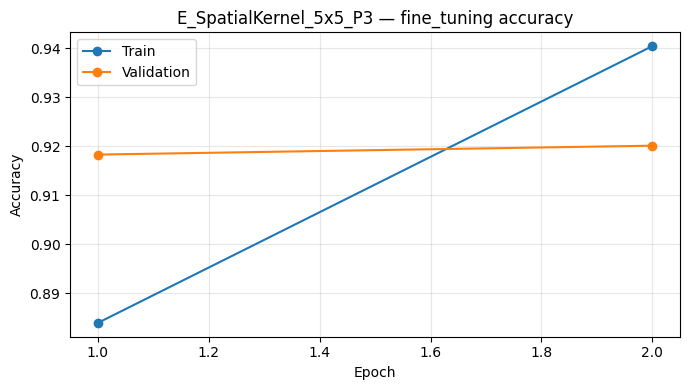

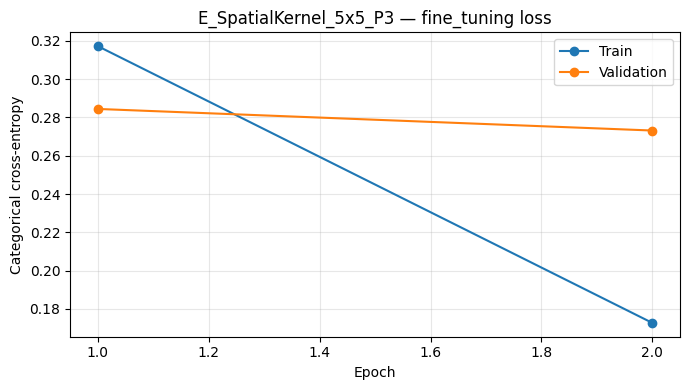

            Experiment     Attention map  Kernel  Dropout  Feature extraction best val accuracy  Fine-tuning best val accuracy  Final validation accuracy  Final validation loss  Trainable parameters after fine-tuning  Total parameters  Feature extraction seconds  Fine-tuning seconds  Inference ms/image                                                                  Weights
E_SpatialKernel_5x5_P3 {'P3': 'spatial'}       5      0.3                              0.903811                       0.920145                   0.920145               0.273187                                14986295          23598007                   59.943055            68.313861            29.34077 /kaggle/working/lab8_attention_outputs/E_SpatialKernel_5x5_P3.weights.h5


In [129]:
# E2 — Spatial attention with a 5 x 5 kernel

record = train_one_experiment("E_SpatialKernel_5x5_P3", attention_map={'P3': 'spatial'}, kernel_size=5)


In [130]:
records.append(record)


In [131]:
pd.DataFrame(records).to_csv(results_path, index=False)


In [132]:
display(pd.DataFrame([record]))

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,E_SpatialKernel_5x5_P3,{'P3': 'spatial'},5,0.3,0.903811,0.920145,0.920145,0.273187,14986295,23598007,59.943055,68.313861,29.34077,/kaggle/working/lab8_attention_outputs/E_Spati...



EXPERIMENT: E_SpatialKernel_7x7_P3 
Epoch 1/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 33s 69ms/step - accuracy: 0.7143 - loss: 0.7511 - val_accuracy: 0.8911 - val_loss: 0.3119
Epoch 2/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.9011 - loss: 0.2815 - val_accuracy: 0.9238 - val_loss: 0.2709
Epoch 3/3
322/322 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.9136 - loss: 0.2354 - val_accuracy: 0.9074 - val_loss: 0.2825


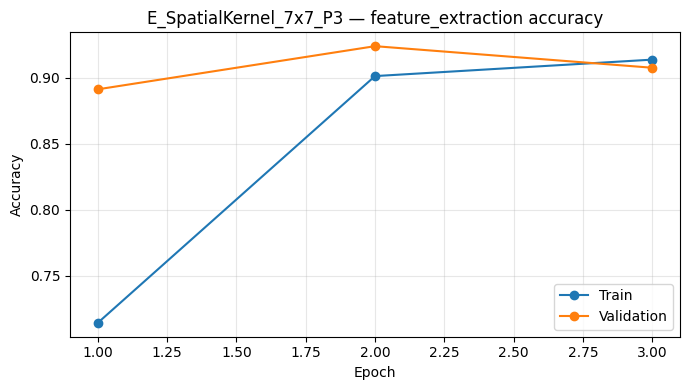

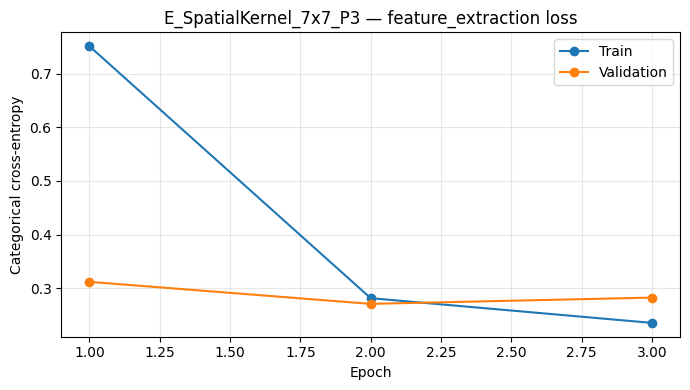

Epoch 1/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 48s 96ms/step - accuracy: 0.8891 - loss: 0.3002 - val_accuracy: 0.9292 - val_loss: 0.2344
Epoch 2/2
322/322 ━━━━━━━━━━━━━━━━━━━━ 20s 60ms/step - accuracy: 0.9346 - loss: 0.1860 - val_accuracy: 0.9201 - val_loss: 0.2321


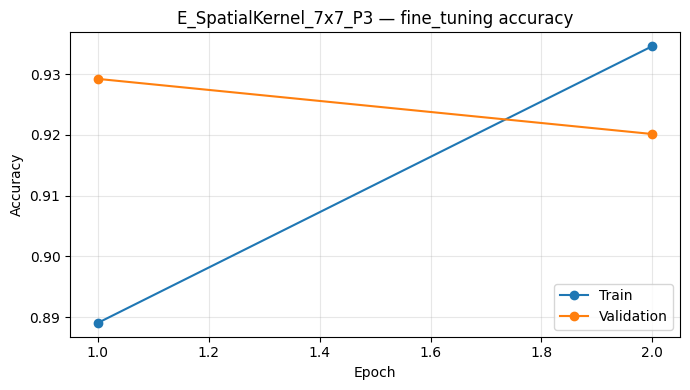

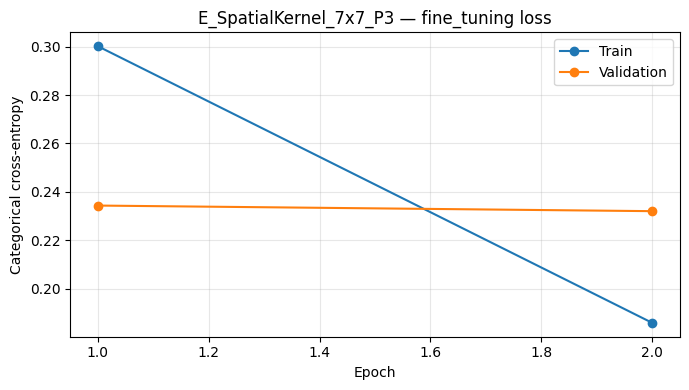

            Experiment     Attention map  Kernel  Dropout  Feature extraction best val accuracy  Fine-tuning best val accuracy  Final validation accuracy  Final validation loss  Trainable parameters after fine-tuning  Total parameters  Feature extraction seconds  Fine-tuning seconds  Inference ms/image                                                                  Weights
E_SpatialKernel_7x7_P3 {'P3': 'spatial'}       7      0.3                              0.923775                        0.92922                   0.920145               0.232069                                14986343          23598055                   59.648312            67.988393           29.173237 /kaggle/working/lab8_attention_outputs/E_SpatialKernel_7x7_P3.weights.h5


In [133]:
# E3 — Spatial attention with a 7 x 7 kernel

record = train_one_experiment("E_SpatialKernel_7x7_P3", attention_map={'P3': 'spatial'})


In [134]:
records.append(record)


In [135]:
pd.DataFrame(records).to_csv(results_path, index=False)


In [136]:
display(pd.DataFrame([record]))

,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,E_SpatialKernel_7x7_P3,{'P3': 'spatial'},7,0.3,0.923775,0.92922,0.920145,0.232069,14986343,23598055,59.648312,67.988393,29.173237,/kaggle/working/lab8_attention_outputs/E_Spati...


In [137]:
# 11. Compile results from all completed experiments
results_df = pd.DataFrame(records)
if not results_df.empty:
    results_df.to_csv(os.path.join(OUTPUT_DIR, "all_experiment_results.csv"), index=False)
    display(results_df.sort_values("Fine-tuning best val accuracy", ascending=False))
else:
    print("No completed experiment records are available yet.")


,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,A0_Baseline,{},7,0.3,0.920145,0.932849,0.932849,0.227570,14986245,23597957,55.019885,66.232038,29.907274,/kaggle/working/lab8_attention_outputs/A0_Base...
2,A2_Spatial_P3,{'P3': 'spatial'},7,0.3,0.923775,0.932849,0.932849,0.233016,14986343,23598055,59.947142,68.980458,29.439627,/kaggle/working/lab8_attention_outputs/A2_Spat...
3,A3_ChannelSpatial_P3,{'P3': 'channel_spatial'},7,0.3,0.925590,0.931035,0.931035,0.238371,15118503,23730215,62.023563,70.179173,30.203520,/kaggle/working/lab8_attention_outputs/A3_Chan...
5,A5_Combined_P3,{'P3': 'combined'},7,0.3,0.882033,0.929220,0.929220,0.215501,15642791,24254503,66.537703,73.520301,30.374126,/kaggle/working/lab8_attention_outputs/A5_Comb...
19,D2_Spatial_then_Channel_P3,{'P3': 'spatial_channel'},7,0.3,0.907441,0.929220,0.929220,0.210396,15118503,23730215,61.939805,70.252346,29.656873,/kaggle/working/lab8_attention_outputs/D2_Spat...
22,E_SpatialKernel_7x7_P3,{'P3': 'spatial'},7,0.3,0.923775,0.929220,0.920145,0.232069,14986343,23598055,59.648312,67.988393,29.173237,/kaggle/working/lab8_attention_outputs/E_Spati...
14,B4_Manual_After_Conv5x,{'after_conv5_x': 'channel_spatial'},7,0.3,0.927405,0.929220,0.929220,0.226317,15512807,24124519,56.105550,69.323807,29.578002,/kaggle/working/lab8_attention_outputs/B4_Manu...
16,C2_Spatial_P4_only,{'P4': 'channel_spatial'},7,0.3,0.927405,0.927405,0.927405,0.236839,15512807,24124519,55.946852,68.533420,29.672722,/kaggle/working/lab8_attention_outputs/C2_Spat...
15,C1_Spatial_P3_only,{'P3': 'channel_spatial'},7,0.3,0.914701,0.927405,0.927405,0.244445,15118503,23730215,61.473670,70.169960,29.509220,/kaggle/working/lab8_attention_outputs/C1_Spat...
1,A1_Channel_P3,{'P3': 'channel'},7,0.3,0.920145,0.925590,0.925590,0.223690,15118405,23730117,60.448900,69.294149,29.668882,/kaggle/working/lab8_attention_outputs/A1_Chan...


In [138]:
results_df.to_csv(os.path.join(OUTPUT_DIR, "all_experiment_results.csv"), index=False)


In [139]:
display(results_df.sort_values("Fine-tuning best val accuracy", ascending=False))


,Experiment,Attention map,Kernel,Dropout,Feature extraction best val accuracy,Fine-tuning best val accuracy,Final validation accuracy,Final validation loss,Trainable parameters after fine-tuning,Total parameters,Feature extraction seconds,Fine-tuning seconds,Inference ms/image,Weights
0,A0_Baseline,{},7,0.3,0.920145,0.932849,0.932849,0.227570,14986245,23597957,55.019885,66.232038,29.907274,/kaggle/working/lab8_attention_outputs/A0_Base...
2,A2_Spatial_P3,{'P3': 'spatial'},7,0.3,0.923775,0.932849,0.932849,0.233016,14986343,23598055,59.947142,68.980458,29.439627,/kaggle/working/lab8_attention_outputs/A2_Spat...
3,A3_ChannelSpatial_P3,{'P3': 'channel_spatial'},7,0.3,0.925590,0.931035,0.931035,0.238371,15118503,23730215,62.023563,70.179173,30.203520,/kaggle/working/lab8_attention_outputs/A3_Chan...
5,A5_Combined_P3,{'P3': 'combined'},7,0.3,0.882033,0.929220,0.929220,0.215501,15642791,24254503,66.537703,73.520301,30.374126,/kaggle/working/lab8_attention_outputs/A5_Comb...
19,D2_Spatial_then_Channel_P3,{'P3': 'spatial_channel'},7,0.3,0.907441,0.929220,0.929220,0.210396,15118503,23730215,61.939805,70.252346,29.656873,/kaggle/working/lab8_attention_outputs/D2_Spat...
22,E_SpatialKernel_7x7_P3,{'P3': 'spatial'},7,0.3,0.923775,0.929220,0.920145,0.232069,14986343,23598055,59.648312,67.988393,29.173237,/kaggle/working/lab8_attention_outputs/E_Spati...
14,B4_Manual_After_Conv5x,{'after_conv5_x': 'channel_spatial'},7,0.3,0.927405,0.929220,0.929220,0.226317,15512807,24124519,56.105550,69.323807,29.578002,/kaggle/working/lab8_attention_outputs/B4_Manu...
16,C2_Spatial_P4_only,{'P4': 'channel_spatial'},7,0.3,0.927405,0.927405,0.927405,0.236839,15512807,24124519,55.946852,68.533420,29.672722,/kaggle/working/lab8_attention_outputs/C2_Spat...
15,C1_Spatial_P3_only,{'P3': 'channel_spatial'},7,0.3,0.914701,0.927405,0.927405,0.244445,15118503,23730215,61.473670,70.169960,29.509220,/kaggle/working/lab8_attention_outputs/C1_Spat...
1,A1_Channel_P3,{'P3': 'channel'},7,0.3,0.920145,0.925590,0.925590,0.223690,15118405,23730117,60.448900,69.294149,29.668882,/kaggle/working/lab8_attention_outputs/A1_Chan...


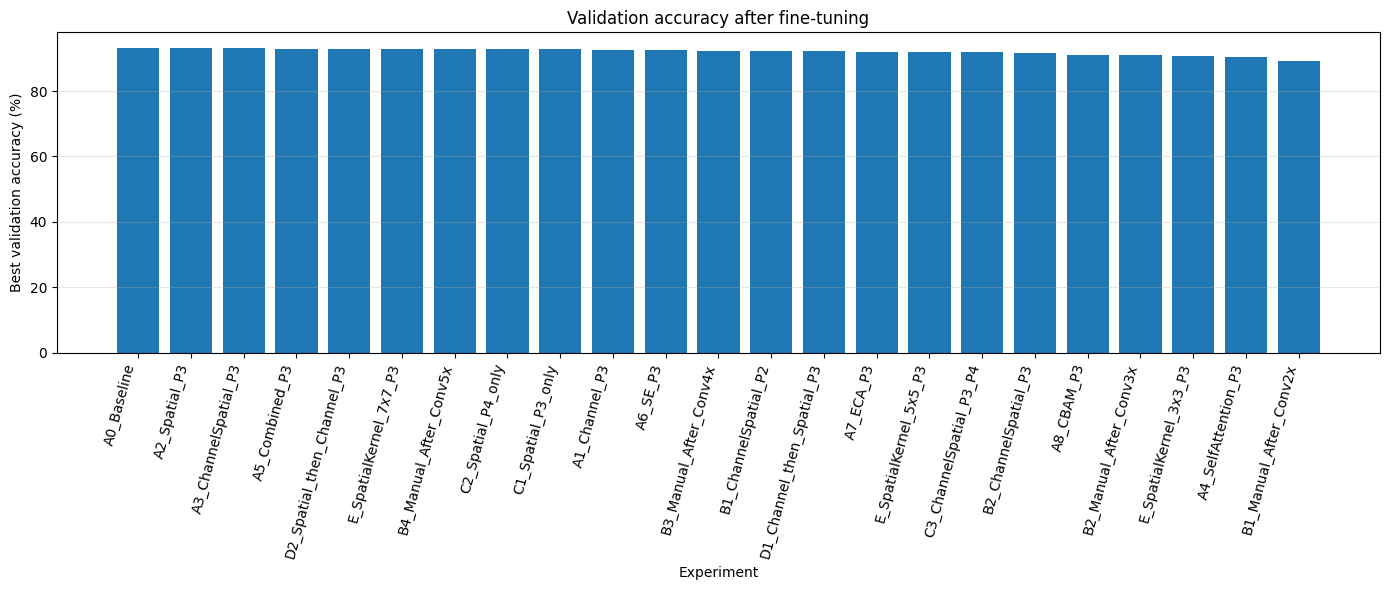

In [140]:
# 11.1 Plot validation accuracy after fine-tuning
if not results_df.empty:
    plot_df = results_df.dropna(subset=["Fine-tuning best val accuracy"]).sort_values(
        "Fine-tuning best val accuracy", ascending=False
    )
    plt.figure(figsize=(14, 6))
    plt.bar(plot_df["Experiment"], plot_df["Fine-tuning best val accuracy"] * 100)
    plt.ylabel("Best validation accuracy (%)")
    plt.xlabel("Experiment")
    plt.title("Validation accuracy after fine-tuning")
    plt.xticks(rotation=75, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "comparison_all_models_validation_accuracy.png"), dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()
else:
    print("Complete at least one experiment before plotting comparison.")


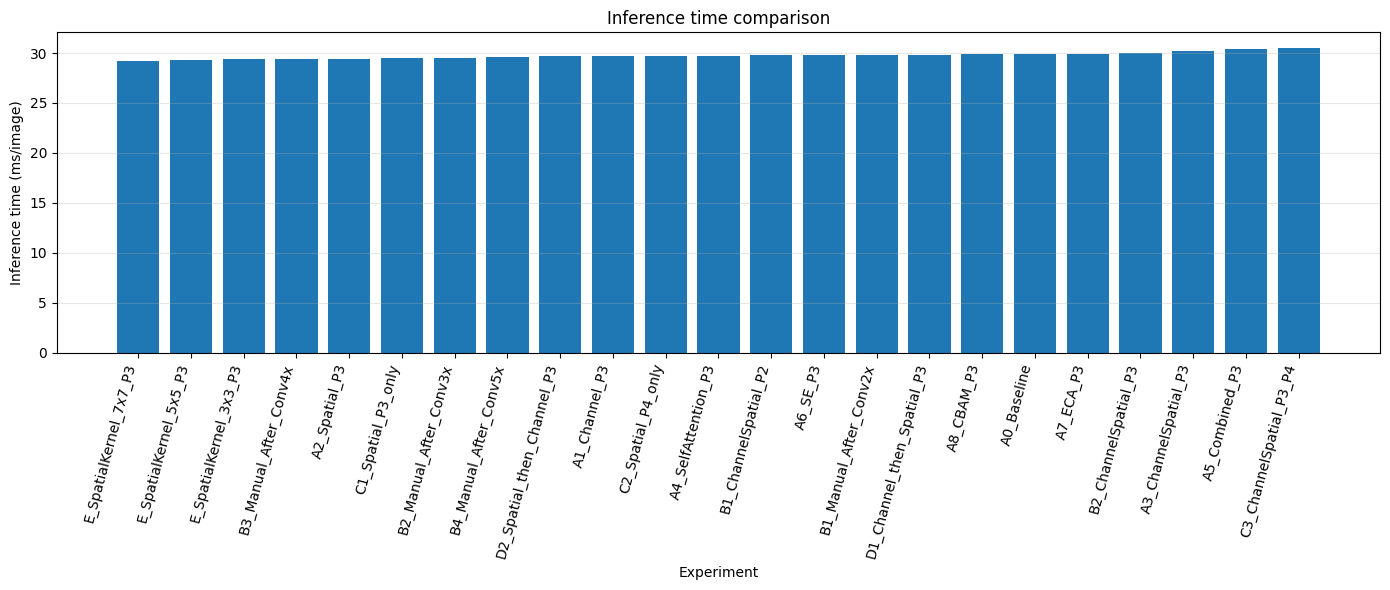

In [141]:
# 11.2 Plot inference time comparison
if not results_df.empty:
    plot_df = results_df.dropna(subset=["Inference ms/image"]).sort_values("Inference ms/image")
    plt.figure(figsize=(14, 6))
    plt.bar(plot_df["Experiment"], plot_df["Inference ms/image"])
    plt.ylabel("Inference time (ms/image)")
    plt.xlabel("Experiment")
    plt.title("Inference time comparison")
    plt.xticks(rotation=75, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "comparison_all_models_inference_time.png"), dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()
else:
    print("Complete at least one experiment before plotting inference time.")


In [142]:
# 12. Final evaluation on the test set

best_row = results_df.sort_values(
    ["Fine-tuning best val accuracy", "Final validation loss"],
    ascending=[False, True]
).iloc[0]


In [143]:
best_name = str(best_row["Experiment"])


In [144]:
best_map = eval(best_row["Attention map"])


In [145]:
best_kernel = int(best_row["Kernel"])


In [146]:
best_dropout = float(best_row["Dropout"])


In [147]:
best_weights = str(best_row["Weights"])


In [148]:
print("Selected by validation:", best_name, best_map, "kernel", best_kernel)


Selected by validation: A0_Baseline {} kernel 7


In [149]:
tf.keras.backend.clear_session()


In [150]:
best_model = build_resnet50_attention(
    attention_map=best_map, kernel_size=best_kernel,
    dropout_rate=best_dropout, learning_rate=1e-3
)


In [151]:
for layer in best_model.layers:
    if layer.name.startswith("conv5_block"):
        layer.trainable = True


In [152]:
best_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),
                   loss="categorical_crossentropy", metrics=["accuracy"])


In [153]:
best_model.load_weights(best_weights)


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 86 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [154]:
test_loss, test_acc = best_model.evaluate(test_ds, verbose=1)


69/69 ━━━━━━━━━━━━━━━━━━━━ 10s 71ms/step - accuracy: 0.9236 - loss: 0.2153


In [155]:
y_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds])


In [156]:
y_prob = best_model.predict(test_ds, verbose=1)


69/69 ━━━━━━━━━━━━━━━━━━━━ 9s 78ms/step


In [157]:
y_pred = np.argmax(y_prob, axis=1)


In [158]:
precision, recall, f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)


In [159]:
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))


              precision    recall  f1-score   support

   dandelion       0.95      0.97      0.96       112
       daisy       0.97      0.94      0.95        95
      tulips       0.90      0.90      0.90       134
  sunflowers       0.91      0.94      0.93       102
       roses       0.90      0.87      0.89       107

    accuracy                           0.92       550
   macro avg       0.93      0.92      0.93       550
weighted avg       0.92      0.92      0.92       550



In [160]:
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")


Test loss: 0.2153 | Test accuracy: 0.9236


In [161]:
print(f"Macro precision: {precision:.4f} | Macro recall: {recall:.4f} | Macro F1: {f1:.4f}")


Macro precision: 0.9257 | Macro recall: 0.9247 | Macro F1: 0.9250


In [162]:
cm = confusion_matrix(y_true, y_pred)


In [163]:
# Duplicate confusion-matrix fragment removed; complete plot is generated in cell 158.


In [164]:
# Duplicate confusion-matrix fragment removed; complete plot is generated in cell 158.


In [167]:
# Required test-set metric comparison: baseline ResNet50 vs validation-selected attention model
# Uses the held-out test set only after the selected model has been chosen by validation performance.

def evaluate_saved_experiment(experiment_name, attention_map, weight_path=None):
    if weight_path is None:
        weight_path = find_weights_file(experiment_name)
    if not weight_path or not os.path.exists(weight_path):
        print(f"Weights not found for {experiment_name}: {weight_path}")
        return None
    model = build_resnet50_attention(attention_map=attention_map, learning_rate=1e-3)
    model.load_weights(weight_path)
    true_labels = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds])
    probs = model.predict(test_ds, verbose=0)
    pred_labels = np.argmax(probs, axis=1)
    p, r, f1_value, _ = precision_recall_fscore_support(
        true_labels, pred_labels, average="macro", zero_division=0
    )
    loss, accuracy = model.evaluate(test_ds, verbose=0)
    return {"Model": experiment_name, "Test accuracy": float(accuracy),
            "Macro precision": float(p), "Macro recall": float(r), "Macro F1": float(f1_value),
            "Test loss": float(loss), "Total parameters": int(model.count_params()),
            "Weights": weight_path}

baseline_metrics = evaluate_saved_experiment("A0_Baseline", {})
selected_metrics = evaluate_saved_experiment(best_name, best_map, best_weights)
test_metric_rows = [x for x in [baseline_metrics, selected_metrics] if x is not None]
if test_metric_rows:
    test_metrics_comparison_df = pd.DataFrame(test_metric_rows)
    display(test_metrics_comparison_df)
    test_metrics_comparison_df.to_csv(os.path.join(OUTPUT_DIR, "required_baseline_vs_selected_test_metrics.csv"), index=False)
else:
    print("Could not compute test metrics: verify the baseline and selected model weight files.")


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 86 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 86 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


,Model,Test accuracy,Macro precision,Macro recall,Macro F1,Test loss,Total parameters,Weights
0,A0_Baseline,0.923636,0.925742,0.924675,0.925021,0.215289,23597957,/kaggle/working/lab8_attention_outputs/A0_Base...
1,A0_Baseline,0.923636,0.925742,0.924675,0.925021,0.215289,23597957,/kaggle/working/lab8_attention_outputs/A0_Base...


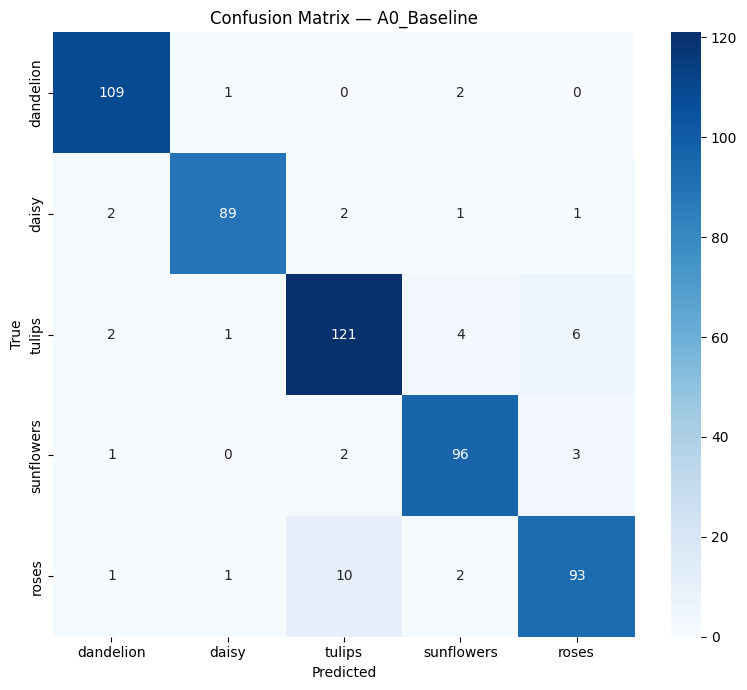

In [168]:
# Confusion matrix

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

y_true_cm = np.asarray(y_true).reshape(-1)
y_pred_cm = np.asarray(y_pred)

# Convert predicted probabilities to class indices if necessary
if y_pred_cm.ndim > 1:
    y_pred_cm = np.argmax(y_pred_cm, axis=1)
else:
    y_pred_cm = y_pred_cm.reshape(-1)

assert len(y_true_cm) == len(y_pred_cm), (
    f"Label count ({len(y_true_cm)}) and prediction count "
    f"({len(y_pred_cm)}) do not match."
)

cm = confusion_matrix(
    y_true_cm,
    y_pred_cm,
    labels=np.arange(len(CLASS_NAMES))
)

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=ax
)

ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

os.makedirs(OUTPUT_DIR, exist_ok=True)
fig.savefig(
    os.path.join(OUTPUT_DIR, "final_selected_model_confusion_matrix.png"),
    dpi=160,
    bbox_inches="tight"
)
plt.close(fig)

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 86 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


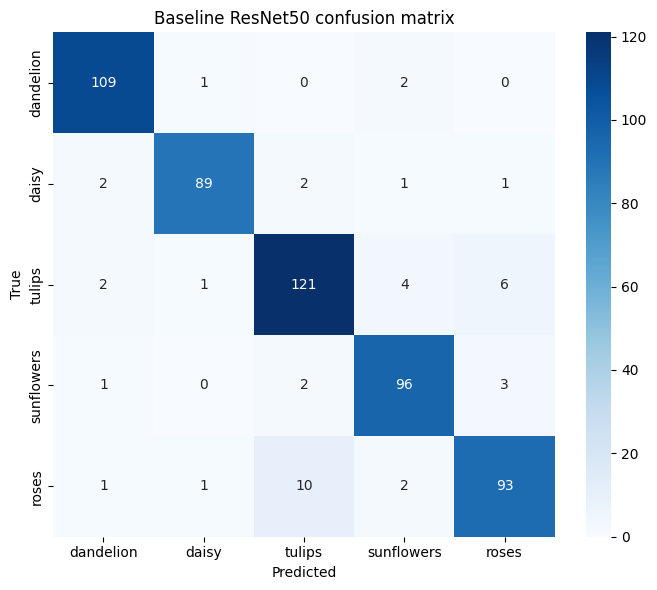

In [169]:
# Required baseline ResNet50 confusion matrix (Section 25)
baseline_weight_path = find_weights_file("A0_Baseline")
if baseline_weight_path and os.path.exists(baseline_weight_path):
    baseline_cm_model = build_resnet50_attention(attention_map={}, learning_rate=1e-3)
    baseline_cm_model.load_weights(baseline_weight_path)
    baseline_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds])
    baseline_probs = baseline_cm_model.predict(test_ds, verbose=0)
    baseline_pred = np.argmax(baseline_probs, axis=1)
    baseline_cm = confusion_matrix(baseline_true, baseline_pred, labels=np.arange(len(CLASS_NAMES)))
    plt.figure(figsize=(7, 6))
    sns.heatmap(baseline_cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.title("Baseline ResNet50 confusion matrix")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "required_baseline_confusion_matrix.png"), dpi=160)
    plt.show(); plt.close()
else:
    print("Baseline weights not found; run A0_Baseline before plotting its confusion matrix.")


In [ ]:
# Duplicate confusion-matrix fragment removed; complete plot is generated in cell 158.


In [ ]:
# Duplicate confusion-matrix fragment removed; complete plot is generated in cell 158.


In [ ]:
# Duplicate confusion-matrix fragment removed; complete plot is generated in cell 158.


In [170]:
pd.DataFrame([{
    "Selected model": best_name, "Test loss": float(test_loss),
    "Test accuracy": float(test_acc), "Macro precision": float(precision),
    "Macro recall": float(recall), "Macro F1": float(f1)
}]).to_csv(os.path.join(OUTPUT_DIR, "final_test_metrics.csv"), index=False)

In [171]:
# 13. Save all plots, tables, and weights into one ZIP file

# All per-model plots, model weights, and CSV result tables are in OUTPUT_DIR.
zip_path = shutil.make_archive("/kaggle/working/DL_Lab_8_All_Attention_Outputs", "zip", OUTPUT_DIR)


In [172]:
print("Created archive:", zip_path)


Created archive: /kaggle/working/DL_Lab_8_All_Attention_Outputs.zip


In [173]:
print("Number of output files:", len(os.listdir(OUTPUT_DIR)))

Number of output files: 130


In [174]:
# 14. Select one representative test image
import ast
import glob
from sklearn.metrics import confusion_matrix
import seaborn as sns

viz_batch, viz_labels = next(iter(test_ds))
viz_image = viz_batch[0:1]
viz_label = int(np.argmax(viz_labels[0].numpy()))
print("True class:", CLASS_NAMES[viz_label])
print("Image tensor:", viz_image.shape)

True class: daisy
Image tensor: (1, 224, 224, 3)


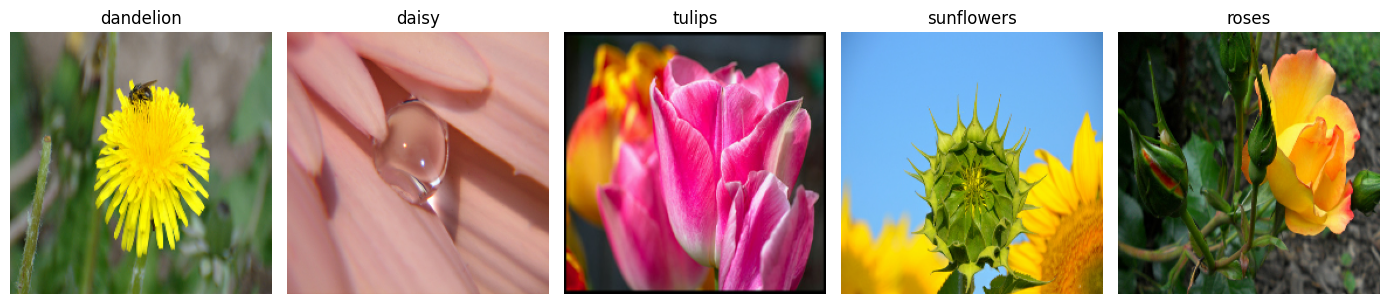

In [175]:
# 15. Display sample images from all five classes
class_samples = {}
for image_batch, label_batch in test_ds:
    for image, label in zip(image_batch, label_batch):
        class_id = int(np.argmax(label.numpy()))
        if class_id not in class_samples:
            class_samples[class_id] = image.numpy()
        if len(class_samples) == len(CLASS_NAMES):
            break
    if len(class_samples) == len(CLASS_NAMES):
        break

plt.figure(figsize=(14, 4))
for class_id, class_name in enumerate(CLASS_NAMES):
    plt.subplot(1, len(CLASS_NAMES), class_id + 1)
    sample = class_samples[class_id].astype(np.float32)
    sample = np.clip((sample + np.array([103.939, 116.779, 123.680], dtype=np.float32))[..., ::-1] / 255.0, 0.0, 1.0)
    plt.imshow(sample)
    plt.title(class_name); plt.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "required_01_samples_all_classes.png"), dpi=160, bbox_inches="tight")
plt.show(); plt.close()


In [176]:
# 16. Helper functions for attention visualization

def display_image_tensor(x):
    """Convert ResNet50 preprocess_input (BGR, mean-subtracted) back to RGB [0,1]."""
    x = np.asarray(x, dtype=np.float32)
    if x.ndim == 4:
        x = x[0]
    # ResNet50 preprocess_input uses BGR order and ImageNet mean subtraction.
    bgr = x + np.array([103.939, 116.779, 123.680], dtype=np.float32)
    rgb = bgr[..., ::-1] / 255.0
    return np.clip(rgb, 0.0, 1.0)

def feature_map_image(feature_tensor):
    fmap = feature_tensor[0].numpy()
    fmap = np.mean(np.abs(fmap), axis=-1)
    return fmap / (fmap.max() + 1e-8)

def find_weights_file(experiment_name):
    safe = experiment_name.replace("/", "_").replace(" ", "_").replace("+", "plus")
    path = os.path.join(OUTPUT_DIR, f"{safe}.weights.h5")
    return path if os.path.exists(path) else None

def load_viz_model(experiment_name, attention_map):
    weight_path = find_weights_file(experiment_name)
    if weight_path is None:
        print("Weights not found; run this experiment first:", experiment_name)
        return None
    model = build_resnet50_attention(attention_map=attention_map, learning_rate=1e-3)
    model.load_weights(weight_path)
    return model

def build_connected_attention_probe(model, position, kind, kernel_size=7):
    """Build probes from tensors connected to this model's actual forward graph."""
    feature_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name=f"probe_{position}_input")
    x = feature_input
    for layer_name in ["conv1_pad", "conv1_conv", "conv1_bn", "conv1_relu", "pool1_pad", "pool1_pool"]:
        x = model.get_layer(layer_name)(x)
    target_stage = {"P2": 3, "P3": 4, "P4": 5}[position]
    stage_blocks = {2: 3, 3: 4, 4: 6, 5: 3}
    for stage, block_count in stage_blocks.items():
        for block in range(1, block_count + 1):
            prefix = f"conv{stage}_block{block}"
            shortcut = x
            for suffix in ["1_conv", "1_bn", "1_relu", "2_conv", "2_bn", "2_relu", "3_conv", "3_bn"]:
                x = model.get_layer(f"{prefix}_{suffix}")(x)
            if block == 1:
                shortcut = model.get_layer(f"{prefix}_0_conv")(shortcut)
                shortcut = model.get_layer(f"{prefix}_0_bn")(shortcut)
            x = model.get_layer(f"{prefix}_add")([x, shortcut])
            x = model.get_layer(f"{prefix}_out")(x)
        if stage == target_stage:
            before = x
            break
    base_name = f"{position.lower()}_{kind}"
    extras = {}
    if kind in ("channel", "channel_spatial", "cbam", "combined"):
        ch_name = base_name if kind == "channel" else f"{base_name}_channel"
        gap = model.get_layer(f"{ch_name}_gap")(x)
        red = model.get_layer(f"{ch_name}_reduce")(gap)
        weights = model.get_layer(f"{ch_name}_expand")(red)
        x = model.get_layer(f"{ch_name}_scale")([x, weights])
        extras["channel_weights"] = weights
    if kind in ("spatial", "channel_spatial", "spatial_channel", "cbam", "combined"):
        sp_name = base_name if kind == "spatial" else f"{base_name}_spatial"
        avg = model.get_layer(f"{sp_name}_avg")(x)
        mx = model.get_layer(f"{sp_name}_max")(x)
        concat = model.get_layer(f"{sp_name}_concat")([avg, mx])
        spatial_map = model.get_layer(f"{sp_name}_map")(concat)
        x = model.get_layer(f"{sp_name}_scale")([x, spatial_map])
        extras["spatial_map"] = spatial_map
    if kind == "self":
        n = int(x.shape[1]) * int(x.shape[2]); c = int(x.shape[-1])
        d = max(min(c // 8, 128), 16)
        flat = model.get_layer(f"{base_name}_flatten")(x)
        q = model.get_layer(f"{base_name}_query")(flat)
        k = model.get_layer(f"{base_name}_key")(flat)
        v = model.get_layer(f"{base_name}_value")(flat)
        scores = model.get_layer(f"{base_name}_scores")([q, k])
        weights = model.get_layer(f"{base_name}_weights")(scores)
        extras["self_weights"] = weights
        attended = model.get_layer(f"{base_name}_attended")([weights, v])
        attended = model.get_layer(f"{base_name}_project")(attended)
        attended = model.get_layer(f"{base_name}_reshape")(attended)
        x = model.get_layer(f"{base_name}_residual")([x, attended])
    after = x
    return keras.Model(feature_input, {"before": before, "after": after, **extras})


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 94 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


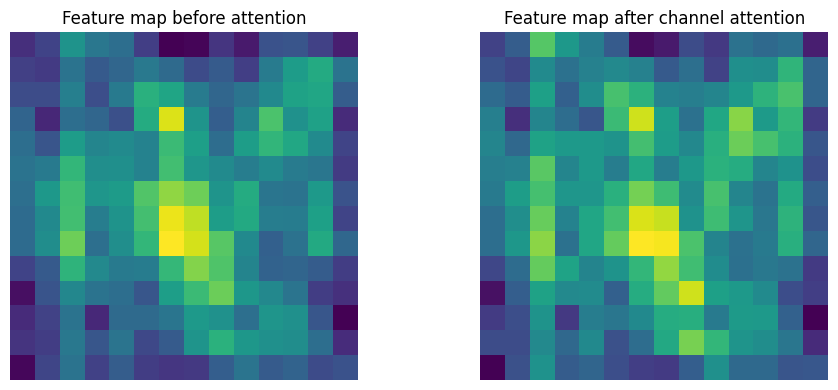

In [177]:
# 17. Plot feature maps before and after channel attention
channel_model = load_viz_model("A1_Channel_P3", {"P3": "channel"})
if channel_model is not None:
    probe = build_connected_attention_probe(channel_model, "P3", "channel")
    probe_out = probe(viz_image, training=False)
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1); plt.imshow(feature_map_image(probe_out["before"]), cmap="viridis")
    plt.title("Feature map before attention"); plt.axis("off")
    plt.subplot(1, 2, 2); plt.imshow(feature_map_image(probe_out["after"]), cmap="viridis")
    plt.title("Feature map after channel attention"); plt.axis("off")
    plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "required_05_10_feature_maps_channel.png"), dpi=160, bbox_inches="tight")
    plt.show(); plt.close()


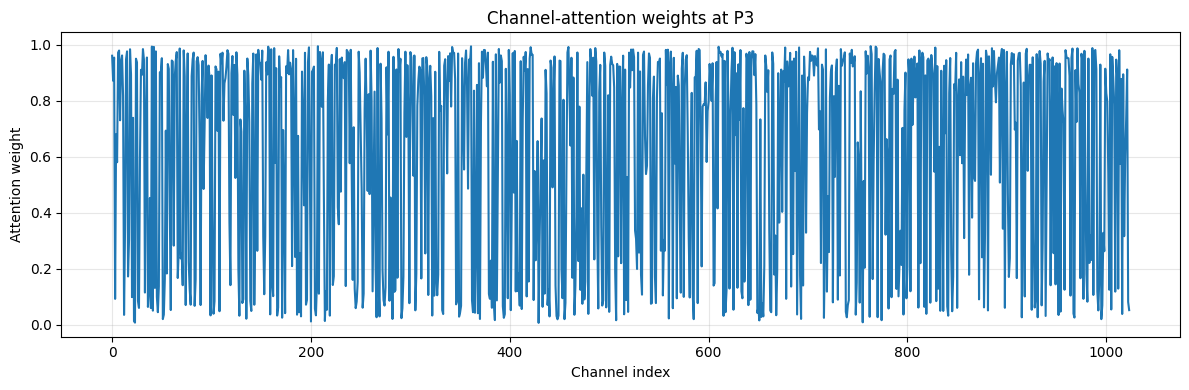

In [178]:
# 18. Plot channel-attention weights
if channel_model is not None:
    probe = build_connected_attention_probe(channel_model, "P3", "channel")
    weights = probe(viz_image, training=False)["channel_weights"].numpy().reshape(-1)
    plt.figure(figsize=(12, 4)); plt.plot(np.arange(len(weights)), weights)
    plt.xlabel("Channel index"); plt.ylabel("Attention weight"); plt.title("Channel-attention weights at P3")
    plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "required_06_channel_attention_weights.png"), dpi=160, bbox_inches="tight")
    plt.show(); plt.close()


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 88 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


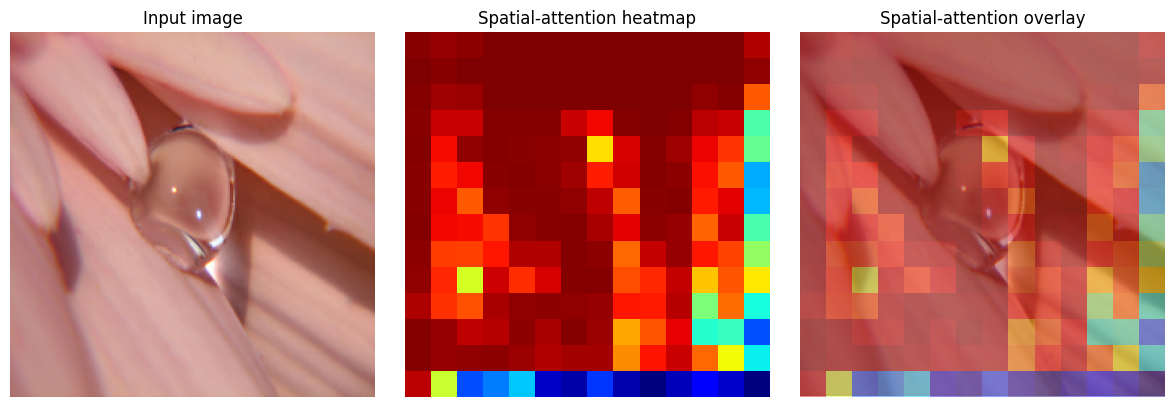

In [179]:
# 19. Plot spatial-attention heatmap and overlay
spatial_model = load_viz_model("A2_Spatial_P3", {"P3": "spatial"})
if spatial_model is not None:
    probe = build_connected_attention_probe(spatial_model, "P3", "spatial")
    spatial_map = probe(viz_image, training=False)["spatial_map"].numpy()[0, :, :, 0]
    original_image = display_image_tensor(viz_image.numpy())
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 3, 1); plt.imshow(original_image); plt.title("Input image"); plt.axis("off")
    plt.subplot(1, 3, 2); plt.imshow(spatial_map, cmap="jet"); plt.title("Spatial-attention heatmap"); plt.axis("off")
    plt.subplot(1, 3, 3); plt.imshow(original_image); plt.imshow(spatial_map, cmap="jet", alpha=0.45, extent=(0, original_image.shape[1], original_image.shape[0], 0)); plt.title("Spatial-attention overlay"); plt.axis("off")
    plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "required_07_08_spatial_heatmap_overlay.png"), dpi=160, bbox_inches="tight")
    plt.show(); plt.close()


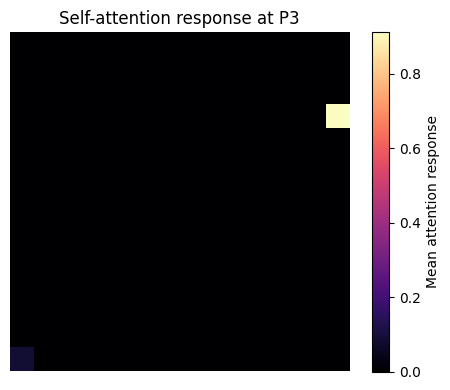

In [180]:
# 20. Plot self-attention response
self_model = load_viz_model("A4_SelfAttention_P3", {"P3": "self"})
if self_model is not None:
    probe = build_connected_attention_probe(self_model, "P3", "self")
    self_weights = probe(viz_image, training=False)["self_weights"].numpy()[0]
    response = np.mean(self_weights, axis=0).reshape(14, 14)
    plt.figure(figsize=(5, 4)); plt.imshow(response, cmap="magma"); plt.colorbar(label="Mean attention response")
    plt.title("Self-attention response at P3"); plt.axis("off"); plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "required_09_self_attention_response.png"), dpi=160, bbox_inches="tight")
    plt.show(); plt.close()


In [181]:
# 21. Generate Grad-CAM from connected feature maps captured during model construction
def make_gradcam(attention_map, weights_path, image, kernel_size=7, dropout_rate=0.3):
    grad_model = build_resnet50_attention(
        attention_map=attention_map,
        kernel_size=kernel_size,
        dropout_rate=dropout_rate,
        learning_rate=1e-5,
        return_gradcam=True
    )
    # Load trained model weights; optimizer state is intentionally not restored.
    grad_model.load_weights(weights_path, skip_mismatch=False)

    with tf.GradientTape() as tape:
        feature_maps, predictions = grad_model(image, training=False)
        class_index = tf.argmax(predictions[0])
        class_score = predictions[:, class_index]

    gradients = tape.gradient(class_score, feature_maps)
    if gradients is None:
        raise ValueError("Grad-CAM gradients are None; captured feature tensor is not connected.")

    weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
    heatmap = tf.reduce_sum(feature_maps * weights, axis=-1)
    heatmap = tf.nn.relu(heatmap)
    heatmap = heatmap / (tf.reduce_max(heatmap, axis=(1, 2), keepdims=True) + 1e-8)
    heatmap = tf.image.resize(heatmap[..., tf.newaxis], (IMG_SIZE, IMG_SIZE))[0, :, :, 0].numpy()
    return heatmap, int(class_index.numpy()), predictions.numpy()[0]


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 86 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


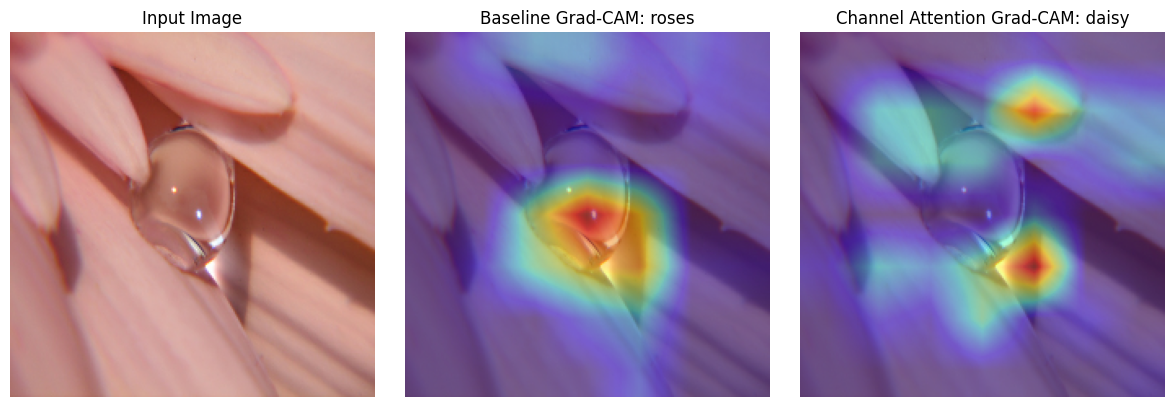

In [182]:
# 22. Plot baseline and channel-attention Grad-CAM
baseline_row = results_df.loc[results_df["Experiment"] == "A0_Baseline"].iloc[0]
channel_row = results_df.loc[results_df["Experiment"] == "A1_Channel_P3"].iloc[0]

baseline_cam, baseline_class, baseline_probs = make_gradcam(
    {}, baseline_row["Weights"], viz_image,
    kernel_size=int(baseline_row["Kernel"]), dropout_rate=float(baseline_row["Dropout"])
)
channel_cam, channel_class, channel_probs = make_gradcam(
    {"P3": "channel"}, channel_row["Weights"], viz_image,
    kernel_size=int(channel_row["Kernel"]), dropout_rate=float(channel_row["Dropout"])
)

input_image = display_image_tensor(viz_image.numpy())
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(input_image)
plt.title("Input Image")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(input_image)
plt.imshow(baseline_cam, cmap="jet", alpha=0.45)
plt.title(f"Baseline Grad-CAM: {CLASS_NAMES[baseline_class]}")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(input_image)
plt.imshow(channel_cam, cmap="jet", alpha=0.45)
plt.title(f"Channel Attention Grad-CAM: {CLASS_NAMES[channel_class]}")
plt.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "required_11_12_baseline_attention_gradcam.png"), dpi=160, bbox_inches="tight")
plt.show()
plt.close()


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 96 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


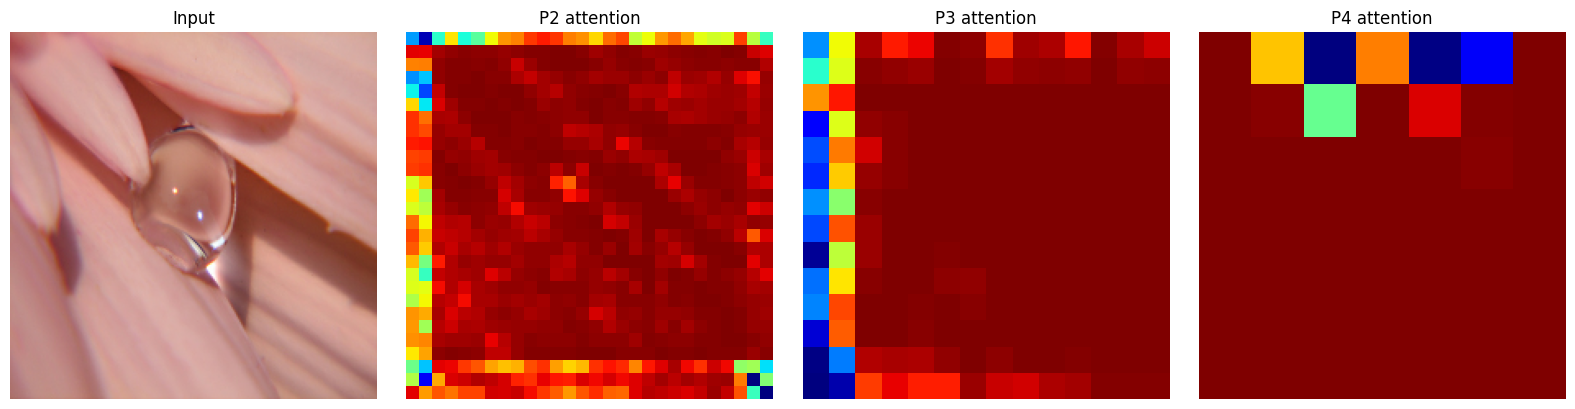

In [183]:
# 22. Plot spatial attention maps at P2, P3, and P4
position_models = [
    ("P2", "B1_ChannelSpatial_P2", {"P2": "channel_spatial"}),
    ("P3", "B2_ChannelSpatial_P3", {"P3": "channel_spatial"}),
    ("P4", "B3_ChannelSpatial_P4", {"P4": "channel_spatial"}),
]
position_maps = {}
for position, experiment_name, amap in position_models:
    position_model = load_viz_model(experiment_name, amap)
    if position_model is None:
        continue
    try:
        probe = build_connected_attention_probe(position_model, position, "channel_spatial")
        position_maps[position] = probe(viz_image, training=False)["spatial_map"].numpy()[0, :, :, 0]
    except Exception as error:
        print("Could not extract", position, "attention map:", error)

if position_maps:
    cols = len(position_maps) + 1
    plt.figure(figsize=(4 * cols, 4))
    plt.subplot(1, cols, 1); plt.imshow(display_image_tensor(viz_image.numpy())); plt.title("Input"); plt.axis("off")
    for i, (position, amap) in enumerate(position_maps.items(), start=2):
        plt.subplot(1, cols, i); plt.imshow(amap, cmap="jet"); plt.title(f"{position} attention"); plt.axis("off")
    plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "required_13_attention_maps_P2_P3_P4.png"), dpi=160, bbox_inches="tight")
    plt.show(); plt.close()
else:
    print("No P2/P3/P4 maps generated. Check that B1, B2, and B3 weights exist in OUTPUT_DIR.")


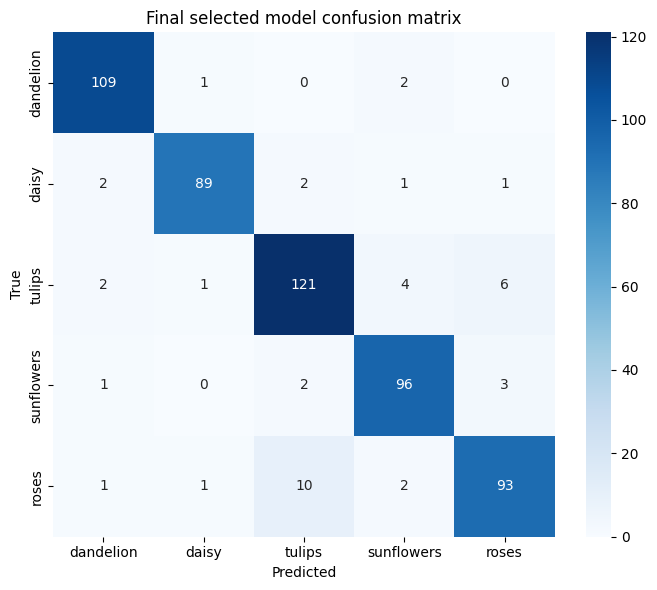

In [184]:
# 23. Generate final confusion matrix from actual test predictions
if "best_model" in globals():
    cm_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds])
    cm_prob = best_model.predict(test_ds, verbose=0)
    cm_pred = np.argmax(cm_prob, axis=1)
    cm_actual = confusion_matrix(cm_true, cm_pred, labels=np.arange(len(CLASS_NAMES)))
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm_actual, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Final selected model confusion matrix")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "required_04_confusion_matrix.png"), dpi=160)
    plt.show()
else:
    print("Run the final model evaluation cells first.")

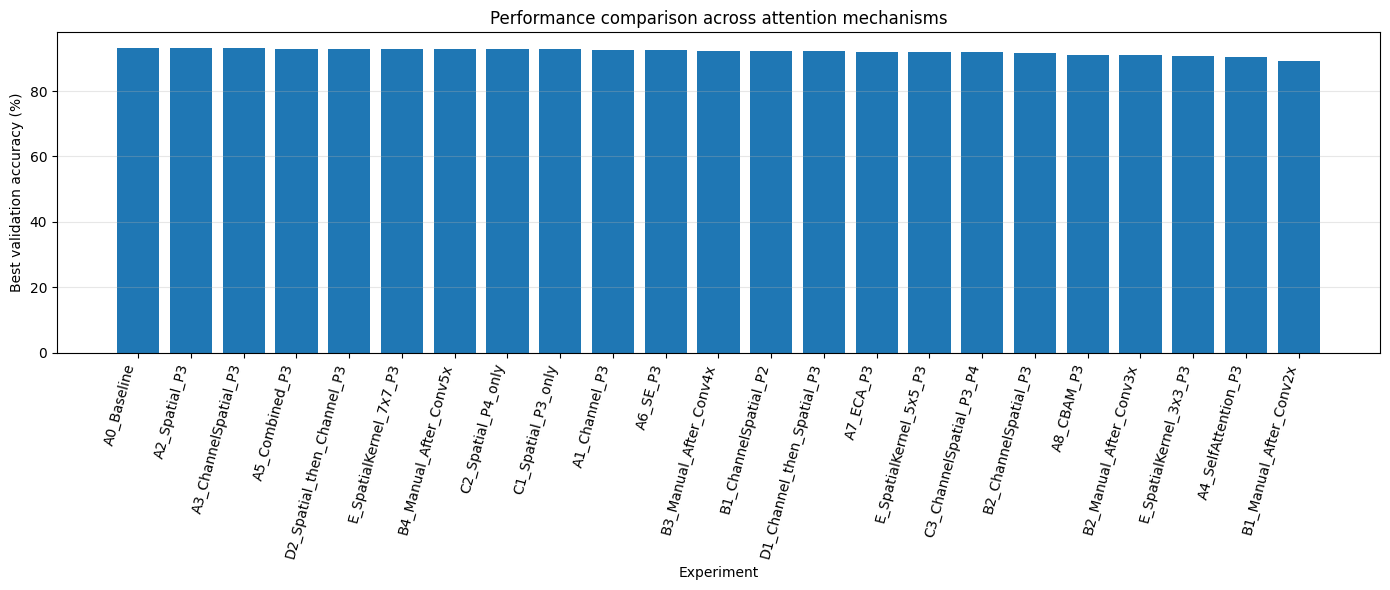

In [185]:
# 24. Compile performance comparison across completed experiments
if "records" in globals() and len(records) > 0:
    results_df = pd.DataFrame(records)
    results_df.to_csv(os.path.join(OUTPUT_DIR, "all_experiment_results.csv"), index=False)
    if "Fine-tuning best val accuracy" in results_df.columns:
        plot_df = results_df.dropna(subset=["Fine-tuning best val accuracy"]).sort_values(
            "Fine-tuning best val accuracy", ascending=False
        )
        plt.figure(figsize=(14, 6))
        plt.bar(plot_df["Experiment"], plot_df["Fine-tuning best val accuracy"] * 100)
        plt.ylabel("Best validation accuracy (%)")
        plt.xlabel("Experiment")
        plt.title("Performance comparison across attention mechanisms")
        plt.xticks(rotation=75, ha="right")
        plt.grid(axis="y", alpha=0.3)
        plt.tight_layout()
        plt.savefig(os.path.join(OUTPUT_DIR, "required_14_attention_performance_comparison.png"), dpi=160)
        plt.show()
else:
    print("Run the experiment cells first to compile actual results.")

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 86 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


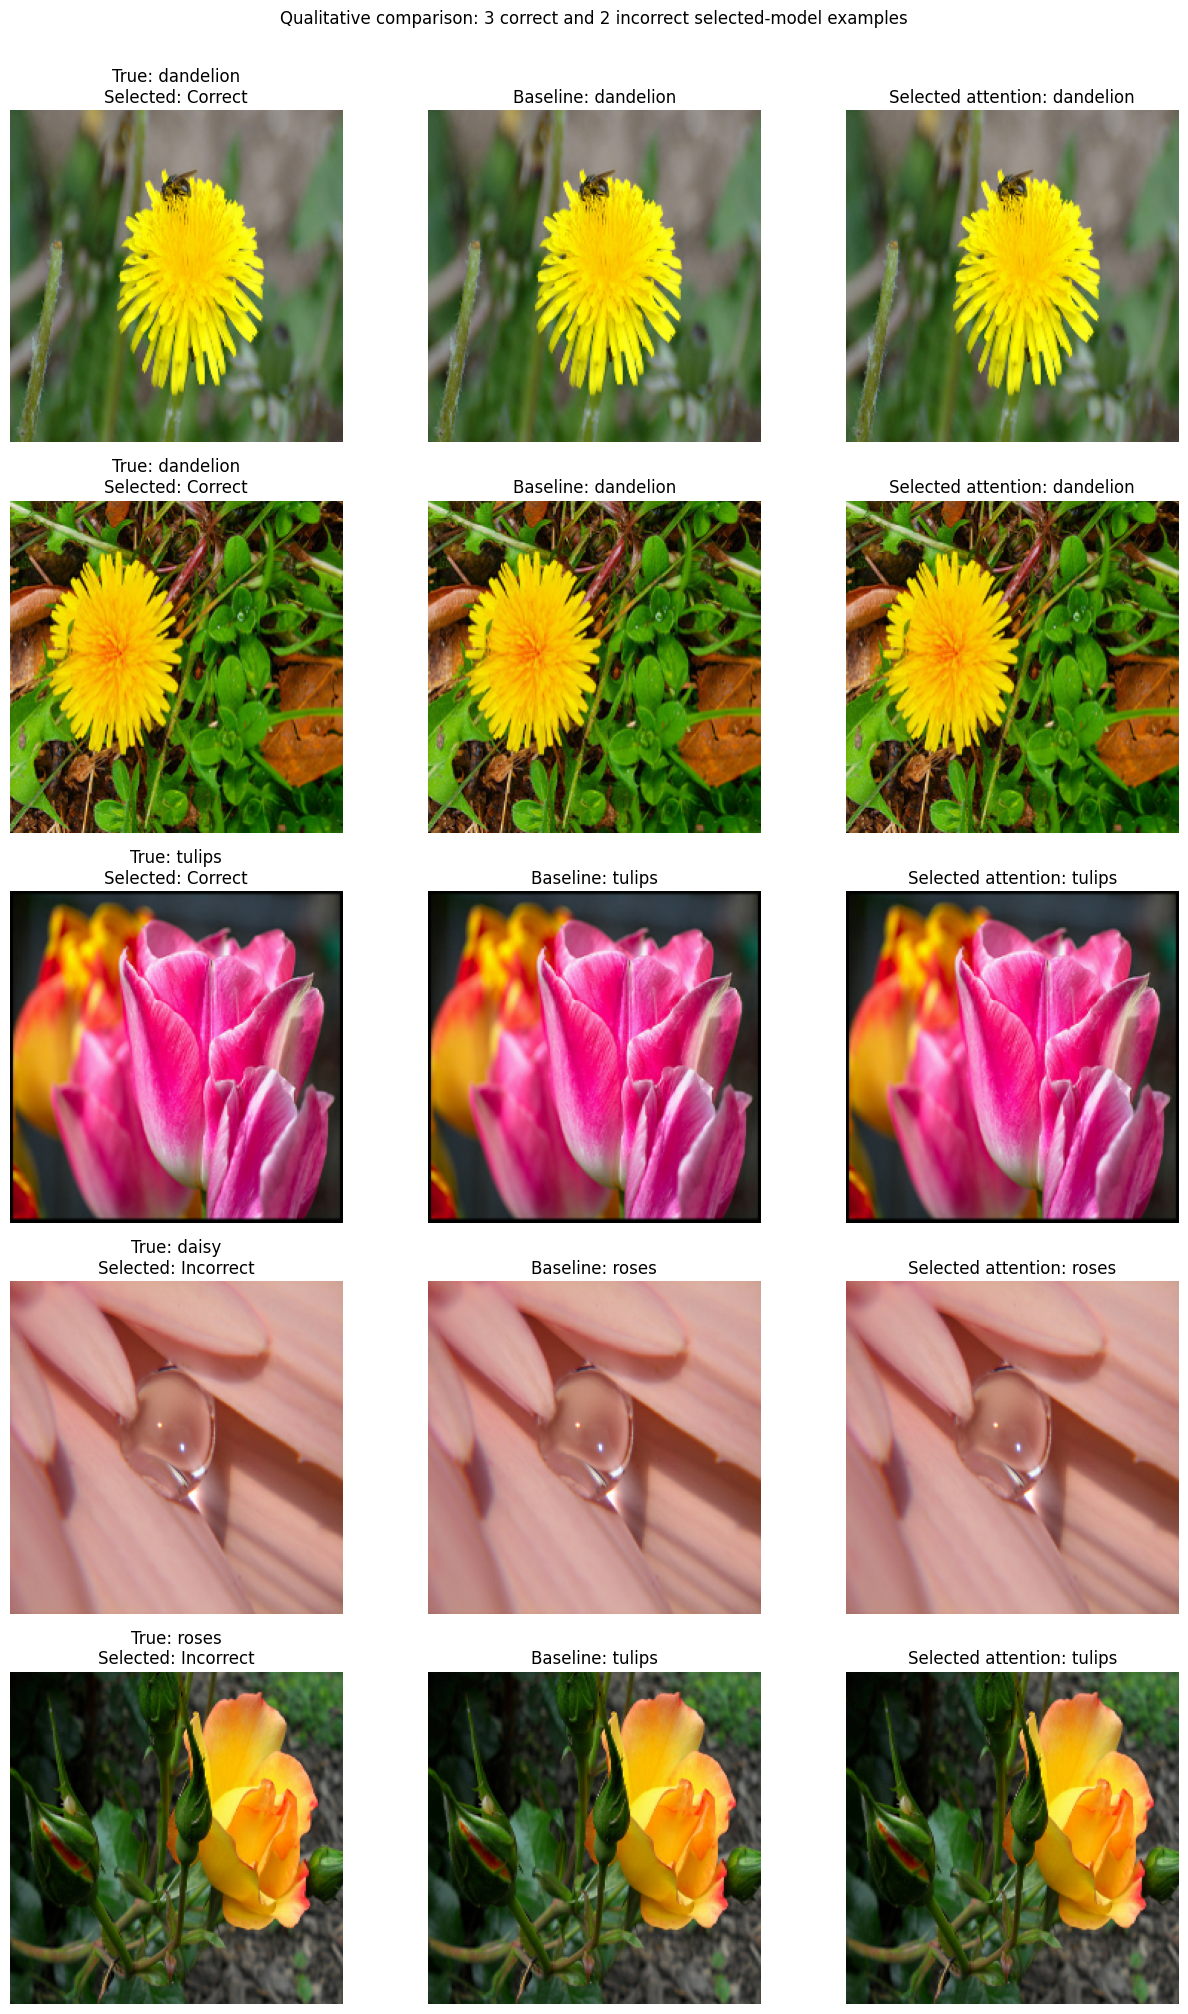

,Test index,True class,Baseline prediction,Selected model prediction,Selected model correct
0,1,dandelion,dandelion,dandelion,True
1,2,dandelion,dandelion,dandelion,True
2,3,tulips,tulips,tulips,True
3,0,daisy,roses,roses,False
4,7,roses,tulips,tulips,False


In [186]:
# Required Section 30: select 3 correctly classified and 2 incorrectly classified test images
# Compare the same images using the baseline and validation-selected attention model.

baseline_path_for_qual = find_weights_file("A0_Baseline")
if baseline_path_for_qual and os.path.exists(baseline_path_for_qual) and os.path.exists(best_weights):
    baseline_qual_model = build_resnet50_attention(attention_map={}, learning_rate=1e-3)
    baseline_qual_model.load_weights(baseline_path_for_qual)
    selected_qual_model = build_resnet50_attention(
        attention_map=best_map, kernel_size=best_kernel, dropout_rate=best_dropout, learning_rate=1e-3
    )
    selected_qual_model.load_weights(best_weights)

    all_images, all_labels = [], []
    for bx, by in test_ds:
        all_images.append(bx.numpy())
        all_labels.append(np.argmax(by.numpy(), axis=1))
    all_images = np.concatenate(all_images, axis=0)
    all_labels = np.concatenate(all_labels, axis=0)
    baseline_pred_all = np.argmax(baseline_qual_model.predict(all_images, batch_size=BATCH_SIZE, verbose=0), axis=1)
    selected_pred_all = np.argmax(selected_qual_model.predict(all_images, batch_size=BATCH_SIZE, verbose=0), axis=1)

    # Correct/incorrect is defined against the selected model so the examples directly explain its behavior.
    correct_ids = np.flatnonzero(selected_pred_all == all_labels)[:3]
    incorrect_ids = np.flatnonzero(selected_pred_all != all_labels)[:2]
    chosen_ids = list(correct_ids) + list(incorrect_ids)
    if len(correct_ids) < 3 or len(incorrect_ids) < 2:
        print(f"Found {len(correct_ids)} correct and {len(incorrect_ids)} incorrect examples; expected 3 and 2.")
    if chosen_ids:
        fig, axes = plt.subplots(len(chosen_ids), 3, figsize=(13, 4 * len(chosen_ids)))
        if len(chosen_ids) == 1:
            axes = np.expand_dims(axes, axis=0)
        for row, idx in enumerate(chosen_ids):
            axes[row, 0].imshow(display_image_tensor(all_images[idx]))
            axes[row, 0].set_title(f"True: {CLASS_NAMES[all_labels[idx]]}\nSelected: {'Correct' if selected_pred_all[idx] == all_labels[idx] else 'Incorrect'}")
            axes[row, 1].imshow(display_image_tensor(all_images[idx]))
            axes[row, 1].set_title(f"Baseline: {CLASS_NAMES[baseline_pred_all[idx]]}")
            axes[row, 2].imshow(display_image_tensor(all_images[idx]))
            axes[row, 2].set_title(f"Selected attention: {CLASS_NAMES[selected_pred_all[idx]]}")
            for ax in axes[row]: ax.axis("off")
        plt.suptitle("Qualitative comparison: 3 correct and 2 incorrect selected-model examples", y=1.005)
        plt.tight_layout()
        plt.savefig(os.path.join(OUTPUT_DIR, "required_qualitative_3_correct_2_incorrect.png"), dpi=160, bbox_inches="tight")
        plt.show(); plt.close(fig)
        qualitative_df = pd.DataFrame({
            "Test index": chosen_ids,
            "True class": [CLASS_NAMES[all_labels[i]] for i in chosen_ids],
            "Baseline prediction": [CLASS_NAMES[baseline_pred_all[i]] for i in chosen_ids],
            "Selected model prediction": [CLASS_NAMES[selected_pred_all[i]] for i in chosen_ids],
            "Selected model correct": [bool(selected_pred_all[i] == all_labels[i]) for i in chosen_ids]
        })
        display(qualitative_df)
        qualitative_df.to_csv(os.path.join(OUTPUT_DIR, "required_qualitative_examples.csv"), index=False)
else:
    print("Run A0_Baseline and final selected-model evaluation first; required weights are missing.")


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 86 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 94 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 88 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved op

,Experiment,Test accuracy,Test macro precision,Test macro recall,Test macro F1,Total parameters,Inference ms/image (recorded),Weights
13,B3_Manual_After_Conv4x,0.932727,0.931883,0.934048,0.932856,23730215,29.416220,/kaggle/working/lab8_attention_outputs/B3_Manu...
19,D2_Spatial_then_Channel_P3,0.929091,0.934536,0.927936,0.930135,23730215,29.656873,/kaggle/working/lab8_attention_outputs/D2_Spat...
5,A5_Combined_P3,0.929091,0.930453,0.930002,0.930118,24254503,30.374126,/kaggle/working/lab8_attention_outputs/A5_Comb...
16,C2_Spatial_P4_only,0.927273,0.928819,0.926873,0.927362,24124519,29.672722,/kaggle/working/lab8_attention_outputs/C2_Spat...
15,C1_Spatial_P3_only,0.925455,0.927708,0.927096,0.927019,23730215,29.509220,/kaggle/working/lab8_attention_outputs/C1_Spat...
1,A1_Channel_P3,0.923636,0.925277,0.923981,0.924568,23730117,29.668882,/kaggle/working/lab8_attention_outputs/A1_Chan...
0,A0_Baseline,0.923636,0.925742,0.924675,0.925021,23597957,29.907274,/kaggle/working/lab8_attention_outputs/A0_Base...
21,E_SpatialKernel_5x5_P3,0.923636,0.924286,0.924164,0.924140,23598007,29.340770,/kaggle/working/lab8_attention_outputs/E_Spati...
6,A6_SE_P3,0.923636,0.926779,0.922776,0.923883,23730117,29.770733,/kaggle/working/lab8_attention_outputs/A6_SE_P...
22,E_SpatialKernel_7x7_P3,0.921818,0.921289,0.924799,0.922446,23598055,29.173237,/kaggle/working/lab8_attention_outputs/E_Spati...


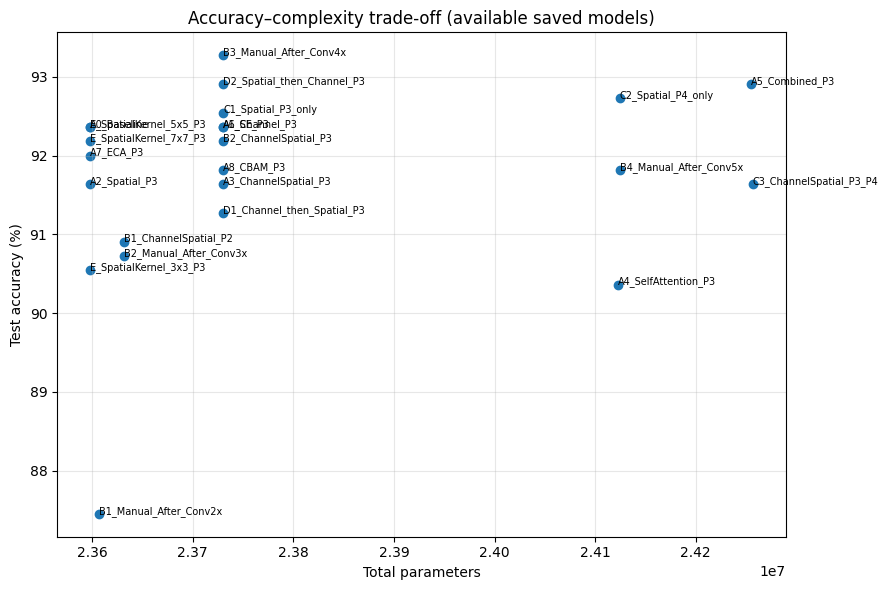

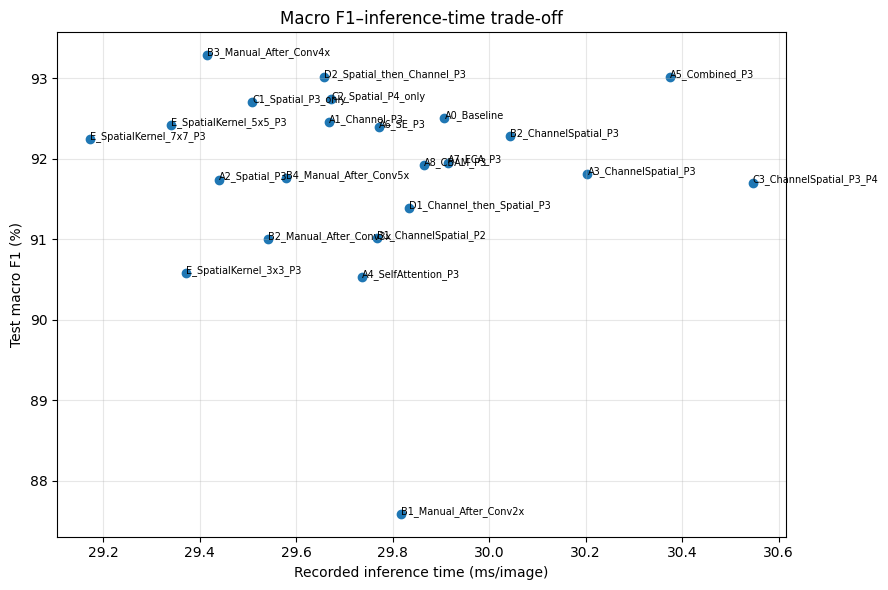

Selected-model classification report:
               precision    recall  f1-score   support

   dandelion       0.95      0.97      0.96       112
       daisy       0.97      0.94      0.95        95
      tulips       0.90      0.90      0.90       134
  sunflowers       0.91      0.94      0.93       102
       roses       0.90      0.87      0.89       107

    accuracy                           0.92       550
   macro avg       0.93      0.92      0.93       550
weighted avg       0.92      0.92      0.92       550



In [187]:
# 23–24. Report-ready held-out metrics and comparison plots (evaluation only; no training)
# Evaluates available saved weights on the fixed test split. It does not fit or retrain models.
import ast
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report

report_rows = []
true_test = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds])

# Combine existing experiment records with manual-aligned position records.
_report_records = list(records) if "records" in globals() else []
for _manual_name in ["B1_Manual_After_Conv2x", "B2_Manual_After_Conv3x", "B3_Manual_After_Conv4x", "B4_Manual_After_Conv5x"]:
    _matches = [r for r in _report_records if r.get("Experiment") == _manual_name]
    if not _matches:
        _path = os.path.join(OUTPUT_DIR, f"{_manual_name}.weights.h5")
        if os.path.exists(_path):
            # The saved manual-aligned result CSV is preferred when present.
            _csv = os.path.join(OUTPUT_DIR, "all_experiment_results.csv")
            if os.path.exists(_csv):
                _df = pd.read_csv(_csv)
                _m = _df[_df["Experiment"] == _manual_name]
                if len(_m): _report_records.extend(_m.to_dict("records"))

_seen = set()
for rec in _report_records:
    exp = str(rec.get("Experiment", ""))
    if not exp or exp in _seen:
        continue
    _seen.add(exp)
    weights = rec.get("Weights", "")
    if not isinstance(weights, str) or not os.path.exists(weights):
        # Locate weights by experiment name without training.
        weights = find_weights_file(exp) if "find_weights_file" in globals() else None
    if not weights or not os.path.exists(weights):
        continue
    amap_raw = rec.get("Attention map", "{}")
    try:
        amap = ast.literal_eval(amap_raw) if isinstance(amap_raw, str) else (amap_raw or {})
    except Exception:
        amap = {}
    # Manual-aligned records use an after_conv stage key; build their dedicated graph.
    if exp.startswith(("B1_Manual_", "B2_Manual_", "B3_Manual_", "B4_Manual_")):
        stage = {"B1_Manual_After_Conv2x":2, "B2_Manual_After_Conv3x":3,
                 "B3_Manual_After_Conv4x":4, "B4_Manual_After_Conv5x":5}[exp]
        model = build_resnet50_attention_by_manual_stage(
            stage, kernel_size=int(rec.get("Kernel", 7)), dropout_rate=float(rec.get("Dropout", 0.3)),
            learning_rate=1e-5
        )
    else:
        model = build_resnet50_attention(
            attention_map=amap, kernel_size=int(rec.get("Kernel", 7)),
            dropout_rate=float(rec.get("Dropout", 0.3)), learning_rate=1e-5
        )
    try:
        model.load_weights(weights)
        probs = model.predict(test_ds, verbose=0)
        pred = np.argmax(probs, axis=1)
        precision, recall, macro_f1, _ = precision_recall_fscore_support(
            true_test, pred, average="macro", zero_division=0
        )
        report_rows.append({
            "Experiment": exp,
            "Test accuracy": accuracy_score(true_test, pred),
            "Test macro precision": precision,
            "Test macro recall": recall,
            "Test macro F1": macro_f1,
            "Total parameters": int(model.count_params()),
            "Inference ms/image (recorded)": rec.get("Inference ms/image", np.nan),
            "Weights": weights,
        })
    except Exception as e:
        print(f"Skipped test evaluation for {exp}: {e}")
    finally:
        del model
        keras.backend.clear_session()
        gc.collect()

if report_rows:
    test_results_df = pd.DataFrame(report_rows).sort_values("Test accuracy", ascending=False)
    test_results_path = os.path.join(OUTPUT_DIR, "held_out_test_metrics_available_models.csv")
    test_results_df.to_csv(test_results_path, index=False)
    display(test_results_df)

    # Accuracy versus model complexity
    plt.figure(figsize=(9, 6))
    plt.scatter(test_results_df["Total parameters"], test_results_df["Test accuracy"] * 100)
    for _, row in test_results_df.iterrows():
        plt.annotate(row["Experiment"], (row["Total parameters"], row["Test accuracy"] * 100), fontsize=7)
    plt.xlabel("Total parameters"); plt.ylabel("Test accuracy (%)")
    plt.title("Accuracy–complexity trade-off (available saved models)")
    plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "required_accuracy_vs_parameters.png"), dpi=160, bbox_inches="tight")
    plt.show(); plt.close()

    # Macro F1 versus inference time where timing data is available
    _lat = test_results_df.dropna(subset=["Inference ms/image (recorded)"])
    if len(_lat):
        plt.figure(figsize=(9, 6))
        plt.scatter(_lat["Inference ms/image (recorded)"], _lat["Test macro F1"] * 100)
        for _, row in _lat.iterrows():
            plt.annotate(row["Experiment"], (row["Inference ms/image (recorded)"], row["Test macro F1"] * 100), fontsize=7)
        plt.xlabel("Recorded inference time (ms/image)"); plt.ylabel("Test macro F1 (%)")
        plt.title("Macro F1–inference-time trade-off")
        plt.grid(alpha=0.3); plt.tight_layout()
        plt.savefig(os.path.join(OUTPUT_DIR, "required_macro_f1_vs_inference_time.png"), dpi=160, bbox_inches="tight")
        plt.show(); plt.close()
else:
    print("No saved experiment weights were found for the report-ready test comparison. No models were trained by this cell.")

# Export per-class report for the selected model when available.
if "best_model" in globals():
    _best_probs = best_model.predict(test_ds, verbose=0)
    _best_pred = np.argmax(_best_probs, axis=1)
    _report_text = classification_report(true_test, _best_pred, target_names=CLASS_NAMES, zero_division=0)
    print("Selected-model classification report:\n", _report_text)
    with open(os.path.join(OUTPUT_DIR, "selected_model_classification_report.txt"), "w", encoding="utf-8") as f:
        f.write(_report_text)


In [ ]:
# 25. Save all generated visualizations
visualization_zip = shutil.make_archive(
    os.path.join(os.getcwd(), "DL_Lab_8_Required_Visualizations"),
    "zip",
    OUTPUT_DIR
)
print("Saved outputs to:", OUTPUT_DIR)
print("Visualization archive:", visualization_zip)
print("Generated PNG files:", len(glob.glob(os.path.join(OUTPUT_DIR, "*.png"))))
